# Reproduction notebook — *Inferring the Cause of Image–Report Disagreement in Chest Radiography*

This single notebook regenerates every **executed** result in the manuscript (IEEE draft, revised-6, 24 pages). Nothing in it uses real patient data except the optional case-note run in Part B; every recovery number comes from a semi-synthetic generator with a known, injected cause.

| Part | Manuscript content | Notebook section |
|---|---|---|
| A1–A5 | Generator (Sec. III-B1), views V1–V3, EM latent-class model (Sec. II-H), label-free naming (Remark 1) | building blocks |
| A6 | Single run, seed 0: Table V, Figs. 2–4, triage split (Sec. III-A) | single run |
| A7–A8 | 145-run extended study, stages A–G: Tables VI, XI–XVII, Figs. 5–11 (Secs. III-E, III-F, III-H) | extended study |
| A9 | Paired tests and effect sizes against per-seed majority baselines (Sec. III-H1, III-H2) | statistics |
| A10 | Component separation, covariance adequacy, restart sensitivity: Table XVIII (Sec. III-H3) | diagnostics |
| A11 | Posterior calibration and recoverability ceiling (Table XVI, bottom block) | calibration |
| A12 | Automatic comparison of the regenerated numbers with the values printed in the paper | check |
| B1–B9 | Full neural architecture of Sec. II (Eqs. 1–16): Algorithm 1 collapse, gradient check, $w_v\to1$ shortcut (eighth limitation), stabilization fixes of Table IV (Sec. II-G), and the **real-data column of Table IV** on 600 public chest radiographs with clinical case notes | neural architecture |
| C1–C3 | Public-data checks of Sec. III-D (Tables VIII–IX): IU/Open-I radiographs with radiology reports, NIH ChestX-ray14 expert reader reads. Runs when you supply the data | real-data checks |
| E0–E4 | Open or easier-access alternatives (no PhysioNet): ReXGradient-160K, NIH expert reads, injected errors on IU/ReXGradient reports, labelled with the open CheXbert/RadGraph models or a rule-based fallback | open alternatives |
| D1–D7 | The six datasets of Table VII — RadGraph, MIMIC-CXR(-JPG), VinDr-CXR, REFLACX, CheXpert, CorBenchX — each with the check that matches its role in the paper (Sec. III-C protocol). Credentialed or registered access; runs when you supply the data | Table VII datasets |

**Run modes.** `QUICK = True` runs a reduced version (a few seeds) in roughly 10–15 minutes to check that everything works; its numbers will not match the paper. `QUICK = False` runs the full protocol (about 45 minutes on one CPU core, plus about 30 minutes and a ~300 MB download for the real case-note run). Each extended-study stage appends to a CSV and is skipped if its CSV already exists, so an interrupted run can be resumed.

**Running on Kaggle.** Attach the datasets with "Add Input" and leave their paths as `None`: the configuration cell finds the ones that have a legitimate Kaggle copy and fills in the paths. These are [IU/Open-I](https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university), [NIH ChestX-ray14](https://www.kaggle.com/datasets/nih-chest-xrays/data), the [VinBigData competition copy of VinDr-CXR](https://www.kaggle.com/competitions/vinbigdata-chest-xray-abnormalities-detection) (join the competition first, and check its rules allow publication use) and, for testing only, a [CheXpert-small re-upload](https://www.kaggle.com/datasets/ashery/chexpert). The NIH Google expert labels and ReXGradient-160K are not on Kaggle; upload them as a *private* Kaggle dataset and they are found too. Do not attach Kaggle copies of MIMIC-CXR or other PhysioNet data, which break the data use agreement.

**Determinism.** Part A is deterministic given the seeds (one thread is enforced). Part B trains small PyTorch models; on a different machine or PyTorch version the neural numbers can differ in the second or third decimal place.

**Requirements.** Python 3.10+, numpy, pandas, scipy, scikit-learn, matplotlib, torch (CPU is enough), Pillow; pydicom for the VinDr-CXR images (Part D3) and optionally statsmodels; `nbformat` only to rebuild this notebook.

In [1]:
# ---- configuration -------------------------------------------------------------------------
QUICK = False            # True: reduced seeds for a fast check; False: full protocol of the paper
RUN_PART_A = True        # EM harness: Sections III-A, III-E, III-F, III-H
RUN_PART_B = True        # neural architecture: Sections II-F, II-G, eighth/ninth limitations
RUN_REAL_NOTES = True    # Part B9: 600 public chest-radiograph + case-note pairs (downloaded from GitHub)
OUT_DIR = "paper_outputs"            # all CSVs, JSONs and figures go here
REAL_DATA_DIR = "real_case_notes"    # where Part B9 stores the downloaded public data
# Part C (Section III-D public-data checks). These datasets cannot be redistributed: download them
# yourself and point the paths below at them; leave None to skip.
IU_DATA_DIR = None       # e.g. "/data/chest-xrays-indiana-university" (indiana_reports.csv, indiana_projections.csv, images)
                         # Kaggle: https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university
NIH_LABELS_DIR = None    # e.g. "/data/four_findings_expert_labels" (individual_readers.csv, validation/test_labels.csv)
NIH_IMAGES_DIR = None    # e.g. "/data/nih-chest-xrays" (ChestX-ray14 PNGs, any sub-folder layout)
                         # Kaggle (uploaded by the NIH): https://www.kaggle.com/datasets/nih-chest-xrays/data
# Part D (the datasets of Table VII). PhysioNet credentialed access (MIMIC-CXR, MIMIC-CXR-JPG, RadGraph,
# VinDr-CXR, REFLACX, CorBenchX) or Stanford AIMI registration (CheXpert), in your own name. Download them
# yourself and point the paths below at the unzipped folders; leave None to skip. Do not use unofficial
# re-uploads of credentialed data: the data use agreement forbids redistribution.
RUN_PART_D = True
RADGRAPH_DIR = None        # physionet.org/content/radgraph/1.0.0  (train/dev/test.json, MIMIC-CXR_graphs.json)
MIMIC_JPG_DIR = None       # physionet.org/content/mimic-cxr-jpg/2.1.0  (metadata, chexpert csv, files/pXX/...jpg)
MIMIC_REPORTS_DIR = None   # physionet.org/content/mimic-cxr/2.1.0  (unzipped mimic-cxr-reports.zip: files/pXX/pXXXXXXXX/sXXXXXXXX.txt)
MIMIC_PROVIDER_CSV = None  # cxr-provider-list.csv.gz from MIMIC-CXR 2.1.0 (reader axis, optional)
MIMIC_TARGET = "Pleural Effusion"   # finding the image view (V2) is trained on
MIMIC_N_CASES = 4000       # studies sampled for the image-based EM (D2c)
RUN_MIMIC_ARCH = True      # D2b: run the Section II architecture on MIMIC pairs (about 1 h on CPU)
VINDR_DIR = None           # physionet.org/content/vindr-cxr/1.0.0  (annotations/*.csv, train/*.dicom), or the authors' Kaggle
                           # competition copy (train.csv, train/*.dicom; join the competition and check its rules allow
                           # publication use): https://www.kaggle.com/competitions/vinbigdata-chest-xray-abnormalities-detection
VINDR_WITH_IMAGES = True   # D3d needs the DICOMs and pydicom
REFLACX_DIR = None         # physionet.org/content/reflacx-xray-localization/1.0.0  (unzipped main_data.zip)
CHEXPERT_DIR = None        # Stanford AIMI CheXpert-v1.0 or -v1.0-small (train.csv, valid.csv, images). A Kaggle re-upload by
                           # an individual (https://www.kaggle.com/datasets/ashery/chexpert) is fine for testing the code; for
                           # results in the paper, download from Stanford AIMI under its research use agreement.
CHEXPERT_WITH_IMAGES = True
CORBENCHX_PATH = None      # CorBenchX release (file or folder of CSV/JSON/JSONL); ReXErr-v1 also works
# Part E (open or easier-access alternatives, no PhysioNet credentialing). Leave None to skip.
REXGRADIENT_DIR = None         # huggingface.co/datasets/rajpurkarlab/ReXGradient-160K (licence click-through)
REXGRADIENT_IMAGES_DIR = None  # the extracted deid_png folder (cat deid_png.part* > deid_png.tar; tar -xf deid_png.tar)
REX_LABELER = "auto"           # "auto" (CheXbert if installed, else rules), "chexbert" or "lexical"
REX_MAX_LABEL = 20000          # studies labelled (whole patients); CheXbert is slow on CPU
RUN_ALT_ARCH = True            # E1b: the Section II architecture on ReXGradient pairs (about 1 h on CPU)
# E2 reuses NIH_LABELS_DIR, and E3 reuses IU_DATA_DIR (or the ReXGradient reports from E1).

import os
os.environ["OMP_NUM_THREADS"] = "1"      # set before numpy/torch import: deterministic and ~10x faster
os.environ["MKL_NUM_THREADS"] = "1"
RES = os.path.join(OUT_DIR, "results"); FIG = os.path.join(OUT_DIR, "figs"); HERE = OUT_DIR
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)

if QUICK:
    SEEDS = dict(A=range(2), B=range(100, 101), C=range(200, 201), D=range(300, 301),
                 E=range(400, 401), F=range(2), G=range(2))
    M4_SEEDS, M4_RESTARTS, REVIEW_SEEDS = range(2), 8, range(2)
else:   # exactly the protocol reported in the paper (145 runs)
    SEEDS = dict(A=range(10), B=range(100, 105), C=range(200, 205), D=range(300, 305),
                 E=range(400, 405), F=range(10), G=range(10))
    M4_SEEDS, M4_RESTARTS, REVIEW_SEEDS = range(10), 30, range(10)
print("mode:", "QUICK" if QUICK else "FULL", "| outputs in", os.path.abspath(OUT_DIR))

# ---- running on Kaggle: fill any path left as None from the datasets attached with "Add Input" ----
# Only datasets that have a legitimate Kaggle copy are looked for. NIH_LABELS_DIR (Google request form) and
# REXGRADIENT_DIR (Hugging Face licence) are not on Kaggle: upload them as a PRIVATE Kaggle dataset and they are
# found too. Never attach Kaggle copies of MIMIC-CXR or other PhysioNet data: that breaks the data use agreement.
KAGGLE_INPUT = "/kaggle/input"
KAGGLE_SIGNATURES = {     # setting -> (file or folder that identifies the dataset; the path set is the folder holding it,
    "IU_DATA_DIR": "indiana_reports.csv",                      #  except deid_png, which is the image folder itself)
    "NIH_IMAGES_DIR": "Data_Entry_2017.csv",
    "NIH_LABELS_DIR": "individual_readers.csv",
    "VINDR_DIR": "sample_submission.csv",                      # VinBigData competition (train.csv, train/, test/)
    "CHEXPERT_DIR": "CheXpert-v1.0-small",
    "REXGRADIENT_DIR": "interstitial_pattern_bbox.json",
    "REXGRADIENT_IMAGES_DIR": "deid_png",
}

def _kaggle_scan(base, max_depth=5):
    # map each signature name to where it was found, without walking into large image folders
    found = {}
    names = set(KAGGLE_SIGNATURES.values())
    for root, dirs, files in os.walk(base):
        depth = root[len(base):].count(os.sep)
        for n in list(dirs) + files:
            if n in names and n not in found:
                found[n] = (root, os.path.join(root, n))
        if depth >= max_depth:
            dirs[:] = []
        else:
            dirs[:] = [d for d in dirs if not d.lower().startswith(("images_", "train", "test", "patient", "p1", "files"))
                       or d in names]
    return found

if os.path.isdir(KAGGLE_INPUT):
    _found = _kaggle_scan(KAGGLE_INPUT)
    for _var, _sig in KAGGLE_SIGNATURES.items():
        if globals().get(_var) is None and _sig in _found:
            _root, _path = _found[_sig]
            globals()[_var] = _path if _sig == "deid_png" else _root
            print(f"Kaggle input found: {_var} = {globals()[_var]}")
    if not _found:
        print("Running on Kaggle, but no known dataset is attached (Add Input); Parts C-E will skip.")

mode: FULL | outputs in /home/claude/work/notebook/full_run4/paper_outputs


In [2]:
import json, sys, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from scipy.ndimage import gaussian_filter
from scipy.optimize import linear_sum_assignment
from scipy.stats import pearsonr
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support, balanced_accuracy_score)
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from IPython.display import Image, display
torch.set_num_threads(1)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

def show(*names):
    for n in names:
        p = os.path.join(FIG, n)
        if os.path.exists(p):
            display(Image(filename=p, width=640))

---
# Part A — Semi-synthetic identifiability harness

## A1. Generator and text features (Sec. III-B1)

Each of 400 patients has a binary finding and two visits. Each visit is a 32×32 image with a Gaussian lesion when the finding is present; a quality level $q\sim U(0,1)$ blurs the image, adds noise, and raises the probability of hedging (coefficient $\beta_Q = 2.2$). A reader drawn from 20 readers with latent hedging, omission and style traits writes the report. The cause $z\in\{$faithful, omission, hedge, style$\}$ is drawn from the reader's traits and $q$, and **every cause is written into the report**, also on normal images (hedged language; alternative wording for style; a normal report for omission). Measured quality is the Laplacian variance of the image.

In [3]:
CLASS_NAMES = ["faithful", "omission", "hedge", "style"]


K_CLASSES = len(CLASS_NAMES)


DEVICE = torch.device("cpu")


HEDGE_WORDS = ["may represent", "possibly", "cannot exclude", "likely represents",
               "questionable", "suggestive of", "not definitively", "probable"]


HEDGE_TEMPLATES = [
    "{f} may represent an early process; correlate clinically.",
    "Findings are suggestive of {f}, though not definitively established.",
    "Cannot exclude {f} on this study.",
]


FAITHFUL_TEMPLATES = ["{f} is present.", "Findings consistent with {f}."]


STYLE_TEMPLATES = ["Impression notable for {f}, as above.", "{f} noted; no other acute findings."]


NORMAL_TEMPLATES = ["No acute cardiopulmonary abnormality.", "Unremarkable study."]


# Style on a NORMAL image: a different wording of a normal report (no finding mentioned).
STYLE_NORMAL_TEMPLATES = ["Lungs are clear; no focal consolidation, as above.",
                          "No acute process; heart size within normal limits."]


# Features modelled as Bernoulli (binary) in the EM; all others are Gaussian.
BINARY_FEATS = {"view1_hedge", "view1_mention"}


VAR_FLOOR = 1e-2   # variance floor for Gaussian features (standardized units)


IMG_SIZE = 32


MIN_CASES_PER_READER = 15


def make_image(has_finding, q_true, rng):
    base = rng.normal(0.4, 0.05, size=(IMG_SIZE, IMG_SIZE))
    if has_finding:
        cx, cy = rng.integers(10, IMG_SIZE - 10, size=2)
        yy, xx = np.mgrid[0:IMG_SIZE, 0:IMG_SIZE]
        blob = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * 4.0 ** 2)))
        base = base + 0.35 * blob
    blur_sigma = 0.3 + 3.0 * q_true
    img = gaussian_filter(base, sigma=blur_sigma)
    img = img + rng.normal(0, 0.03 + 0.05 * q_true, size=img.shape)
    return np.clip(img, 0, 1).astype(np.float32)


def laplacian_var(img):
    lap = np.abs(np.gradient(np.gradient(img, axis=0), axis=0)
                 + np.gradient(np.gradient(img, axis=1), axis=1))
    return float(lap.var())


def generate_data(seed, n_patients=400, visits_per_patient=2, n_readers=20, beta_q=2.2):
    """beta_q is the coefficient linking true image quality (q_true, 0=sharp..1=poor)
    to the hedge logit -- the concomitant-variable confound strength. Default 2.2
    matches the original notebook exactly."""
    rng = np.random.default_rng(seed)
    readers = pd.DataFrame({
        "reader_id": range(n_readers),
        "hedge_trait": rng.normal(0, 1, n_readers),
        "omission_trait": rng.normal(0, 1, n_readers),
        "style_trait": rng.normal(0, 1, n_readers),
    })
    rows = []
    for pid in range(n_patients):
        true_finding = int(rng.integers(0, 2))
        for visit in range(visits_per_patient):
            q_true = float(rng.uniform(0, 1))
            img = make_image(true_finding, q_true, rng)
            q_meas = laplacian_var(img)
            reader_id = int(rng.integers(0, n_readers))
            rd = readers.iloc[reader_id]

            logit_faithful = 0.0
            logit_omission = -1.0 + (0.8 * rd.omission_trait if true_finding else -5.0)
            logit_hedge = -0.5 + beta_q * q_true + 0.8 * rd.hedge_trait
            logit_style = -1.0 + 0.8 * rd.style_trait
            logits = np.array([logit_faithful, logit_omission, logit_hedge, logit_style])
            p = np.exp(logits - logits.max()); p = p / p.sum()
            z = int(rng.choice(K_CLASSES, p=p))

            # The injected cause is rendered for EVERY case, so that it leaves a trace in the
            # report whether or not a finding is present (an earlier version wrote a plain normal
            # report for every finding-absent case, so hedge/style there were unobservable).
            if z == 2:      # hedge: uncertain language about the finding, present or not
                text = rng.choice(HEDGE_TEMPLATES).format(f="the opacity")
            elif z == 3:    # style: alternative wording of the correct content
                text = (rng.choice(STYLE_TEMPLATES).format(f="an opacity") if true_finding
                        else rng.choice(STYLE_NORMAL_TEMPLATES))
            elif z == 1:    # omission (only possible when a finding is present)
                text = rng.choice(NORMAL_TEMPLATES)
            else:           # faithful
                text = (rng.choice(FAITHFUL_TEMPLATES).format(f="an opacity") if true_finding
                        else rng.choice(NORMAL_TEMPLATES))

            rows.append(dict(patient_id=pid, visit=visit, true_finding=true_finding,
                              q_true=q_true, q_meas=q_meas, reader_id=reader_id,
                              z=z, text=text, img=img))
    df = pd.DataFrame(rows)
    return df, readers


def hedge_density(text):
    words = text.lower().split()
    n = max(len(words), 1)
    hits = sum(text.lower().count(h) for h in HEDGE_WORDS)
    return hits / n


def mentions_finding(text):
    return float("opacity" in text.lower())

## A2. Image view V2: a small CNN, cross-fitted (Sec. III-A1, III-H2)

`build_view2_crossfit` scores every image with a network trained on the other four folds (no case is scored by a network that saw its own label). `build_view2_holdout_split` is the leaky single-split variant, used only to measure leakage (Table XVII).

In [4]:
class FindingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        z = self.net(x).flatten(1)
        return self.fc(z).squeeze(-1)


class ImgDataset(Dataset):
    def __init__(self, imgs, labels):
        self.imgs = imgs
        self.labels = labels

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.imgs[idx]).unsqueeze(0).float()
        y = torch.tensor(self.labels[idx], dtype=torch.float32)
        return x, y


def _train_cnn(train_imgs, train_labels, epochs, seed):
    torch.manual_seed(seed)
    ds = ImgDataset(train_imgs, train_labels)
    dl = DataLoader(ds, batch_size=32, shuffle=True)
    cnn = FindingCNN().to(DEVICE)
    opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    cnn.train()
    for _ in range(epochs):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(cnn(xb), yb)
            loss.backward()
            opt.step()
    return cnn


def _score_cnn(cnn, imgs):
    cnn.eval()
    with torch.no_grad():
        x = torch.from_numpy(imgs).unsqueeze(1).float().to(DEVICE)
        return torch.sigmoid(cnn(x)).cpu().numpy()


def build_view2_holdout_split(df, seed, epochs=8):
    """Original notebook behaviour: single 80/20 split, CNN trained on 80%,
    scored on everyone (train scores are in-sample / leaky, holdout scores are not)."""
    rng = np.random.default_rng(seed)
    n = len(df)
    idx = rng.permutation(n)
    split = int(0.8 * n)
    train_idx, holdout_idx = idx[:split], idx[split:]
    imgs_all = np.stack(df["img"].values)
    labels_all = df["true_finding"].values.astype(np.float32)
    cnn = _train_cnn(imgs_all[train_idx], labels_all[train_idx], epochs, seed)
    view2_raw = _score_cnn(cnn, imgs_all)
    is_holdout = np.zeros(n, dtype=bool)
    is_holdout[holdout_idx] = True
    return view2_raw, is_holdout


def build_view2_crossfit(df, seed, epochs=8, n_folds=5):
    """K-fold out-of-fold scoring: every case is scored by a model that never saw it
    during training -- the leakage fix described in the manuscript's Section VIII-A."""
    n = len(df)
    imgs_all = np.stack(df["img"].values)
    labels_all = df["true_finding"].values.astype(np.float32)
    view2_raw = np.zeros(n, dtype=np.float32)
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for fold_i, (train_idx, test_idx) in enumerate(kf.split(np.arange(n))):
        cnn = _train_cnn(imgs_all[train_idx], labels_all[train_idx], epochs, seed * 100 + fold_i)
        view2_raw[test_idx] = _score_cnn(cnn, imgs_all[test_idx])
    is_holdout = np.ones(n, dtype=bool)  # every score is out-of-fold
    return view2_raw, is_holdout

## A3. The three views (Sec. III-A1)

* **V1 (text):** hedge marker present (binary) and finding mentioned (binary).
* **V2 (image):** cross-fitted CNN score, residualized on measured quality.
* **V3 (reader):** each reader's leave-one-out rates of observed hedging and of non-mention over that reader's *other* reports (observed text only; readers with fewer than 15 cases get the pooled mean). `v3_mode="labels"` reproduces the label leak of an earlier draft and is not used.

In [5]:
def build_views(df, seed, views=frozenset({"v1", "v2", "v3"}), cross_fit=True,
                 epochs=8, n_folds=5, min_cases_per_reader=MIN_CASES_PER_READER,
                 v3_mode="observed"):
    """v3_mode:
      "observed" (default, label-free): each reader's leave-one-out mean of the OBSERVED
          hedge density and of the OBSERVED non-mention rate over that reader's other reports.
          Uses report text and the reader id only, exactly what the real-data pipeline has.
      "labels" (legacy, LEAKS): leave-one-out rate of the TRUE hedge / style class of the
          reader's other cases. Kept only to quantify the leak (results_legacy_labelV3/)."""
    feat_cols = []

    if "v1" in views:
        df["view1_hedge"] = (df["text"].apply(hedge_density) > 0).astype(float)  # binary
        df["view1_mention"] = df["text"].apply(mentions_finding)
        feat_cols += ["view1_hedge", "view1_mention"]

    if "v2" in views:
        if cross_fit:
            view2_raw, is_holdout = build_view2_crossfit(df, seed, epochs=epochs, n_folds=n_folds)
        else:
            view2_raw, is_holdout = build_view2_holdout_split(df, seed, epochs=epochs)
        df["view2_raw"] = view2_raw
        df["is_holdout"] = is_holdout
        q_lr = LinearRegression().fit(df[["q_meas"]], df["view2_raw"])
        df["view2_resid"] = df["view2_raw"] - q_lr.predict(df[["q_meas"]])
        feat_cols += ["view2_resid"]

    if "v3" in views:
        if v3_mode == "labels":
            df["hedge_flag"] = (df["z"] == 2).astype(int)
            df["style_flag"] = (df["z"] == 3).astype(int)
            out_a, out_b = "view3_hedge_loo", "view3_style_loo"
            flag_a, flag_b = "hedge_flag", "style_flag"
        else:
            df["obs_hedge"] = df["text"].apply(hedge_density)
            df["obs_nomention"] = 1.0 - df["text"].apply(mentions_finding)
            out_a, out_b = "view3_hedge_obs", "view3_nomention_obs"
            flag_a, flag_b = "obs_hedge", "obs_nomention"
        reader_counts = df.groupby("reader_id").size()
        valid_readers = set(reader_counts[reader_counts >= min_cases_per_reader].index)

        def loo_rate(flag_col, out_col):
            sums = df.groupby("reader_id")[flag_col].transform("sum")
            counts = df.groupby("reader_id")[flag_col].transform("count")
            df[out_col] = (sums - df[flag_col]) / (counts - 1).clip(lower=1)
            pooled = df[out_col].mean()
            df.loc[~df["reader_id"].isin(valid_readers), out_col] = pooled

        loo_rate(flag_a, out_a)
        loo_rate(flag_b, out_b)
        feat_cols += [out_a, out_b]

    return df, feat_cols

## A4. Latent-class model fitted by EM (Sec. II-H, Definition 1, Assumption 1, Eqs. 17–19)

$P(c=k\mid Q)$ is a multinomial-logistic function of quality (concomitant link). Given $c$, binary features have **Bernoulli** emissions (Beta(1,1) smoothing) and continuous features diagonal **Gaussian** emissions (variance floor $10^{-2}$). The E-step computes responsibilities $\rho_{ik}$; the M-step updates the emission parameters in closed form and the concomitant weights by gradient ascent. Six random restarts, 40 iterations each; the best log-likelihood is kept.

In [6]:
def gaussian_ll(x, mu, var):
    var = np.maximum(var, VAR_FLOOR)
    return -0.5 * np.log(2 * np.pi * var) - 0.5 * ((x - mu) ** 2) / var


def bin_mask_for(feat_cols):
    return np.array([c in BINARY_FEATS for c in feat_cols])


def prep_X(df_part, feat_cols, scaler=None):
    """Standardize the Gaussian (continuous) features; leave binary features as 0/1."""
    bm = bin_mask_for(feat_cols)
    X = df_part[feat_cols].values.astype(float).copy()
    if (~bm).any():
        if scaler is None:
            scaler = StandardScaler().fit(X[:, ~bm])
        X[:, ~bm] = scaler.transform(X[:, ~bm])
    return X, bm, scaler


def _emission_ll(X, k, params_k, bm):
    mu_k, var_k = params_k
    ll = np.zeros(len(X))
    if (~bm).any():
        ll += gaussian_ll(X[:, ~bm], mu_k[~bm], var_k[~bm]).sum(1)
    if bm.any():
        p = np.clip(mu_k[bm], 1e-6, 1 - 1e-6)
        xb = X[:, bm]
        ll += (xb * np.log(p) + (1 - xb) * np.log(1 - p)).sum(1)
    return ll


def _run_em(X, Qs, K, seed, n_iters=40, bm=None):
    resp, ll, _ = _run_em_ext(X, Qs, K, seed, n_iters, bm=bm)
    return resp, ll


def _run_em_ext(X, Qs, K, seed, n_iters=40, bm=None):
    """Latent-class EM with a concomitant-variable (quality) prior. Binary features (bm=True)
    have Bernoulli emissions with a Beta(1,1) smoothing; the others are diagonal Gaussians with
    variance floor VAR_FLOOR. (An earlier version used Gaussians for the binary text features,
    which collapsed the within-class variance to the floor and made every posterior ~0 or 1.)"""
    rng = np.random.default_rng(seed)
    n, d = X.shape
    if bm is None:
        bm = np.zeros(d, dtype=bool)
    resp = rng.dirichlet(np.ones(K), size=n)       # random soft initialization
    mu = np.zeros((K, d)); var = np.ones((K, d))
    ll_hist = []
    Qd = np.hstack([np.ones((n, 1)), Qs])
    W = np.zeros((Qd.shape[1], K))
    for it in range(n_iters):
        Nk = resp.sum(0) + 1e-8
        for k in range(K):
            mu[k] = (resp[:, k:k+1] * X).sum(0) / Nk[k]
            var[k] = (resp[:, k:k+1] * (X - mu[k]) ** 2).sum(0) / Nk[k]
            mu[k, bm] = ((resp[:, k:k+1] * X[:, bm]).sum(0) + 1.0) / (Nk[k] + 2.0)
        # concomitant-variable multinomial logistic prior P(k | Q), weighted gradient ascent
        W = np.zeros((Qd.shape[1], K))
        for _ in range(25):
            logits = Qd @ W
            logits -= logits.max(1, keepdims=True)
            p = np.exp(logits); p /= p.sum(1, keepdims=True)
            grad = Qd.T @ (resp - p) / n - 1e-3 * W
            W += 0.5 * grad
        logits = Qd @ W
        logits -= logits.max(1, keepdims=True)
        prior = np.exp(logits); prior /= prior.sum(1, keepdims=True)
        loglik = np.zeros((n, K))
        for k in range(K):
            loglik[:, k] = _emission_ll(X, k, (mu[k], var[k]), bm) + np.log(prior[:, k] + 1e-12)
        m = loglik.max(1, keepdims=True)
        resp = np.exp(loglik - m); resp /= resp.sum(1, keepdims=True)
        total_ll = (m[:, 0] + np.log(np.exp(loglik - m).sum(1))).sum()
        ll_hist.append(total_ll)
    return resp, ll_hist[-1], (mu.copy(), var.copy(), W.copy(), bm.copy())


def fit_em(df, feat_cols, seed, K=K_CLASSES, n_restarts=6, n_iters=40):
    X, bm, _ = prep_X(df, feat_cols)
    Qs = StandardScaler().fit_transform(df[["q_meas"]].values)
    best = None
    for r in range(n_restarts):
        resp, ll = _run_em(X, Qs, K, seed=seed * 1000 + r, n_iters=n_iters, bm=bm)
        if best is None or ll > best[1]:
            best = (resp, ll)
    resp, ll = best
    pred_raw = resp.argmax(1)
    return pred_raw, resp, ll


# ------------------------------------------------------------------ held-out EM ---
def e_step(Xs, Qs_, params, K=K_CLASSES):
    """Responsibilities for NEW rows under fitted (mu, var, W)."""
    mu, var, W, bm = params
    Qd = np.hstack([np.ones((len(Xs), 1)), Qs_])
    logits = Qd @ W
    logits -= logits.max(1, keepdims=True)
    prior = np.exp(logits); prior /= prior.sum(1, keepdims=True)
    loglik = np.zeros((len(Xs), K))
    for k in range(K):
        loglik[:, k] = _emission_ll(Xs, k, (mu[k], var[k]), bm) + np.log(prior[:, k] + 1e-12)
    m = loglik.max(1, keepdims=True)
    resp = np.exp(loglik - m)
    return resp / resp.sum(1, keepdims=True)

## A5. Naming the components, scoring, held-out evaluation (Remark 1)

EM returns unlabeled components. **Oracle** alignment (`oracle_mapping`) uses the true labels and the Hungarian algorithm, so it overstates what a deployed system can do. **Label-free** naming (`anchor_mapping`) uses observed text only: highest mean hedge density → hedge; least mention of the finding → omission; larger of the rest → faithful; last → style. `heldout_eval` fits scalers, EM and naming on 70% of patients and scores the other 30% with the E-step. `run_single` runs the whole pipeline for one configuration.

In [7]:
def anchor_mapping(resp, hedge, mention):
    """LABEL-FREE naming of EM components using observed text only.
    hedge <- component with the highest mean hedge density;
    omission <- among the rest, lowest mean mention-of-finding;
    faithful <- among the rest, the larger component (default state); style <- the remaining one.
    Returns {class_index: component_index}."""
    K = resp.shape[1]
    mass = resp.sum(0) + 1e-12
    mh = (resp * hedge[:, None]).sum(0) / mass
    mm = (resp * mention[:, None]).sum(0) / mass
    left = set(range(K))
    mapping = {}
    c = max(left, key=lambda k: mh[k]); mapping[2] = c; left.remove(c)
    c = min(left, key=lambda k: mm[k]); mapping[1] = c; left.remove(c)
    c = max(left, key=lambda k: mass[k]); mapping[0] = c; left.remove(c)
    mapping[3] = left.pop()
    return mapping


def oracle_mapping(true_z, pred_raw, K=K_CLASSES):
    cm = confusion_matrix(true_z, pred_raw, labels=range(K))
    row_ind, col_ind = linear_sum_assignment(-cm)
    return {int(r): int(c) for r, c in zip(row_ind, col_ind)}  # class -> component


def apply_mapping(pred_raw, mapping):
    inv = {c: k for k, c in mapping.items()}
    return np.array([inv.get(int(p), int(p)) for p in pred_raw])


def score_pred(true_z, pred, K=K_CLASSES):
    prec, rec, f1, sup = precision_recall_fscore_support(true_z, pred, labels=range(K), zero_division=0)
    return dict(accuracy=float(accuracy_score(true_z, pred)), balanced_accuracy=float(rec.mean()),
                macro_f1=float(f1.mean()), recall=rec.tolist(), f1=f1.tolist(), precision=prec.tolist())


def heldout_eval(df, feat_cols, seed, frac_train=0.7, n_restarts=6, n_iters=40, K=K_CLASSES):
    """Patient-level split. EM (scalers, mixture, concomitant link) is fit on TRAIN rows only;
    held-out rows are scored by the E-step. Component naming is fixed on TRAIN only, either by
    the true labels (oracle, optimistic) or by the label-free anchor rule."""
    rng = np.random.default_rng(seed + 7919)
    pats = df["patient_id"].unique(); rng.shuffle(pats)
    tr_p = set(pats[:int(frac_train * len(pats))])
    tr = df["patient_id"].isin(tr_p).values
    Xtr, bm, sx = prep_X(df.loc[tr], feat_cols)
    Xte, _, _ = prep_X(df.loc[~tr], feat_cols, scaler=sx)
    sq = StandardScaler().fit(df.loc[tr, ["q_meas"]].values)
    Qtr, Qte = sq.transform(df.loc[tr, ["q_meas"]].values), sq.transform(df.loc[~tr, ["q_meas"]].values)
    best = None
    for r in range(n_restarts):
        resp, ll, params = _run_em_ext(Xtr, Qtr, K, seed=seed * 1000 + r, n_iters=n_iters, bm=bm)
        if best is None or ll > best[1]:
            best = (resp, ll, params)
    resp_tr, _, params = best
    resp_te = e_step(Xte, Qte, params, K)
    pr_tr, pr_te = resp_tr.argmax(1), resp_te.argmax(1)
    z_tr, z_te = df.loc[tr, "z"].values, df.loc[~tr, "z"].values
    h = df["text"].apply(hedge_density).values
    m = df["text"].apply(mentions_finding).values
    out = {}
    om = oracle_mapping(z_tr, pr_tr, K)
    am = anchor_mapping(resp_tr, h[tr], m[tr])
    out["oracle"] = score_pred(z_te, apply_mapping(pr_te, om), K)
    out["anchor"] = score_pred(z_te, apply_mapping(pr_te, am), K)
    out["oracle_train"] = score_pred(z_tr, apply_mapping(pr_tr, om), K)
    out["anchor_train"] = score_pred(z_tr, apply_mapping(pr_tr, am), K)
    out["n_train"], out["n_test"] = int(tr.sum()), int((~tr).sum())
    return out


def align_and_score(df, pred_raw, resp, K=K_CLASSES):
    true_z = df["z"].values
    cm_raw = confusion_matrix(true_z, pred_raw, labels=range(K))
    row_ind, col_ind = linear_sum_assignment(-cm_raw)
    perm_map = dict(zip(col_ind, row_ind))
    pred = np.array([perm_map.get(p, p) for p in pred_raw])
    df = df.copy()
    df["pred_z"] = pred
    col_order = [next((c for c, r in perm_map.items() if r == k), k) for k in range(K)]
    resp_aligned = resp[:, col_order]

    overall_acc = accuracy_score(true_z, pred)
    prec, rec, f1, support = precision_recall_fscore_support(
        true_z, pred, labels=range(K), zero_division=0)
    macro_f1 = f1.mean()

    df["q_bin"] = pd.qcut(df["q_meas"], 3, labels=["low_quality", "mid_quality", "high_quality"])
    strat_acc = {}
    for qb in ["low_quality", "mid_quality", "high_quality"]:
        sub = df[df["q_bin"] == qb]
        strat_acc[qb] = accuracy_score(sub["z"], sub["pred_z"]) if len(sub) else np.nan

    p_faithful = resp_aligned[:, 0]
    corr, pval = pearsonr(p_faithful, df["q_meas"].values)

    return dict(
        accuracy=overall_acc, macro_f1=macro_f1,
        per_class_precision=dict(zip(CLASS_NAMES, prec)),
        per_class_recall=dict(zip(CLASS_NAMES, rec)),
        per_class_f1=dict(zip(CLASS_NAMES, f1)),
        per_class_support=dict(zip(CLASS_NAMES, support.tolist())),
        quality_stratified_accuracy=strat_acc,
        corr_pfaithful_q=corr, corr_pfaithful_q_pval=pval,
        pred_z=df["pred_z"], resp_aligned=resp_aligned, df=df,
    )


def run_single(seed, views=frozenset({"v1", "v2", "v3"}), n_patients=400,
               n_readers=20, beta_q=2.2, cross_fit=True, cnn_epochs=8,
               em_restarts=6, em_iters=40, visits_per_patient=2, v3_mode="observed", heldout=True):
    t0 = time.time()
    df, readers = generate_data(seed, n_patients=n_patients,
                                 visits_per_patient=visits_per_patient,
                                 n_readers=n_readers, beta_q=beta_q)
    df, feat_cols = build_views(df, seed, views=views, cross_fit=cross_fit,
                                 epochs=cnn_epochs, v3_mode=v3_mode)
    pred_raw, resp, ll = fit_em(df, feat_cols, seed=seed, n_restarts=em_restarts,
                                 n_iters=em_iters)
    result = align_and_score(df, pred_raw, resp)
    # in-sample, LABEL-FREE component naming (no true labels used to name components)
    h = df["text"].apply(hedge_density).values
    m = df["text"].apply(mentions_finding).values
    am = anchor_mapping(resp, h, m)
    result["pred_anchor"] = apply_mapping(pred_raw, am)
    result["anchor_insample"] = score_pred(df["z"].values, result["pred_anchor"])
    result["oracle_insample"] = score_pred(df["z"].values, result["pred_z"].values)
    if heldout:
        result["heldout"] = heldout_eval(df, feat_cols, seed, n_restarts=em_restarts, n_iters=em_iters)
    result["loglik"] = ll
    result["n_cases"] = len(df)
    result["n_features"] = len(feat_cols)
    result["feat_cols"] = feat_cols
    result["elapsed_sec"] = time.time() - t0
    return result

## A6. Single run, seed 0 (Sec. III-A): Table V, Figs. 2–4, triage

Label-free per-class precision/recall/F1 (Table V), oracle-aligned summary, quality-stratified confusion matrices (Fig. 2), posterior of *faithful* against measured quality (Fig. 3), severity-weighted triage with $\tau_r=0.5$ (Fig. 4, Algorithm 2), and the posterior-confidence numbers quoted in the text.

In [8]:
if RUN_PART_A:
    SEED, TAU_R = 0, 0.5
    df, _ = generate_data(SEED, n_patients=400, visits_per_patient=2, n_readers=20, beta_q=2.2)
    df, feat = build_views(df, SEED, cross_fit=True, epochs=8)
    X, bm, _ = prep_X(df, feat)
    Qs = StandardScaler().fit_transform(df[["q_meas"]].values)
    best = None
    for r in range(6):
        resp, ll = _run_em(X, Qs, K_CLASSES, seed=SEED * 1000 + r, n_iters=40, bm=bm)
        if best is None or ll > best[1]:
            best = (resp, ll)
    resp, ll = best
    z = df["z"].values
    h = df["text"].apply(hedge_density).values
    m = df["text"].apply(mentions_finding).values
    am = anchor_mapping(resp, h, m)                       # class -> component
    pred_raw = resp.argmax(1)
    pred = apply_mapping(pred_raw, am)
    resp_lf = resp[:, [am[k] for k in range(K_CLASSES)]]  # columns in class order
    om = oracle_mapping(z, pred_raw)
    pred_or = apply_mapping(pred_raw, om)
    sc_lf, sc_or = score_pred(z, pred), score_pred(z, pred_or)
    print("label-free:", {k: (np.round(v, 3).tolist() if hasattr(v, "__len__") else v) for k, v in sc_lf.items()})
    print("oracle    :", {k: (np.round(v, 3).tolist() if hasattr(v, "__len__") else v) for k, v in sc_or.items()})

    q = df["q_meas"].values
    df["qbin"] = pd.qcut(q, 3, labels=["low", "mid", "high"])
    strat_lf = {b: float(accuracy_score(z[df.qbin == b], pred[df.qbin == b])) for b in ["low", "mid", "high"]}
    strat_or = {b: float(accuracy_score(z[df.qbin == b], pred_or[df.qbin == b])) for b in ["low", "mid", "high"]}
    corr, pv = pearsonr(resp_lf[:, 0], q)

    # triage (Algorithm 2) on label-free posterior
    chat = resp_lf.argmax(1); conf = resp_lf.max(1)
    route = np.where(chat == 0, "auto", np.where((chat == 1) & (conf >= TAU_R), "review",
                     np.where(conf >= TAU_R, "auto", "review")))
    tri = pd.crosstab(pd.Series(z, name="true").map(dict(enumerate(CLASS_NAMES))), pd.Series(route, name="route")).reindex(
        index=CLASS_NAMES, columns=["auto", "review"], fill_value=0)
    print(tri)
    review_frac = float((route == "review").mean())
    conf_q = np.quantile(conf, [.05, .25, .5, .75, .95]).tolist()
    share_conf99 = float((conf > .99).mean()); acc_conf99 = float((chat[conf > .99] == z[conf > .99]).mean()) if (conf > .99).any() else float("nan")
    om_rev = float(tri.loc["omission", "review"] / tri.loc["omission"].sum())
    oth_rev = float(tri.drop("omission")["review"].sum() / tri.drop("omission").sum().sum())

    # --- figures
    cmap = "Blues"
    fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
    for ax, b in zip(axs, ["low", "mid", "high"]):
        s = df.qbin == b
        cm = confusion_matrix(z[s], pred[s], labels=range(4)).astype(float)
        cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(cm, vmin=0, vmax=1, cmap=cmap)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > .55 else "black")
        ax.set_xticks(range(4)); ax.set_yticks(range(4))
        ax.set_xticklabels(["fa", "om", "he", "st"], fontsize=8); ax.set_yticklabels(["fa", "om", "he", "st"], fontsize=8)
        ax.set_title(f"{b} quality (acc {strat_lf[b]:.3f})", fontsize=9)
        ax.set_xlabel("predicted (label-free naming)", fontsize=8)
    axs[0].set_ylabel("true cause", fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(HERE, "figs/quality_stratified_confusion.png"), dpi=200); plt.close(fig)

    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    ax.scatter(q, resp_lf[:, 0], s=6, alpha=.4, color="#2a6fb0")
    ax.set_xlabel("measured image quality (Laplacian variance)", fontsize=8); ax.set_ylabel("P(faithful | views, Q)", fontsize=8)
    ax.set_title(f"r = {corr:.3f}", fontsize=9); ax.tick_params(labelsize=8)
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(HERE, "figs/posterior_vs_quality.png"), dpi=200); plt.close(fig)

    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    x = np.arange(4); w = .38
    ax.bar(x - w/2, tri["auto"].values, w, label="auto-corrected", color="#2a6fb0")
    ax.bar(x + w/2, tri["review"].values, w, label="flag for radiologist", color="#d98a2b")
    ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, fontsize=8); ax.set_xlabel("true injected cause", fontsize=8)
    ax.set_ylabel("cases", fontsize=8); ax.legend(fontsize=7, frameon=False); ax.tick_params(labelsize=8)
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
    fig.tight_layout(); fig.savefig(os.path.join(HERE, "figs/triage_routing.png"), dpi=200); plt.close(fig)

    out = dict(seed=SEED, loglik=float(ll), support=np.bincount(z, minlength=4).tolist(),
               label_free=sc_lf, oracle=sc_or, strat_label_free=strat_lf, strat_oracle=strat_or,
               corr_pfaithful_q=float(corr), corr_p=float(pv), review_frac=review_frac,
               triage_table=tri.to_dict(), conf_quantiles=conf_q, share_conf_gt_099=share_conf99, acc_among_conf_gt_099=acc_conf99, omission_review_rate=om_rev, other_review_rate=oth_rev, tau_r=TAU_R)
    json.dump(out, open(os.path.join(HERE, "results/single_run_seed0.json"), "w"), indent=1, default=lambda o: np.asarray(o).tolist())
    print(json.dumps({k: v for k, v in out.items() if k not in ("label_free", "oracle")}, indent=1, default=lambda o: np.asarray(o).tolist()))

label-free: {'accuracy': 0.33, 'balanced_accuracy': 0.36604341516981725, 'macro_f1': 0.3132151108315702, 'recall': [0.368, 0.611, 0.321, 0.164], 'f1': [0.357, 0.33, 0.459, 0.106], 'precision': [0.347, 0.226, 0.809, 0.078]}
oracle    : {'accuracy': 0.3925, 'balanced_accuracy': 0.30922033100635343, 'macro_f1': 0.3159634483163895, 'recall': [0.325, 0.0, 0.47, 0.443], 'f1': [0.396, 0.0, 0.571, 0.297], 'precision': [0.507, 0.0, 0.729, 0.223]}
route     auto  review
true                  
faithful   154      74
omission    21      33
hedge      396       0
style       83      39


{
 "seed": 0,
 "loglik": -3613.402108917128,
 "support": [
  228,
  54,
  396,
  122
 ],
 "strat_label_free": {
  "low": 0.34831460674157305,
  "mid": 0.3082706766917293,
  "high": 0.3333333333333333
 },
 "strat_oracle": {
  "low": 0.3595505617977528,
  "mid": 0.40977443609022557,
  "high": 0.40823970037453183
 },
 "corr_pfaithful_q": 0.006310010112015499,
 "corr_p": 0.8585684657775319,
 "review_frac": 0.1825,
 "triage_table": {
  "auto": {
   "faithful": 154,
   "omission": 21,
   "hedge": 396,
   "style": 83
  },
  "review": {
   "faithful": 74,
   "omission": 33,
   "hedge": 0,
   "style": 39
  }
 },
 "conf_quantiles": [
  0.7610875544346555,
  0.9915408381421634,
  0.9988126049126861,
  0.999927165295545,
  0.9999998945689629
 ],
 "share_conf_gt_099": 0.7675,
 "acc_among_conf_gt_099": 0.33876221498371334,
 "omission_review_rate": 0.6111111111111112,
 "other_review_rate": 0.15147453083109919,
 "tau_r": 0.5
}


Table V (label-free naming, seed 0)


,precision,recall,F1,support
faithful,0.347,0.368,0.357,228
omission,0.226,0.611,0.330,54
hedge,0.809,0.321,0.459,396
style,0.078,0.164,0.106,122


label-free: accuracy 0.330  balanced accuracy 0.366  macro-F1 0.313
oracle    : accuracy 0.393  balanced accuracy 0.309  macro-F1 0.316
share of cases with max posterior > 0.99: 0.767; accuracy among them: 0.339
triage: 0.182 routed to review; omissions flagged 0.611; others flagged 0.151
quality strata (label-free): {'low': 0.348, 'mid': 0.308, 'high': 0.333} | corr(P(faithful), Q) = 0.006


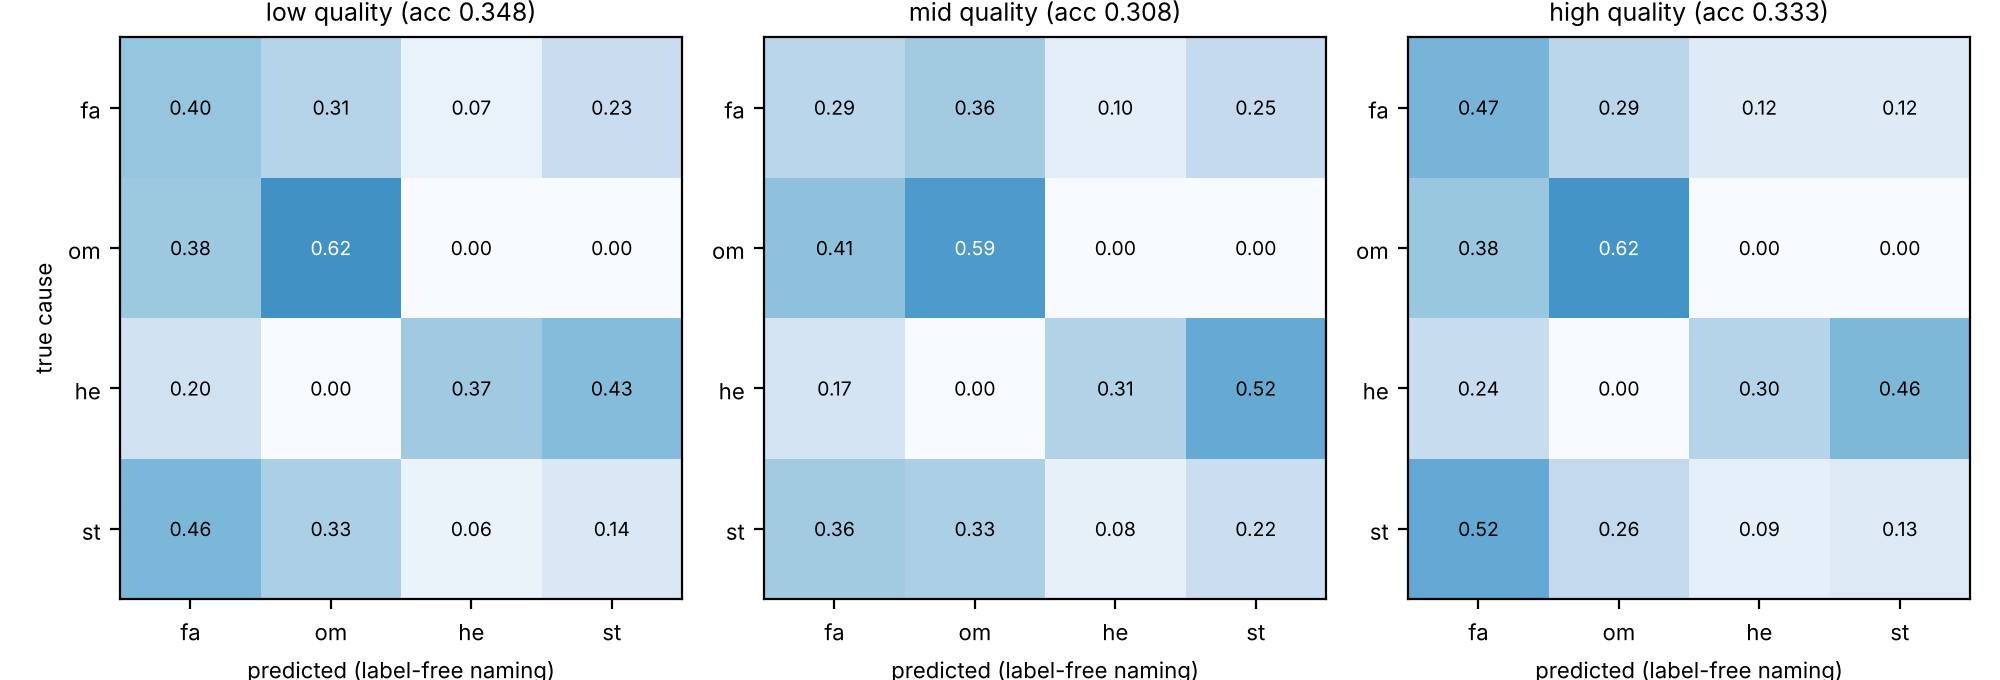

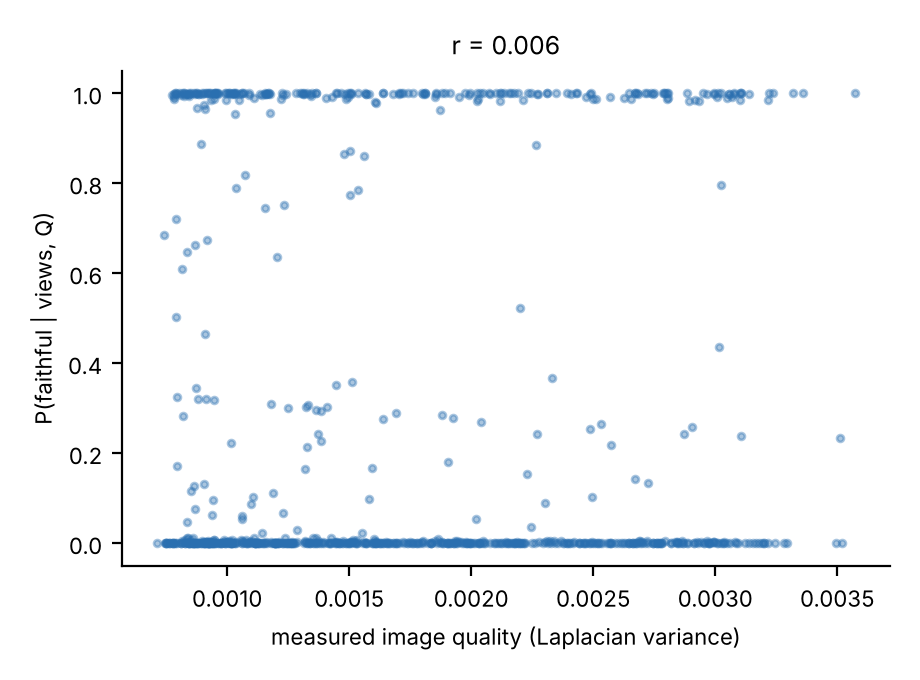

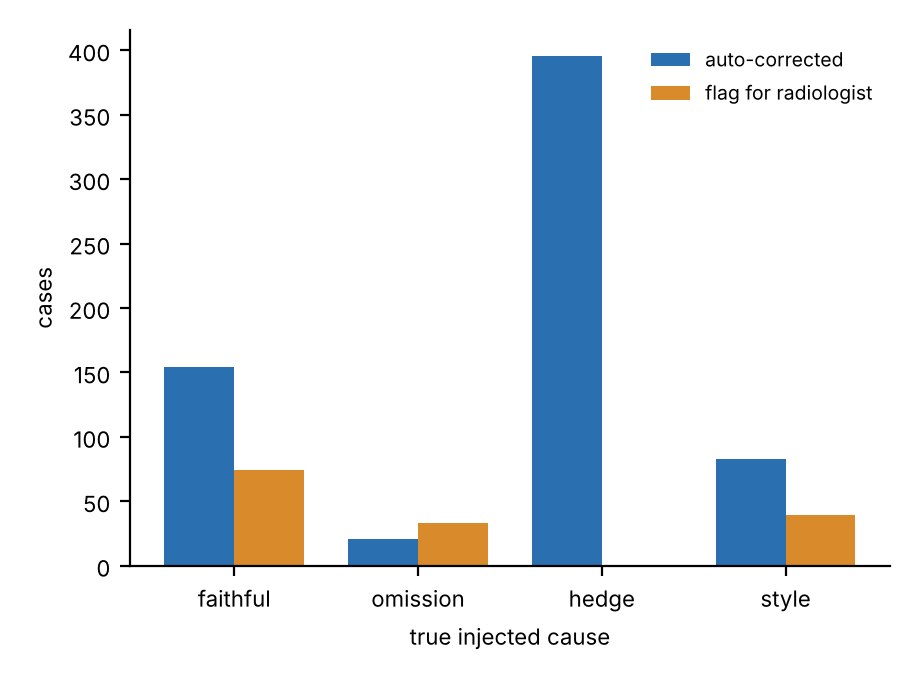

In [9]:
if RUN_PART_A:
    sr = json.load(open(os.path.join(RES, "single_run_seed0.json")))
    lf, orc = sr["label_free"], sr["oracle"]
    tabV = pd.DataFrame({"precision": lf["precision"], "recall": lf["recall"], "F1": lf["f1"],
                         "support": sr["support"]}, index=CLASS_NAMES).round(3)
    print("Table V (label-free naming, seed 0)"); display(tabV)
    print(f"label-free: accuracy {lf['accuracy']:.3f}  balanced accuracy {lf['balanced_accuracy']:.3f}  macro-F1 {lf['macro_f1']:.3f}")
    print(f"oracle    : accuracy {orc['accuracy']:.3f}  balanced accuracy {orc['balanced_accuracy']:.3f}  macro-F1 {orc['macro_f1']:.3f}")
    print(f"share of cases with max posterior > 0.99: {sr['share_conf_gt_099']:.3f}; accuracy among them: {sr['acc_among_conf_gt_099']:.3f}")
    print(f"triage: {sr['review_frac']:.3f} routed to review; omissions flagged {sr['omission_review_rate']:.3f}; others flagged {sr['other_review_rate']:.3f}")
    print("quality strata (label-free):", {k: round(v, 3) for k, v in sr["strat_label_free"].items()},
          "| corr(P(faithful), Q) =", round(sr["corr_pfaithful_q"], 3))
    show("quality_stratified_confusion.png", "posterior_vs_quality.png", "triage_routing.png")

## A7. Extended study: stages A–G, 145 runs (Table VI)

| Stage | Purpose | Runs (full mode) | Paper |
|---|---|---|---|
| A | 10-seed replication, oracle + label-free + held-out | 10 | Table XVI, Fig. 10 |
| B | View-subset ablation, 7 subsets × 5 seeds | 35 | Table XII, Fig. 6 |
| C | Reader count 5–80 × 5 seeds | 25 | Table XIII, Fig. 7 |
| D | Sample size 100–800 patients × 5 seeds | 20 | Table XIV, Fig. 8 |
| E | Quality-confound strength $\beta_Q$ × 5 seeds | 25 | Table XV, Fig. 9 |
| F | Nine correction rules, cross-fit and single-split image view | 20 | Table XI, Fig. 5 |
| G | Single-split (leaky) image view on the Stage A seeds | 10 | Table XVII, Fig. 11 |

Stage F compares rules that combine a text-implied finding probability (hand-set 0.15 / 0.55 / 0.85 for silent / hedged / plain reports) with the cross-fitted image score, plus a scalar single-noise-score analogue of NCR-style rectification and four controls (text pattern only, true cause, calibrated text lookup, logistic regression on text and image). Rules are fit on a 70% split and scored by Brier score and MAE on the remaining 30%.

In [10]:
OUT = RES


def flat_row(cfg, r):
    row = dict(cfg)
    row["accuracy"] = r["accuracy"]
    row["macro_f1"] = r["macro_f1"]
    row["loglik"] = r["loglik"]
    row["n_cases"] = r["n_cases"]
    row["n_features"] = r["n_features"]
    row["elapsed_sec"] = r["elapsed_sec"]
    for cn in CLASS_NAMES:
        row[f"prec_{cn}"] = r["per_class_precision"][cn]
        row[f"rec_{cn}"] = r["per_class_recall"][cn]
        row[f"f1_{cn}"] = r["per_class_f1"][cn]
        row[f"support_{cn}"] = r["per_class_support"][cn]
    for qb, acc in r["quality_stratified_accuracy"].items():
        row[f"acc_{qb}"] = acc
    row["balanced_accuracy"] = float(np.mean(list(r["per_class_recall"].values())))
    for tag, key in (("anchor", "anchor_insample"),):
        s = r[key]
        row[f"{tag}_accuracy"], row[f"{tag}_bal_acc"], row[f"{tag}_macro_f1"] = s["accuracy"], s["balanced_accuracy"], s["macro_f1"]
        for i, cn in enumerate(CLASS_NAMES):
            row[f"{tag}_rec_{cn}"], row[f"{tag}_f1_{cn}"] = s["recall"][i], s["f1"][i]
    if "heldout" in r:
        for tag in ("oracle", "anchor"):
            s = r["heldout"][tag]
            row[f"ho_{tag}_accuracy"], row[f"ho_{tag}_bal_acc"], row[f"ho_{tag}_macro_f1"] = s["accuracy"], s["balanced_accuracy"], s["macro_f1"]
            for i, cn in enumerate(CLASS_NAMES):
                row[f"ho_{tag}_rec_{cn}"], row[f"ho_{tag}_f1_{cn}"] = s["recall"][i], s["f1"][i]
        row["ho_n_test"] = r["heldout"]["n_test"]
    row["corr_pfaithful_q"] = r["corr_pfaithful_q"]
    row["corr_pfaithful_q_pval"] = r["corr_pfaithful_q_pval"]
    return row


def append_csv(path, row):
    df = pd.DataFrame([row])
    header = not os.path.exists(path)
    df.to_csv(path, mode="a", header=header, index=False)


# ---------------------------------------------------------------- Stage A ---
def stage_A(seeds=range(10)):
    path = os.path.join(OUT, "A_main_replication.csv")
    for s in seeds:
        t0 = time.time()
        r = run_single(seed=s, cross_fit=True, cnn_epochs=8, em_restarts=6)
        cfg = dict(stage="A", seed=s, views="v1+v2+v3", n_patients=400,
                   n_readers=20, beta_q=2.2, cross_fit=True)
        append_csv(path, flat_row(cfg, r))
        print(f"[A] seed={s} acc={r['accuracy']:.3f} macro_f1={r['macro_f1']:.3f} "
              f"({time.time()-t0:.1f}s)", flush=True)
    print("[A] done.")


# ---------------------------------------------------------------- Stage B ---
def stage_B(seeds=range(100, 105)):
    path = os.path.join(OUT, "B_view_ablation.csv")
    subsets = [
        frozenset({"v1"}), frozenset({"v2"}), frozenset({"v3"}),
        frozenset({"v1", "v2"}), frozenset({"v1", "v3"}), frozenset({"v2", "v3"}),
        frozenset({"v1", "v2", "v3"}),
    ]
    for views in subsets:
        label = "+".join(sorted(views))
        for s in seeds:
            t0 = time.time()
            r = run_single(seed=s, views=views, cross_fit=True, cnn_epochs=8, em_restarts=6)
            cfg = dict(stage="B", seed=s, views=label, n_views=len(views),
                       n_patients=400, n_readers=20, beta_q=2.2, cross_fit=True)
            append_csv(path, flat_row(cfg, r))
            print(f"[B] views={label} seed={s} acc={r['accuracy']:.3f} "
                  f"macro_f1={r['macro_f1']:.3f} ({time.time()-t0:.1f}s)", flush=True)
    print("[B] done.")


# ---------------------------------------------------------------- Stage C ---
def stage_C(reader_counts=(5, 10, 20, 40, 80), seeds=range(200, 205)):
    path = os.path.join(OUT, "C_reader_count_sweep.csv")
    for nr in reader_counts:
        for s in seeds:
            t0 = time.time()
            r = run_single(seed=s, n_readers=nr, cross_fit=True, cnn_epochs=8, em_restarts=6)
            cfg = dict(stage="C", seed=s, views="v1+v2+v3", n_patients=400,
                       n_readers=nr, beta_q=2.2, cross_fit=True)
            append_csv(path, flat_row(cfg, r))
            print(f"[C] n_readers={nr} seed={s} acc={r['accuracy']:.3f} "
                  f"style_f1={r['per_class_f1']['style']:.3f} ({time.time()-t0:.1f}s)", flush=True)
    print("[C] done.")


# ---------------------------------------------------------------- Stage D ---
def stage_D(patient_counts=(100, 200, 400, 800), seeds=range(300, 305)):
    path = os.path.join(OUT, "D_sample_size_sweep.csv")
    for npat in patient_counts:
        for s in seeds:
            t0 = time.time()
            r = run_single(seed=s, n_patients=npat, cross_fit=True, cnn_epochs=8, em_restarts=6)
            cfg = dict(stage="D", seed=s, views="v1+v2+v3", n_patients=npat,
                       n_readers=20, beta_q=2.2, cross_fit=True)
            append_csv(path, flat_row(cfg, r))
            print(f"[D] n_patients={npat} seed={s} acc={r['accuracy']:.3f} "
                  f"omission_rec={r['per_class_recall']['omission']:.3f} "
                  f"omission_support={r['per_class_support']['omission']:.0f} "
                  f"({time.time()-t0:.1f}s)", flush=True)
    print("[D] done.")


# ---------------------------------------------------------------- Stage E ---
def stage_E(betas=(0.0, 1.1, 2.2, 4.4, 8.8), seeds=range(400, 405)):
    path = os.path.join(OUT, "E_confound_strength_sweep.csv")
    for beta in betas:
        for s in seeds:
            t0 = time.time()
            r = run_single(seed=s, beta_q=beta, cross_fit=True, cnn_epochs=8, em_restarts=6)
            strat = r["quality_stratified_accuracy"]
            spread = max(strat.values()) - min(strat.values())
            cfg = dict(stage="E", seed=s, views="v1+v2+v3", n_patients=400,
                       n_readers=20, beta_q=beta, cross_fit=True)
            row = flat_row(cfg, r)
            row["strat_spread"] = spread
            append_csv(path, row)
            print(f"[E] beta_q={beta} seed={s} acc={r['accuracy']:.3f} "
                  f"strat_spread={spread:.3f} corr={r['corr_pfaithful_q']:.3f} "
                  f"({time.time()-t0:.1f}s)", flush=True)
    print("[E] done.")


# ---------------------------------------------------------------- Stage G ---
def stage_G(seeds=range(10)):
    """Same seeds as A but cross_fit=False, to quantify the single-split leakage
    the manuscript flags in Section VII-A / fixes in Section VIII-A."""
    path = os.path.join(OUT, "G_crossfit_vs_holdout.csv")
    for s in seeds:
        t0 = time.time()
        r = run_single(seed=s, cross_fit=False, cnn_epochs=8, em_restarts=6)
        cfg = dict(stage="G", seed=s, views="v1+v2+v3", n_patients=400,
                   n_readers=20, beta_q=2.2, cross_fit=False)
        append_csv(path, flat_row(cfg, r))
        print(f"[G] (holdout) seed={s} acc={r['accuracy']:.3f} macro_f1={r['macro_f1']:.3f} "
              f"({time.time()-t0:.1f}s)", flush=True)
    print("[G] done.")


# ---------------------------------------------------------- Stage F (setup)--
def stage_F(seeds=range(10)):
    """Correction-rule comparison. LABEL-FREE: the text-implied finding probability is computed
    from the OBSERVED report text (previously it was computed from the true cause), and the
    typed rules use the label-free (anchor-named) predicted class. Rules compared on a 70/30
    split inside each seed, both image-view protocols:
      naive            : 0.5 text + 0.5 image
      symmetric        : one learned text weight for all cases (single global trust weight)
      single-score     : NCR-style single noise score: text weight = w0 * P(clean | discrepancy),
                         P(clean) from a 2-component GMM on |text - image| fit on the train split,
                         w0 learned on train (one noise score, cause-agnostic)
      fixed typed      : hand-set per-class weights
      learned typed    : per predicted class, closed-form least squares on train
    The single-score and symmetric rules are scalar analogues of single-noise-score
    rectification, NOT the original image-text retrieval implementations of NCR / BiCro."""
    from sklearn.model_selection import train_test_split
    from sklearn.mixture import GaussianMixture
    path = os.path.join(OUT, "F_correction_weights.csv")
    FIXED = {0: 0.5, 1: 0.1, 2: 0.35, 3: 0.6}

    def ls_weight(text, img, y, default):
        x = text - img
        d = (x * x).sum()
        return float(np.clip((x * (y - img)).sum() / d, 0, 1)) if d > 1e-8 else default

    for cf in (True, False):
        for s in seeds:
            t0 = time.time()
            r = run_single(seed=s, cross_fit=cf, cnn_epochs=8, em_restarts=6, heldout=False)
            df = r["df"].copy()
            df["pred_lf"] = np.asarray(r["pred_anchor"])
            hd = df["text"].apply(hedge_density).values
            mn = df["text"].apply(mentions_finding).values
            df["text_prob"] = np.where(mn == 0, 0.15, np.where(hd > 0, 0.55, 0.85))
            df["img_prob"] = df["view2_raw"].values
            train, test = train_test_split(df, test_size=0.3, random_state=s)
            T_, I_, Y_ = test["text_prob"].values, test["img_prob"].values, test["true_finding"].values
            mae = lambda p: float(np.abs(p - Y_).mean())
            brier = {}

            def score(name, p):
                brier[name] = float(((np.asarray(p) - Y_) ** 2).mean())
                return mae(p)

            res = {"naive": score("naive", 0.5 * T_ + 0.5 * I_)}
            w_sym = ls_weight(train.text_prob.values, train.img_prob.values, train.true_finding.values, 0.5)
            res["symmetric"] = score("symmetric", w_sym * T_ + (1 - w_sym) * I_)

            dtr = np.abs(train.text_prob.values - train.img_prob.values)[:, None]
            gmm = GaussianMixture(2, random_state=s).fit(dtr)
            clean = int(np.argmin(gmm.means_.ravel()))
            pc_tr = gmm.predict_proba(dtr)[:, clean]
            # w0: LS fit of  y - img = w0 * pc * (text - img)
            xs = pc_tr * (train.text_prob.values - train.img_prob.values)
            ys = train.true_finding.values - train.img_prob.values
            w0 = float(np.clip((xs * ys).sum() / max((xs * xs).sum(), 1e-8), 0, 1))
            pc_te = gmm.predict_proba(np.abs(T_ - I_)[:, None])[:, clean]
            w_te = w0 * pc_te
            res["single_score"] = score("single_score", w_te * T_ + (1 - w_te) * I_)

            wf = test["pred_lf"].map(FIXED).values
            res["fixed_typed"] = score("fixed_typed", wf * T_ + (1 - wf) * I_)
            lw = {}
            for cls in range(4):
                sub = train[train["pred_lf"] == cls]
                lw[cls] = ls_weight(sub.text_prob.values, sub.img_prob.values, sub.true_finding.values, FIXED[cls]) if len(sub) >= 5 else FIXED[cls]
            wl = test["pred_lf"].map(lw).values
            res["learned_typed"] = score("learned_typed", wl * T_ + (1 - wl) * I_)
            # control 1: weights stratified by the OBSERVED text pattern only (3 levels of text_prob),
            # i.e. what a lexical rule gets without any latent class
            pw = {}
            for lv in (0.15, 0.55, 0.85):
                sub = train[np.isclose(train.text_prob, lv)]
                pw[lv] = ls_weight(sub.text_prob.values, sub.img_prob.values, sub.true_finding.values, 0.5) if len(sub) >= 5 else 0.5
            wp = np.array([pw[min(pw, key=lambda k: abs(k - v))] for v in T_])
            res["pattern_typed"] = score("pattern_typed", wp * T_ + (1 - wp) * I_)
            # control 2 (upper bound, uses TRUE cause): learned weight per true class
            tw = {}
            for cls in range(4):
                sub = train[train["z"] == cls]
                tw[cls] = ls_weight(sub.text_prob.values, sub.img_prob.values, sub.true_finding.values, 0.5) if len(sub) >= 5 else 0.5
            wt = test["z"].map(tw).values
            res["true_cause_typed"] = score("true_cause_typed", wt * T_ + (1 - wt) * I_)
            # calibrated baselines (added after review): no latent class, no hand-set probabilities
            from sklearn.linear_model import LogisticRegression
            pat_tr, pat_te = train["text_prob"].values, T_
            cal = {lv: float(train.true_finding.values[np.isclose(pat_tr, lv)].mean())
                   for lv in (0.15, 0.55, 0.85) if np.isclose(pat_tr, lv).sum() > 0}
            res["calibrated_text"] = score("calibrated_text", np.array([cal.get(min(cal, key=lambda k: abs(k - v)), 0.5) for v in pat_te]))
            onehot = lambda v: np.column_stack([np.isclose(v, 0.15), np.isclose(v, 0.55), np.isclose(v, 0.85)]).astype(float)
            Xtr_ = np.column_stack([onehot(pat_tr), train.img_prob.values]); Xte_ = np.column_stack([onehot(pat_te), I_])
            lr = LogisticRegression(max_iter=1000).fit(Xtr_, train.true_finding.values)
            res["logistic_text_image"] = score("logistic_text_image", lr.predict_proba(Xte_)[:, 1])
            row = dict(stage="F", seed=s, cross_fit=cf, n_test=len(test),
                       learned_weights=json.dumps(lw), w_symmetric=w_sym, w0_single_score=w0, **res,
                       **{"brier_" + k: v for k, v in brier.items()})
            append_csv(path, row)
            print(f"[F] cf={cf} seed={s} " + " ".join(f"{k}={v:.3f}" for k, v in res.items())
                  + f" ({time.time()-t0:.1f}s)", flush=True)
    print("[F] done.")

In [11]:
STAGE_FILES = dict(A="A_main_replication.csv", B="B_view_ablation.csv", C="C_reader_count_sweep.csv",
                   D="D_sample_size_sweep.csv", E="E_confound_strength_sweep.csv",
                   F="F_correction_weights.csv", G="G_crossfit_vs_holdout.csv")
STAGE_FUNS = dict(A=stage_A, B=stage_B, C=stage_C, D=stage_D, E=stage_E, F=stage_F, G=stage_G)
if RUN_PART_A:
    t_all = time.time()
    for st in "ABCDEFG":
        if os.path.exists(os.path.join(RES, STAGE_FILES[st])):
            print(f"stage {st}: {STAGE_FILES[st]} exists, skipped (delete it to re-run)"); continue
        t0 = time.time()
        STAGE_FUNS[st](seeds=SEEDS[st])
        print(f"stage {st} finished in {time.time()-t0:.0f}s")
    print(f"extended study: {time.time()-t_all:.0f}s")

[A] seed=0 acc=0.393 macro_f1=0.316 (5.6s)


[A] seed=1 acc=0.391 macro_f1=0.339 (5.6s)


[A] seed=2 acc=0.403 macro_f1=0.330 (6.2s)


[A] seed=3 acc=0.367 macro_f1=0.309 (6.1s)


[A] seed=4 acc=0.409 macro_f1=0.335 (5.4s)


[A] seed=5 acc=0.409 macro_f1=0.297 (5.4s)


... (142 outputs left out)

[G] (holdout) seed=7 acc=0.484 macro_f1=0.422 (2.1s)


[G] (holdout) seed=8 acc=0.466 macro_f1=0.402 (2.2s)


[G] (holdout) seed=9 acc=0.443 macro_f1=0.359 (2.2s)


[G] done.
stage G finished in 21s
extended study: 691s


## A8. Summary tables and figures (Tables XI–XVII, Figs. 5–11)

In [12]:
# Okabe-Ito colorblind-safe categorical palette, fixed assignment order
OI = dict(blue="#0072B2", orange="#E69F00", green="#009E73", vermillion="#D55E00",
          purple="#CC79A7", skyblue="#56B4E9", yellow="#F0E442", black="#000000",
          gray="#999999")


plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e0e0e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "figure.dpi": 300,
})


def savefig(fig, name):
    path = os.path.join(FIG, name)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print("wrote", path)


def mean_std(s):
    return s.mean(), s.std(ddof=1)


# ============================================================ Stage A =====
def analyze_A():
    df = pd.read_csv(os.path.join(RES, "A_main_replication.csv"))
    rows = []
    for col, label in [("accuracy", "Overall accuracy"), ("macro_f1", "Macro-F1"),
                        ("f1_faithful", "F1 (faithful)"), ("f1_omission", "F1 (omission)"),
                        ("f1_hedge", "F1 (hedge)"), ("f1_style", "F1 (style)"),
                        ("acc_low_quality", "Accuracy (low quality)"),
                        ("acc_mid_quality", "Accuracy (mid quality)"),
                        ("acc_high_quality", "Accuracy (high quality)"),
                        ("corr_pfaithful_q", "corr(P(faithful), Q)"),
                        ("balanced_accuracy", "Balanced accuracy (oracle-aligned, in-sample)"),
                        ("anchor_accuracy", "Accuracy (label-free naming, in-sample)"),
                        ("anchor_bal_acc", "Balanced accuracy (label-free naming, in-sample)"),
                        ("anchor_macro_f1", "Macro-F1 (label-free naming, in-sample)"),
                        ("ho_oracle_accuracy", "Held-out accuracy (oracle naming from train)"),
                        ("ho_oracle_bal_acc", "Held-out balanced accuracy (oracle naming from train)"),
                        ("ho_oracle_macro_f1", "Held-out macro-F1 (oracle naming from train)"),
                        ("ho_anchor_accuracy", "Held-out accuracy (label-free naming)"),
                        ("ho_anchor_bal_acc", "Held-out balanced accuracy (label-free naming)"),
                        ("ho_anchor_macro_f1", "Held-out macro-F1 (label-free naming)"),
                        ("anchor_f1_faithful", "F1 faithful (label-free naming)"),
                        ("anchor_f1_omission", "F1 omission (label-free naming)"),
                        ("anchor_f1_hedge", "F1 hedge (label-free naming)"),
                        ("anchor_f1_style", "F1 style (label-free naming)")]:
        m, sd = mean_std(df[col])
        rows.append(dict(metric=label, mean=m, std=sd, min=df[col].min(), max=df[col].max()))
    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(RES, "Table_A_summary.csv"), index=False)
    print(out.to_string(index=False))

    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    seeds = df["seed"]
    ax.bar(seeds, df["accuracy"], color=OI["blue"], width=0.6, label="Accuracy")
    sup = df[[f"support_{c}" for c in ("faithful", "omission", "hedge", "style")]].values
    ax.plot(seeds, sup.max(1) / sup.sum(1), "D", color=OI["black"], markersize=4,
            label="Majority-class accuracy (per seed)")
    ax.plot(seeds, df["anchor_bal_acc"], "^", color=OI["orange"], markersize=5,
            label="Balanced acc., label-free")
    ax.axhline(0.25, color=OI["vermillion"], linestyle="--", linewidth=1.2, label="Chance (0.25)")
    ax.set_xlabel("Random seed")
    ax.set_ylabel("Oracle-aligned accuracy (bars)")
    ax.set_title("Cause recovery across 10 independent seeds")
    ax.set_xticks(seeds)
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    savefig(fig, "A_main_replication.png")
    return out


# ============================================================ Stage B =====
def analyze_B():
    df = pd.read_csv(os.path.join(RES, "B_view_ablation.csv"))
    g = df.groupby(["views", "n_views"]).agg(
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
        f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
        f1_style_mean=("f1_style", "mean"), f1_omission_mean=("f1_omission", "mean"),
        bal_mean=("balanced_accuracy", "mean"), bal_std=("balanced_accuracy", "std"),
        anchor_bal_mean=("anchor_bal_acc", "mean"), anchor_bal_std=("anchor_bal_acc", "std"),
    ).reset_index().sort_values(["n_views", "views"])
    g.to_csv(os.path.join(RES, "Table_B_summary.csv"), index=False)
    print(g.to_string(index=False))

    order = g.sort_values(["n_views", "views"])["views"].tolist()
    x = np.arange(len(order))
    accs = g.set_index("views").loc[order, "acc_mean"]
    accs_sd = g.set_index("views").loc[order, "acc_std"]
    f1s = g.set_index("views").loc[order, "f1_mean"]
    f1s_sd = g.set_index("views").loc[order, "f1_std"]

    fig, ax = plt.subplots(figsize=(5.2, 2.8))
    w = 0.35
    ax.bar(x - w/2, accs, width=w, yerr=accs_sd, capsize=2, color=OI["blue"], label="Accuracy")
    ax.bar(x + w/2, f1s, width=w, yerr=f1s_sd, capsize=2, color=OI["orange"], label="Macro-F1")
    ax.axhline(0.25, color=OI["vermillion"], linestyle="--", linewidth=1.0, label="Chance")
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_ylabel("Score")
    ax.set_title("Recovery by view subset (mean $\\pm$ s.d., 5 seeds)")
    ax.legend(frameon=False, fontsize=7)
    savefig(fig, "B_view_ablation.png")
    return g


# ============================================================ Stage C =====
def analyze_C():
    df = pd.read_csv(os.path.join(RES, "C_reader_count_sweep.csv"))
    g = df.groupby("n_readers").agg(
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
        style_f1_mean=("f1_style", "mean"), style_f1_std=("f1_style", "std"),
        faithful_f1_mean=("f1_faithful", "mean"), faithful_f1_std=("f1_faithful", "std"),
        cases_per_reader=("n_cases", lambda s: (s / df.loc[s.index, "n_readers"]).mean()),
    ).reset_index()
    g.to_csv(os.path.join(RES, "Table_C_summary.csv"), index=False)
    print(g.to_string(index=False))

    fig, ax = plt.subplots(figsize=(3.6, 2.7))
    ax.errorbar(g["n_readers"], g["style_f1_mean"], yerr=g["style_f1_std"],
                marker="o", color=OI["purple"], label="style F1", capsize=2)
    ax.errorbar(g["n_readers"], g["faithful_f1_mean"], yerr=g["faithful_f1_std"],
                marker="s", color=OI["blue"], label="faithful F1", capsize=2)
    ax.errorbar(g["n_readers"], g["acc_mean"], yerr=g["acc_std"],
                marker="^", color=OI["black"], label="overall accuracy", capsize=2)
    ax.set_xscale("log", base=2)
    ax.set_xticks(g["n_readers"])
    ax.set_xticklabels(g["n_readers"])
    ax.set_xlabel("Number of readers (800 cases fixed)")
    ax.set_ylabel("Score")
    ax.set_title("Style/faithful recovery vs. reader count")
    ax.legend(frameon=False, fontsize=7)
    fig.text(0.5, -0.06, "Cases per reader: 160 / 80 / 40 / 20 / 10 (dashed threshold at 15 falls between the last two points)",
              ha="center", fontsize=6.5, color="#555555")
    savefig(fig, "C_reader_count_sweep.png")
    return g


# ============================================================ Stage D =====
def analyze_D():
    df = pd.read_csv(os.path.join(RES, "D_sample_size_sweep.csv"))
    g = df.groupby("n_patients").agg(
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
        omission_rec_mean=("rec_omission", "mean"), omission_rec_std=("rec_omission", "std"),
        omission_support_mean=("support_omission", "mean"),
    ).reset_index()
    g.to_csv(os.path.join(RES, "Table_D_summary.csv"), index=False)
    print(g.to_string(index=False))

    fig, ax = plt.subplots(figsize=(3.6, 2.7))
    ax.errorbar(g["n_patients"], g["omission_rec_mean"], yerr=g["omission_rec_std"],
                marker="o", color=OI["vermillion"], label="omission recall", capsize=2)
    ax.errorbar(g["n_patients"], g["acc_mean"], yerr=g["acc_std"],
                marker="^", color=OI["black"], label="overall accuracy", capsize=2)
    ax.set_xscale("log", base=2)
    ax.set_xticks(g["n_patients"])
    ax.set_xticklabels(g["n_patients"])
    ax.set_xlabel("Number of patients (2 visits each)")
    ax.set_ylabel("Score")
    ax.set_title("Omission recovery vs. sample size")
    ax.legend(frameon=False, fontsize=7, loc="lower right")
    savefig(fig, "D_sample_size_sweep.png")
    return g


# ============================================================ Stage E =====
def analyze_E():
    df = pd.read_csv(os.path.join(RES, "E_confound_strength_sweep.csv"))
    g = df.groupby("beta_q").agg(
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
        spread_mean=("strat_spread", "mean"), spread_std=("strat_spread", "std"),
        corr_mean=("corr_pfaithful_q", "mean"), corr_std=("corr_pfaithful_q", "std"),
    ).reset_index()
    g.to_csv(os.path.join(RES, "Table_E_summary.csv"), index=False)
    print(g.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(6.0, 2.6))
    axes[0].errorbar(g["beta_q"], g["spread_mean"], yerr=g["spread_std"],
                      marker="o", color=OI["blue"], capsize=2)
    axes[0].set_xlabel("Quality$\\to$hedge confound strength ($\\beta_Q$)")
    axes[0].set_ylabel("Quality-stratified\naccuracy spread")
    axes[0].set_title("(a) Confound leakage check")

    axes[1].errorbar(g["beta_q"], g["corr_mean"], yerr=g["corr_std"],
                      marker="s", color=OI["orange"], capsize=2)
    axes[1].axhline(0, color=OI["gray"], linewidth=0.8)
    axes[1].set_xlabel("Quality$\\to$hedge confound strength ($\\beta_Q$)")
    axes[1].set_ylabel("corr(P(faithful), Q)")
    axes[1].set_title("(b) Intended concomitant effect")
    savefig(fig, "E_confound_strength_sweep.png")
    return g


# ============================================================ Stage F =====
F_METHODS = [("Naive average", "naive"), ("Symmetric learned weight", "symmetric"),
             ("Single noise score (NCR-style)", "single_score"), ("Fixed typed weights", "fixed_typed"),
             ("Text-pattern weights (no latent class)", "pattern_typed"),
             ("Learned typed weights", "learned_typed"),
             ("Learned weights, TRUE cause", "true_cause_typed"),
             ("Calibrated text lookup (no image)", "calibrated_text"),
             ("Logistic: text pattern + image", "logistic_text_image")]


def analyze_F():
    from scipy import stats
    d = pd.read_csv(os.path.join(RES, "F_correction_weights.csv"))
    rows = []
    for cf, label in [(True, "Cross-fit view"), (False, "Single-split view")]:
        sub = d[d.cross_fit == cf]
        for name, col in F_METHODS:
            m, sd = mean_std(sub[col])
            win = (sub[col] < sub["naive"]).sum() if col != "naive" else np.nan
            lt = sub["learned_typed"].values
            if col in ("learned_typed",):
                p_t = p_w = np.nan
            else:
                p_t = stats.ttest_rel(lt, sub[col].values).pvalue
                try:
                    p_w = stats.wilcoxon(lt, sub[col].values).pvalue
                except ValueError:
                    p_w = np.nan
            bcol = "brier_" + col
            bm_, bsd = mean_std(sub[bcol]) if bcol in sub else (np.nan, np.nan)
            pb = (stats.ttest_rel(sub["brier_learned_typed"].values, sub[bcol].values).pvalue
                  if (bcol in sub and col != "learned_typed") else np.nan)
            rows.append(dict(image_view=label, method=name, mae_mean=m, mae_std=sd, brier_mean=bm_, brier_std=bsd,
                             wins_vs_naive=win, n_seeds=len(sub), p_t_learned_vs_this=p_t,
                             p_wilcoxon_learned_vs_this=p_w, p_t_brier_learned_vs_this=pb))
    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(RES, "Table_F_summary.csv"), index=False)
    print(out.to_string(index=False))

    fig, ax = plt.subplots(figsize=(5.0, 2.8))
    colors = [OI["gray"], OI["skyblue"], OI["green"], OI["orange"], OI["purple"], OI["blue"], OI["black"],
              "#8c564b", "#d62728"]
    x = np.arange(2)
    w = 0.09
    for i, (name, col) in enumerate(F_METHODS):
        vals = [out[(out.image_view == lbl) & (out.method == name)]["brier_mean"].iloc[0] for lbl in ["Single-split view", "Cross-fit view"]]
        errs = [out[(out.image_view == lbl) & (out.method == name)]["brier_std"].iloc[0] for lbl in ["Single-split view", "Cross-fit view"]]
        ax.bar(x + (i - 4) * w, vals, width=w, yerr=errs, capsize=2, color=colors[i], label=name)
    ax.set_xticks(x)
    ax.set_xticklabels(["Single-split view", "Cross-fit view"])
    ax.set_ylabel("Brier score (lower is better)")
    ax.set_title("Correction rules, Brier score (mean $\\pm$ s.d., 10 seeds)")
    ax.legend(frameon=False, fontsize=6, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    savefig(fig, "F_correction_weights.png")
    return out


# ============================================================ Stage G =====
def analyze_G():
    a = pd.read_csv(os.path.join(RES, "A_main_replication.csv"))[["seed", "accuracy", "macro_f1"]]
    g = pd.read_csv(os.path.join(RES, "G_crossfit_vs_holdout.csv"))[["seed", "accuracy", "macro_f1"]]
    merged = a.merge(g, on="seed", suffixes=("_crossfit", "_holdout"))
    summary = pd.DataFrame([
        dict(condition="Cross-fit (K=5)", acc_mean=merged.accuracy_crossfit.mean(),
             acc_std=merged.accuracy_crossfit.std(), f1_mean=merged.macro_f1_crossfit.mean(),
             f1_std=merged.macro_f1_crossfit.std()),
        dict(condition="Single-split (leaky)", acc_mean=merged.accuracy_holdout.mean(),
             acc_std=merged.accuracy_holdout.std(), f1_mean=merged.macro_f1_holdout.mean(),
             f1_std=merged.macro_f1_holdout.std()),
    ])
    summary.to_csv(os.path.join(RES, "Table_G_summary.csv"), index=False)
    merged.to_csv(os.path.join(RES, "Table_G_paired.csv"), index=False)
    print(summary.to_string(index=False))

    fig, ax = plt.subplots(figsize=(3.4, 2.7))
    for _, row in merged.iterrows():
        ax.plot([0, 1], [row.accuracy_crossfit, row.accuracy_holdout], color=OI["gray"],
                linewidth=0.8, alpha=0.7, zorder=1)
    ax.scatter(np.zeros(len(merged)), merged.accuracy_crossfit, color=OI["blue"], zorder=2, label="Cross-fit")
    ax.scatter(np.ones(len(merged)), merged.accuracy_holdout, color=OI["vermillion"], zorder=2, label="Single-split")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Cross-fit\n(K=5)", "Single-split\n(leaky)"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylabel("Recovery accuracy")
    ax.set_title("Same 10 seeds, image-view protocol only")
    savefig(fig, "G_crossfit_vs_holdout.png")
    return summary, merged


===== analyze_A =====
                                               metric      mean      std       min      max
                                     Overall accuracy  0.394500 0.031243  0.347500 0.438750
                                             Macro-F1  0.320079 0.019417  0.286775 0.350220
                                        F1 (faithful)  0.387754 0.076631  0.219008 0.510870
                                        F1 (omission)  0.124291 0.126134  0.000000 0.345324
                                           F1 (hedge)  0.540978 0.049593  0.459064 0.610442
                                           F1 (style)  0.227291 0.106515  0.035398 0.418182
                               Accuracy (low quality)  0.380524 0.038447  0.337079 0.471910
                               Accuracy (mid quality)  0.395489 0.040676  0.330827 0.458647
                              Accuracy (high quality)  0.407491 0.060592  0.337079 0.498127
                                 corr(P(faithful), Q) -0.

wrote paper_outputs/figs/B_view_ablation.png

===== analyze_C =====
 n_readers  acc_mean  acc_std  style_f1_mean  style_f1_std  faithful_f1_mean  faithful_f1_std  cases_per_reader
         5   0.42600 0.060772       0.165126      0.081226          0.365523         0.067696             160.0
        10   0.40575 0.073684       0.270841      0.127840          0.412340         0.045376              80.0
        20   0.39825 0.015900       0.232752      0.168214          0.386046         0.141868              40.0
        40   0.44975 0.052324       0.182170      0.131197          0.513631         0.082820              20.0
        80   0.53325 0.103903       0.164385      0.132592          0.457147         0.131900              10.0
wrote paper_outputs/figs/C_reader_count_sweep.png

===== analyze_D =====
 n_patients  acc_mean  acc_std  omission_rec_mean  omission_rec_std  omission_support_mean
        100  0.571000 0.126461           0.215000          0.185068                   13.2
     

wrote paper_outputs/figs/E_confound_strength_sweep.png

===== analyze_F =====
       image_view                                 method  mae_mean  mae_std  brier_mean  brier_std  wins_vs_naive  n_seeds  p_t_learned_vs_this  p_wilcoxon_learned_vs_this  p_t_brier_learned_vs_this
   Cross-fit view                          Naive average  0.373286 0.048432    0.155029   0.033433            NaN       10             0.031580                    0.027344                   0.021142
   Cross-fit view               Symmetric learned weight  0.361163 0.069821    0.146695   0.044916            5.0       10             0.015570                    0.007812                   0.017774
   Cross-fit view         Single noise score (NCR-style)  0.372874 0.091426    0.156345   0.058647            4.0       10             0.121038                    0.203125                   0.096962
   Cross-fit view                    Fixed typed weights  0.378200 0.056343    0.158084   0.039509            4.0       10    

wrote paper_outputs/figs/G_crossfit_vs_holdout.png


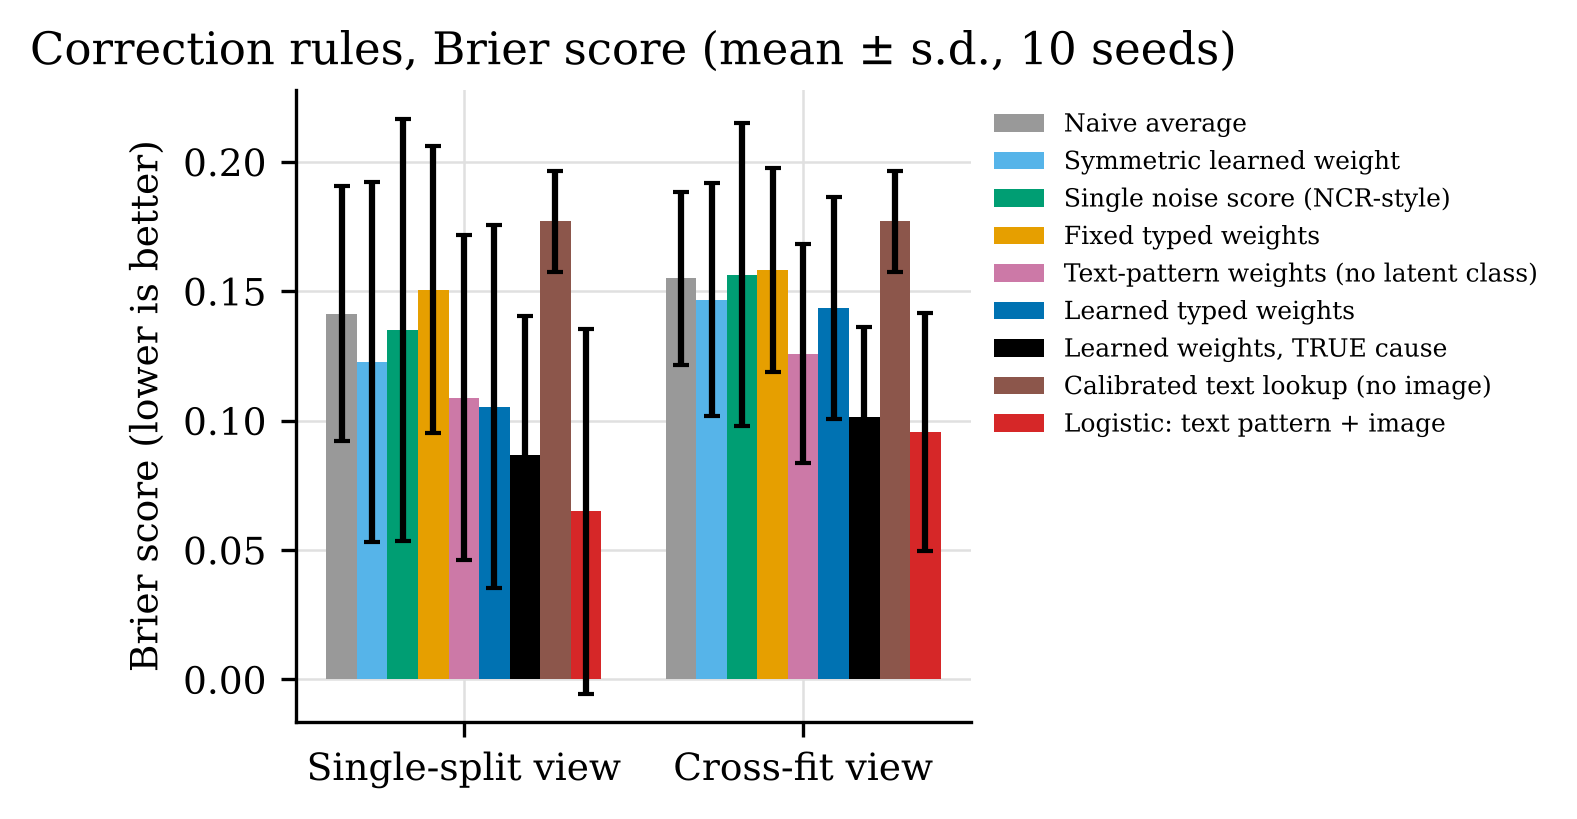

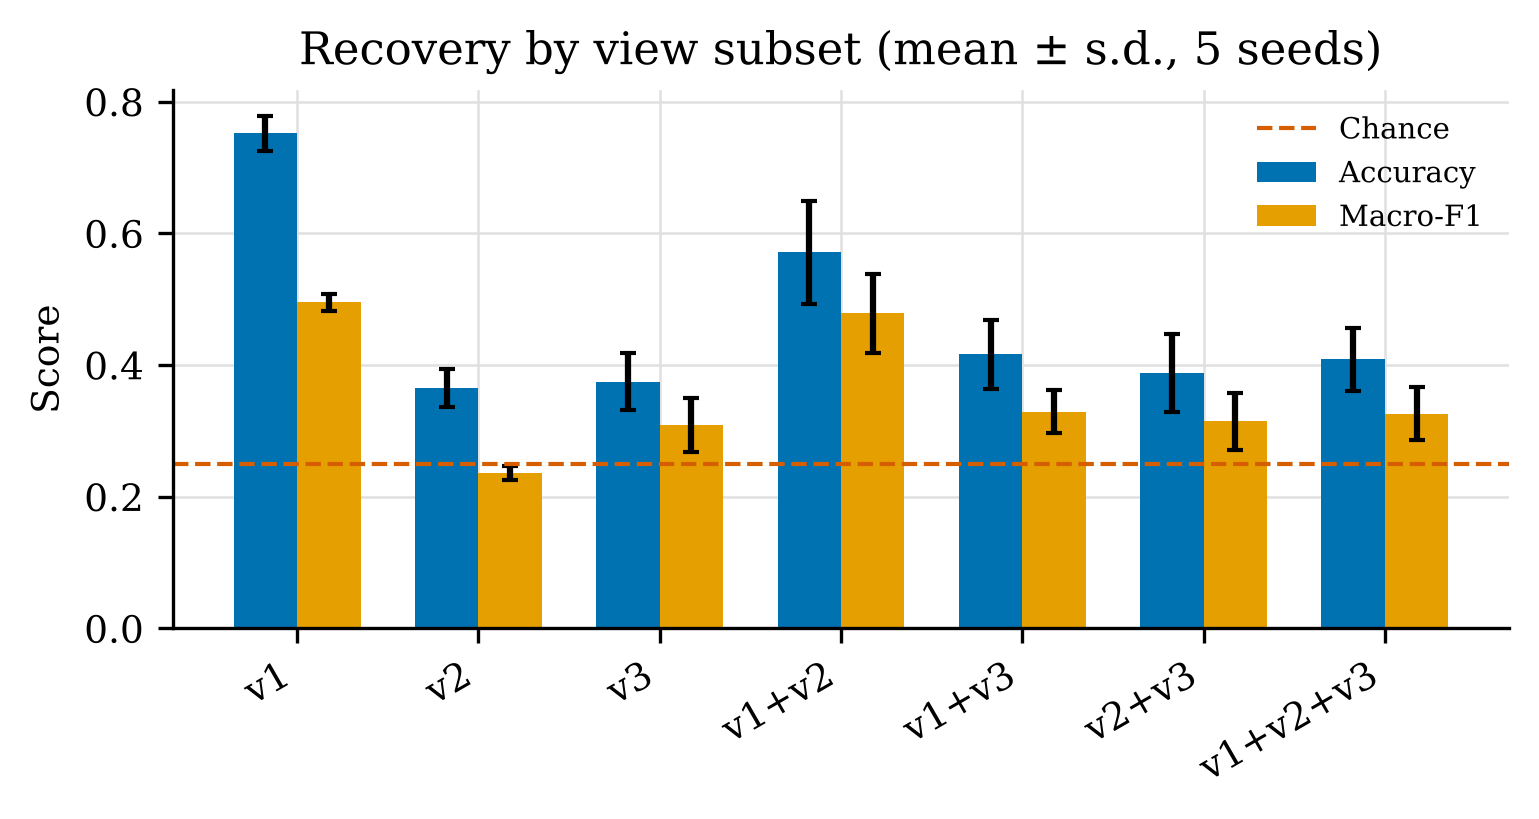

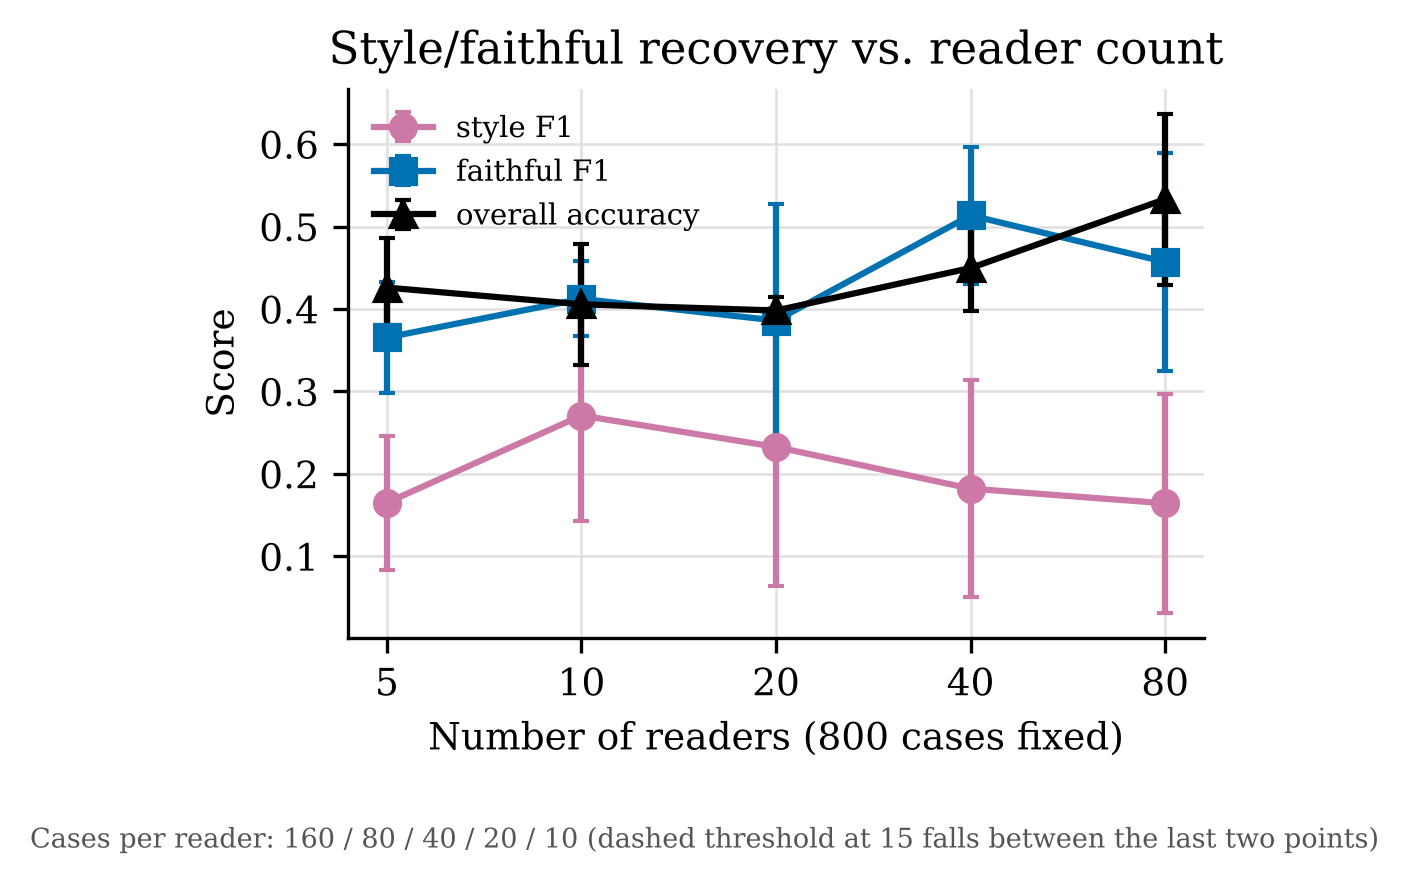

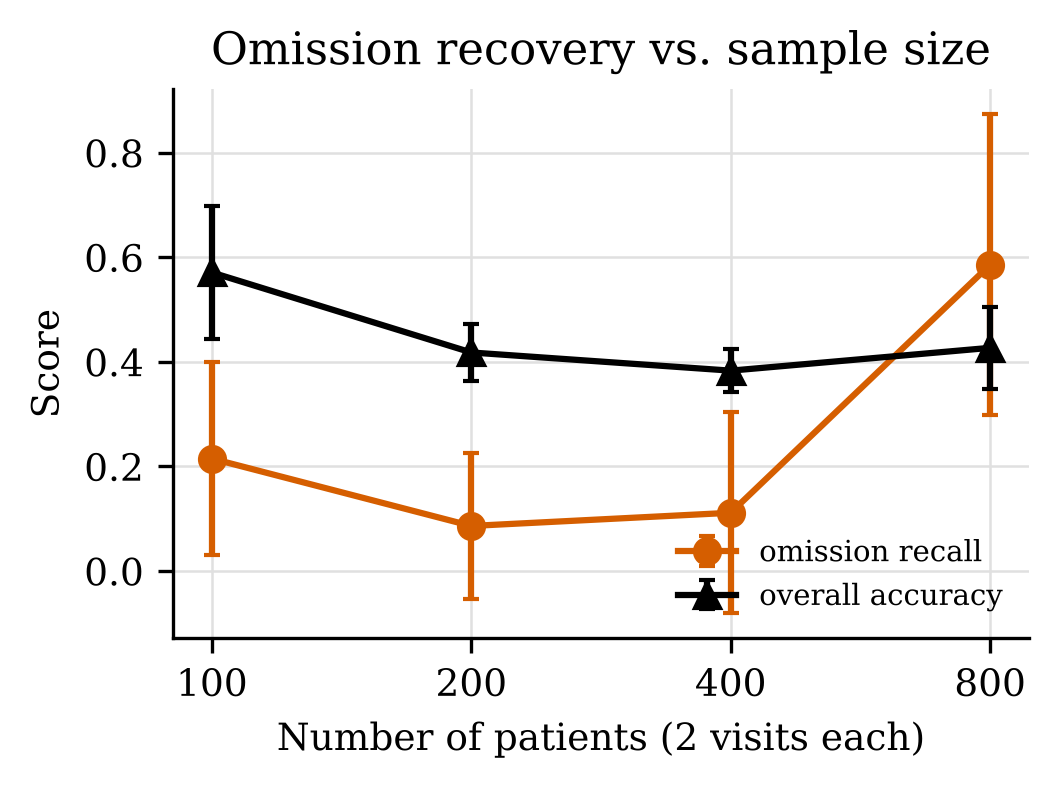

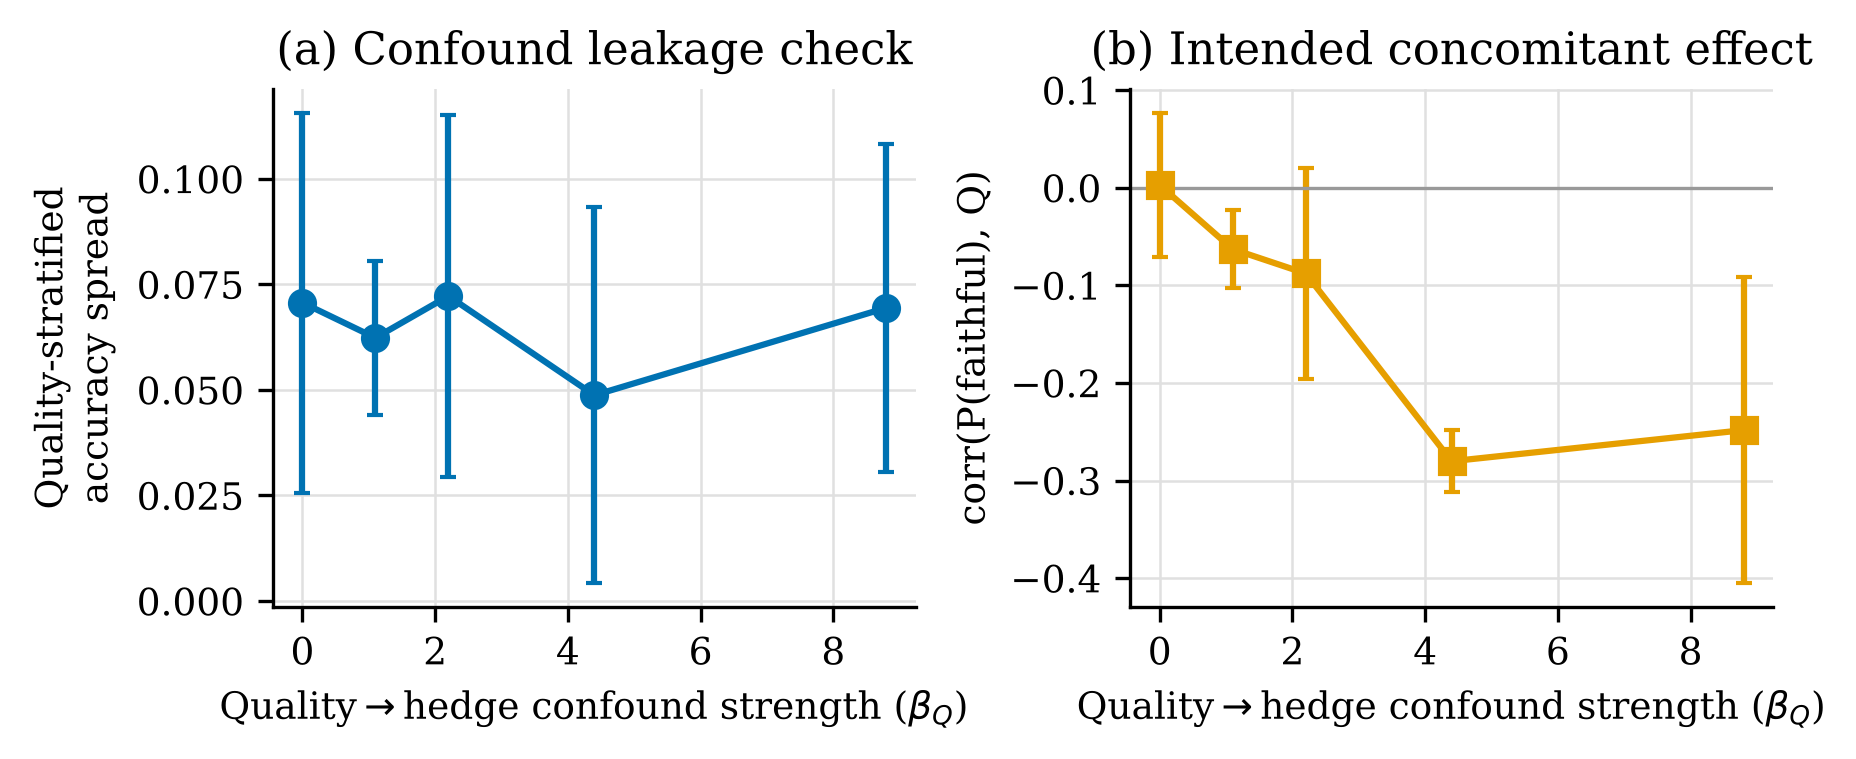

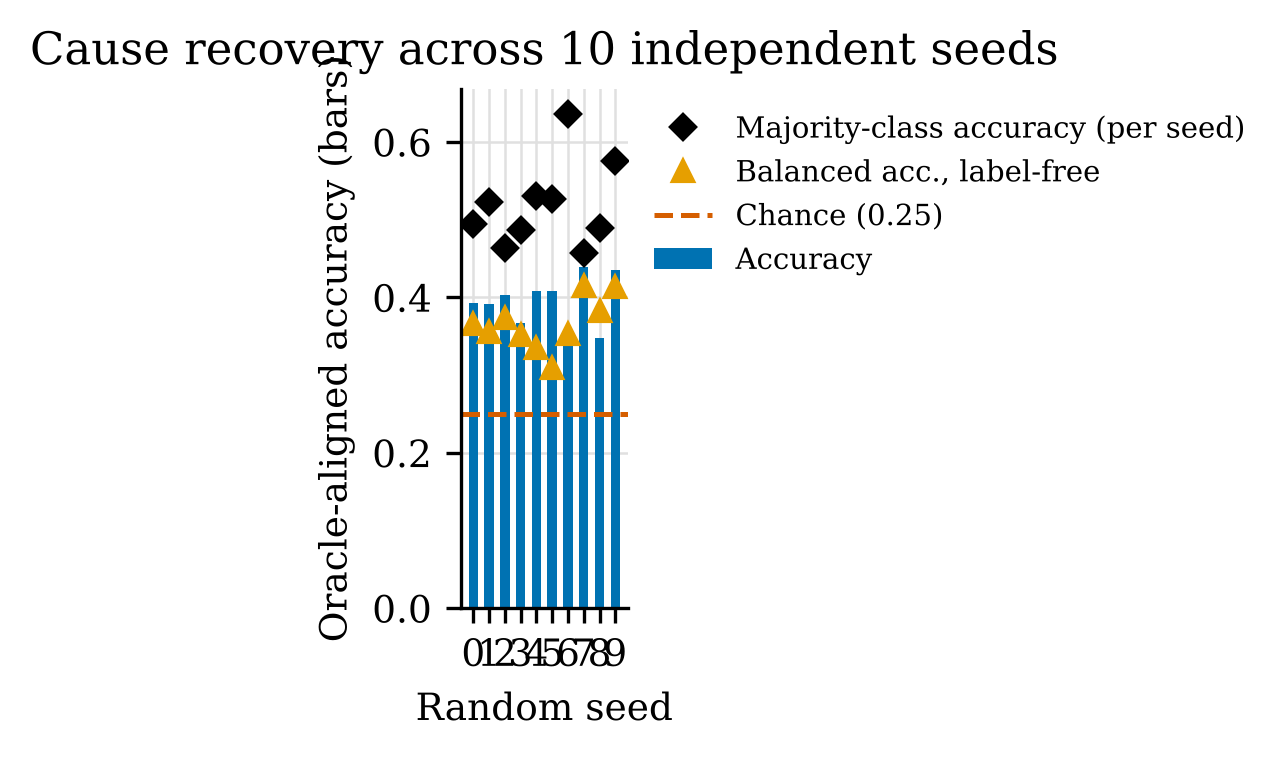

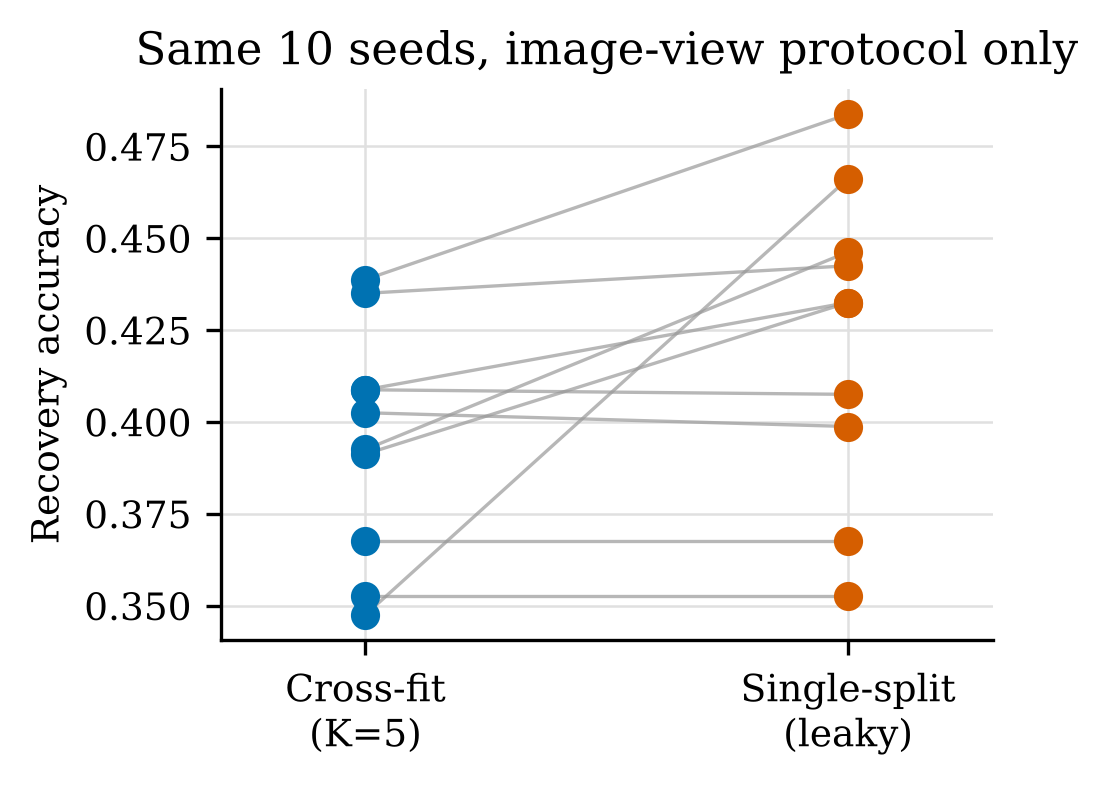

In [13]:
if RUN_PART_A:
    for fn in (analyze_A, analyze_B, analyze_C, analyze_D, analyze_E, analyze_F, analyze_G):
        print("\n=====", fn.__name__, "=====")
        fn()
    show("F_correction_weights.png", "B_view_ablation.png", "C_reader_count_sweep.png", "D_sample_size_sweep.png",
         "E_confound_strength_sweep.png", "A_main_replication.png", "G_crossfit_vs_holdout.png")

## A9. Significance tests and effect sizes (Sec. III-H1, III-H2)

The random seed is the unit of analysis. Accuracy is compared with each seed's own majority-class baseline (paired); balanced accuracy and macro-F1 with their constant chance levels (0.25 and $2p/(1+p)/4$). The single-split vs cross-fit comparison is paired over the Stage A/G seeds.

In [14]:
if RUN_PART_A:
    A = pd.read_csv(os.path.join(RES, "A_main_replication.csv"))
    G = pd.read_csv(os.path.join(RES, "G_crossfit_vs_holdout.csv"))

    sup = A[[f"support_{c}" for c in ("faithful", "omission", "hedge", "style")]].values
    p_major = sup.max(1) / sup.sum(1)
    maj = {"accuracy": p_major, "balanced_accuracy": np.full(len(A), 0.25),
           "macro_f1": 2 * p_major / (1 + p_major) / 4}
    rows = []


    def one_sample(name, x, base):
        base = np.asarray(base, float)
        d = x - base
        t, p = stats.ttest_rel(x, base) if base.ndim else stats.ttest_1samp(x, base)
        ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
        rows.append(dict(comparison="model_vs_majority_baseline", metric=name, n=len(x), mean=x.mean(), sd=x.std(ddof=1),
                         baseline=base.mean(), diff=d.mean(), ci_lo=ci[0], ci_hi=ci[1], t=t, p=p,
                         cohens_d=d.mean() / d.std(ddof=1)))


    one_sample("accuracy (oracle-aligned, in-sample)", A.accuracy.values, maj["accuracy"])
    one_sample("balanced accuracy (oracle-aligned, in-sample)", A.balanced_accuracy.values, maj["balanced_accuracy"])
    one_sample("macro-F1 (oracle-aligned, in-sample)", A.macro_f1.values, maj["macro_f1"])
    one_sample("balanced accuracy (label-free naming, in-sample)", A.anchor_bal_acc.values, maj["balanced_accuracy"])
    one_sample("macro-F1 (label-free naming, in-sample)", A.anchor_macro_f1.values, maj["macro_f1"])
    one_sample("balanced accuracy (label-free naming, held-out)", A.ho_anchor_bal_acc.values, maj["balanced_accuracy"])
    one_sample("macro-F1 (label-free naming, held-out)", A.ho_anchor_macro_f1.values, maj["macro_f1"])
    one_sample("balanced accuracy (oracle naming from train, held-out)", A.ho_oracle_bal_acc.values, maj["balanced_accuracy"])
    one_sample("macro-F1 (oracle naming from train, held-out)", A.ho_oracle_macro_f1.values, maj["macro_f1"])

    m = A.merge(G, on="seed", suffixes=("_cf", "_ss"))
    for name, a, b in [("accuracy", "accuracy", "accuracy"), ("balanced_accuracy", "balanced_accuracy", "balanced_accuracy"),
                       ("macro_f1", "macro_f1", "macro_f1")]:
        cf, ss = m[a + "_cf"].values, m[b + "_ss"].values
        d = ss - cf
        t, p = stats.ttest_rel(ss, cf)
        ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
        rows.append(dict(comparison="single_split_vs_cross_fit", metric=name, n=len(d), mean=d.mean(), sd=d.std(ddof=1),
                         baseline=np.nan, diff=d.mean(), ci_lo=ci[0], ci_hi=ci[1], t=t, p=p, cohens_d=d.mean() / d.std(ddof=1),
                         single_split_mean=ss.mean(), cross_fit_mean=cf.mean()))
    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(RES, "effect_sizes.csv"), index=False)
    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
    print(out.round(4).to_string(index=False))
    print("majority share per seed:", np.round(p_major, 3), "mean", p_major.mean().round(3), "mean maj macroF1", maj["macro_f1"].mean().round(3))

                comparison                                                 metric  n   mean     sd  baseline    diff   ci_lo   ci_hi       t      p  cohens_d  single_split_mean  cross_fit_mean
model_vs_majority_baseline                   accuracy (oracle-aligned, in-sample) 10 0.3945 0.0312    0.5181 -0.1236 -0.1723 -0.0749 -5.7447 0.0003   -1.8166                NaN             NaN
model_vs_majority_baseline          balanced accuracy (oracle-aligned, in-sample) 10 0.3353 0.0315    0.2500  0.0853  0.0628  0.1079  8.5651 0.0000    2.7085                NaN             NaN
model_vs_majority_baseline                   macro-F1 (oracle-aligned, in-sample) 10 0.3201 0.0194    0.1703  0.1498  0.1322  0.1674 19.2706 0.0000    6.0939                NaN             NaN
model_vs_majority_baseline       balanced accuracy (label-free naming, in-sample) 10 0.3655 0.0325    0.2500  0.1155  0.0923  0.1388 11.2339 0.0000    3.5525                NaN             NaN
model_vs_majority_baseline         

## A10. Identifiability diagnostics (Sec. III-H3, Table XVIII)

Thirty restarts per seed (instead of six): share of restarts tying the best log-likelihood, pairwise separation of the class centroids in z-scored feature space, within-class feature correlation (diagonal-covariance check), and how often the six-restart default finds the 30-restart optimum.

In [15]:
N_RESTARTS = M4_RESTARTS  # vs. 6 in the reported headline run -- for sensitivity only


N_ITERS = 40      # unchanged from harness.py default


def run_em_instrumented(X, Qs, K, seed, n_iters=N_ITERS, bm=None):
    """Uses the harness EM (Bernoulli emissions for binary text features, Gaussian otherwise)."""
    resp, ll, (mu, var, W, bm_) = _run_em_ext(X, Qs, K, seed=seed, n_iters=n_iters, bm=bm)
    return resp, ll, mu, var


def align_labels(true_z, pred_raw, K):
    cm = pd.crosstab(pd.Series(true_z, name="t"), pd.Series(pred_raw, name="p"),
                      dropna=False).reindex(index=range(K), columns=range(K), fill_value=0).values
    row_ind, col_ind = linear_sum_assignment(-cm)
    perm_map = dict(zip(col_ind, row_ind))  # pred cluster id -> true class id
    return perm_map


def m4_diagnostics_main():
    rows = []
    sep_rows = []
    cov_rows = []
    for seed in M4_SEEDS:
        df, _ = generate_data(seed, n_patients=400, visits_per_patient=2, n_readers=20, beta_q=2.2)
        df, feat_cols = build_views(df, seed, views=frozenset({"v1", "v2", "v3"}), cross_fit=True)
        X, bm, _ = prep_X(df, feat_cols)
        Xz = StandardScaler().fit_transform(df[feat_cols].values)   # common scale for distances
        Qs = StandardScaler().fit_transform(df[["q_meas"]].values)
        true_z = df["z"].values

        restarts = []
        for r in range(N_RESTARTS):
            resp, ll, mu, var = run_em_instrumented(X, Qs, K_CLASSES, seed=seed * 1000 + r, bm=bm)
            restarts.append((ll, mu, var, resp))

        lls = np.array([r[0] for r in restarts])
        best_idx = int(np.argmax(lls))
        best_ll, best_mu, best_var, best_resp = restarts[best_idx]
        best_mu = (best_resp.T @ Xz) / (best_resp.sum(0)[:, None] + 1e-12)   # centroids on z-scored features
        # how many restarts tie the best within 0.01% relative log-likelihood
        tie_frac = np.mean(np.abs(lls - best_ll) / np.abs(best_ll) < 1e-4)
        rows.append(dict(seed=seed, best_ll=best_ll, ll_sd_over_restarts=lls.std(),
                          ll_range=lls.max() - lls.min(), tie_frac=tie_frac))

        # align best model's clusters to true injected classes
        pred_raw = best_resp.argmax(1)
        perm_map = align_labels(true_z, pred_raw, K_CLASSES)
        # perm_map: cluster_id -> true_class_id; invert to get, for each true
        # class, which cluster (hence which mu row) was assigned to it
        cluster_for_true = {v: k for k, v in perm_map.items()}
        mu_aligned = np.zeros_like(best_mu)
        for true_c in range(K_CLASSES):
            cl = cluster_for_true.get(true_c, true_c)
            mu_aligned[true_c] = best_mu[cl]

        # pairwise standardized mean separation between aligned class centroids
        for i in range(K_CLASSES):
            for j in range(i + 1, K_CLASSES):
                dist = np.linalg.norm(mu_aligned[i] - mu_aligned[j])
                sep_rows.append(dict(seed=seed, class_i=CLASS_NAMES[i], class_j=CLASS_NAMES[j],
                                      euclid_dist=dist))

        # covariance adequacy: empirical off-diagonal correlation within each
        # TRUE class's feature vectors, vs. the diagonal-only assumption
        for true_c in range(K_CLASSES):
            mask = true_z == true_c
            if mask.sum() > max(10, X.shape[1] + 1):
                Xc = Xz[mask]
                corr = np.corrcoef(Xc.T)
                off_diag = corr[~np.eye(corr.shape[0], dtype=bool)]
                cov_rows.append(dict(seed=seed, true_class=CLASS_NAMES[true_c],
                                      n_cases=int(mask.sum()),
                                      max_abs_offdiag_corr=np.max(np.abs(off_diag)),
                                      mean_abs_offdiag_corr=np.mean(np.abs(off_diag))))

    restarts_df = pd.DataFrame(rows)
    sep_df = pd.DataFrame(sep_rows)
    cov_df = pd.DataFrame(cov_rows)

    restarts_df.to_csv(os.path.join(RES, "m4_init_sensitivity.csv"), index=False)
    sep_df.to_csv(os.path.join(RES, "m4_component_separation.csv"), index=False)
    cov_df.to_csv(os.path.join(RES, "m4_covariance_adequacy.csv"), index=False)

    print("=== Initialization sensitivity (30 restarts/seed, vs. 6 reported) ===")
    print(restarts_df.to_string(index=False))
    print(f"\nAcross all 10 seeds: mean tie_frac (restarts within 0.01% of best LL) = {restarts_df['tie_frac'].mean():.3f}")
    print(f"Mean LL std across restarts (within-seed) = {restarts_df['ll_sd_over_restarts'].mean():.4f}")

    print("\n=== Pairwise component separation (standardized Euclidean dist, aligned to true class) ===")
    sep_summary = sep_df.groupby(["class_i", "class_j"])["euclid_dist"].agg(["mean", "std", "min"]).reset_index()
    print(sep_summary.to_string(index=False))

    print("\n=== Covariance adequacy: empirical off-diagonal correlation within each true class (diagonal model ignores this) ===")
    cov_summary = cov_df.groupby("true_class")[["max_abs_offdiag_corr", "mean_abs_offdiag_corr"]].mean().reset_index()
    print(cov_summary.to_string(index=False))


def score_from_resp(true_z, resp, K):
    pred_raw = resp.argmax(1)
    cm = pd.crosstab(pd.Series(true_z, name="t"), pd.Series(pred_raw, name="p"),
                      dropna=False).reindex(index=range(K), columns=range(K), fill_value=0).values
    row_ind, col_ind = linear_sum_assignment(-cm)
    perm_map = dict(zip(col_ind, row_ind))
    pred = np.array([perm_map.get(p, p) for p in pred_raw])
    acc = accuracy_score(true_z, pred)
    macro_f1 = f1_score(true_z, pred, labels=range(K), average="macro", zero_division=0)
    return acc, macro_f1


def m4_stability_main():
    rows = []
    for seed in M4_SEEDS:
        df, _ = generate_data(seed, n_patients=400, visits_per_patient=2, n_readers=20, beta_q=2.2)
        df, feat_cols = build_views(df, seed, views=frozenset({"v1", "v2", "v3"}), cross_fit=True)
        X, bm, _ = prep_X(df, feat_cols)
        Qs = StandardScaler().fit_transform(df[["q_meas"]].values)
        true_z = df["z"].values

        restarts = []
        for r in range(M4_RESTARTS):
            resp, ll, mu, var = run_em_instrumented(X, Qs, K_CLASSES, seed=seed * 1000 + r, bm=bm)
            acc, mf1 = score_from_resp(true_z, resp, K_CLASSES)
            restarts.append((ll, acc, mf1))

        lls = np.array([r[0] for r in restarts])
        accs = np.array([r[1] for r in restarts])
        mf1s = np.array([r[2] for r in restarts])

        best30_idx = int(np.argmax(lls))
        best6_idx = int(np.argmax(lls[:6]))  # what the current default would have picked

        rows.append(dict(
            seed=seed,
            acc_sd_across_restarts=accs.std(), acc_range=accs.max() - accs.min(),
            macrof1_sd_across_restarts=mf1s.std(), macrof1_range=mf1s.max() - mf1s.min(),
            acc_at_best_of_6=accs[best6_idx], acc_at_best_of_30=accs[best30_idx],
            macrof1_at_best_of_6=mf1s[best6_idx], macrof1_at_best_of_30=mf1s[best30_idx],
            best6_equals_best30=(best6_idx == best30_idx),
        ))

    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(RES, "m4_accuracy_stability.csv"), index=False)
    print(out.to_string(index=False))
    print()
    print("Mean acc SD across restarts (within seed):", out["acc_sd_across_restarts"].mean())
    print("Mean macro-F1 SD across restarts (within seed):", out["macrof1_sd_across_restarts"].mean())
    print("Mean |acc_best6 - acc_best30]|:", (out["acc_at_best_of_6"] - out["acc_at_best_of_30"]).abs().mean())
    print("Mean |macrof1_best6 - macrof1_best30|:", (out["macrof1_at_best_of_6"] - out["macrof1_at_best_of_30"]).abs().mean())

In [16]:
if RUN_PART_A:
    m4_diagnostics_main()
    print()
    m4_stability_main()

=== Initialization sensitivity (30 restarts/seed, vs. 6 reported) ===
 seed      best_ll  ll_sd_over_restarts   ll_range  tie_frac
    0 -3613.400590            71.112634 178.371353  0.266667
    1 -3387.517904            52.094817 158.115451  0.066667
    2 -3626.402045            43.862330 237.190623  0.033333
    3 -3301.899280           106.195059 360.647444  0.033333
    4 -3280.574606            81.120800 321.776401  0.133333
    5 -3061.467149           135.404652 411.916701  0.166667
    6 -2949.027052            46.120398 173.776432  0.100000
    7 -3566.446305           125.241054 285.749155  0.066667
    8 -3424.895932            81.107275 244.945306  0.033333
    9 -3268.892333           110.019024 339.702635  0.033333

Across all 10 seeds: mean tie_frac (restarts within 0.01% of best LL) = 0.093
Mean LL std across restarts (within-seed) = 85.2278

=== Pairwise component separation (standardized Euclidean dist, aligned to true class) ===
 class_i  class_j     mean      std 

 seed  acc_sd_across_restarts  acc_range  macrof1_sd_across_restarts  macrof1_range  acc_at_best_of_6  acc_at_best_of_30  macrof1_at_best_of_6  macrof1_at_best_of_30  best6_equals_best30
    0                0.105211    0.27500                    0.072350       0.169012           0.39250            0.39250              0.315963               0.315963                False
    1                0.023107    0.11375                    0.022193       0.122811           0.39125            0.37375              0.339032               0.307652                False
    2                0.053217    0.34250                    0.039291       0.261627           0.40250            0.38500              0.330028               0.324232                False
    3                0.068940    0.16875                    0.041831       0.116814           0.36750            0.39875              0.308858               0.285427                False
    4                0.098983    0.31625                    0.055

## A11. Posterior calibration and recoverability (Table XVI, bottom block)

* **purity:** share of cases whose label-free class equals the majority class of their report pattern;
* **ceiling:** best accuracy achievable from the report pattern and the true finding status;
* **calibration:** share of cases with maximum posterior above 0.99, accuracy among them, expected calibration error.

In [17]:
if RUN_PART_A:
    rows = []
    for s in REVIEW_SEEDS:
        r = run_single(seed=s, cross_fit=True, cnn_epochs=8, em_restarts=6, heldout=False)
        df = r["df"]; z = df.z.values; f = df.true_finding.values
        pa = np.asarray(r["pred_anchor"])
        hd = df.text.apply(hedge_density).values; mn = df.text.apply(mentions_finding).values
        pat = np.where(mn == 0, 0, np.where(hd > 0, 1, 2))
        pur = sum(pd.Series(pa[pat == k]).value_counts().iloc[0] for k in np.unique(pat)) / len(pa)
        cell = pat * 2 + f
        ceil = sum(pd.Series(z[cell == c]).value_counts().iloc[0] for c in np.unique(cell)) / len(z)
        # label-free posterior in class order
        resp_al = r["resp_aligned"]  # oracle-ordered; use argmax-consistency for confidence only
        conf = resp_al.max(1); correct = (pa == z)
        bins = np.clip((conf * 10).astype(int), 0, 9)
        ece = sum(abs(correct[bins == b].mean() - conf[bins == b].mean()) * (bins == b).mean() for b in np.unique(bins))
        rows.append(dict(seed=s, purity=pur, ceiling_acc=ceil, lf_acc=correct.mean(),
                         conf_median=np.median(conf), share_conf99=(conf > .99).mean(),
                         acc_conf99=correct[conf > .99].mean() if (conf > .99).any() else np.nan, ece=ece))
    d = pd.DataFrame(rows)
    d.to_csv(os.path.join(RES, "review_checks.csv"), index=False)
    pd.set_option("display.width", 200)
    print(d.round(3).to_string(index=False)); print(d.mean().round(3).to_string())

 seed  purity  ceiling_acc  lf_acc  conf_median  share_conf99  acc_conf99   ece
    0   0.502        0.848   0.330        0.999         0.768       0.339 0.643
    1   0.495        0.869   0.372        0.998         0.808       0.361 0.621
    2   0.601        0.808   0.354        0.999         0.860       0.307 0.642
    3   0.416        0.865   0.325        1.000         0.742       0.389 0.647
    4   0.495        0.866   0.391        1.000         0.948       0.373 0.607
    5   0.625        0.859   0.336        0.999         0.786       0.340 0.644
    6   0.369        0.905   0.324        1.000         0.926       0.339 0.673
    7   0.590        0.840   0.274        0.996         0.710       0.218 0.704
    8   0.525        0.856   0.348        0.999         0.830       0.313 0.642
    9   0.495        0.896   0.395        0.998         0.782       0.430 0.557
seed            4.500
purity          0.511
ceiling_acc     0.861
lf_acc          0.345
conf_median     0.999
share_conf

## A12. Comparison with the numbers printed in the paper

Each regenerated value is compared with the manuscript (revised-6). In full mode every row should read `match` (tolerance 0.0015 for rounding). In quick mode differences are expected.

In [18]:
if RUN_PART_A:
    A = pd.read_csv(os.path.join(RES, "A_main_replication.csv"))
    B = pd.read_csv(os.path.join(RES, "B_view_ablation.csv"))
    Fd = pd.read_csv(os.path.join(RES, "F_correction_weights.csv")); fcf = Fd[Fd.cross_fit == True]
    Gd = pd.read_csv(os.path.join(RES, "G_crossfit_vs_holdout.csv"))
    rv = pd.read_csv(os.path.join(RES, "review_checks.csv"))
    sr = json.load(open(os.path.join(RES, "single_run_seed0.json")))
    checks = [
        ("Table V    label-free accuracy, seed 0", sr["label_free"]["accuracy"], 0.330),
        ("Table V    label-free balanced accuracy, seed 0", sr["label_free"]["balanced_accuracy"], 0.366),
        ("Table XVI  oracle accuracy", A.accuracy.mean(), 0.394),
        ("Table XVI  oracle balanced accuracy", A.balanced_accuracy.mean(), 0.335),
        ("Table XVI  oracle macro-F1", A.macro_f1.mean(), 0.320),
        ("Table XVI  label-free balanced accuracy", A.anchor_bal_acc.mean(), 0.366),
        ("Table XVI  held-out label-free balanced accuracy", A.ho_anchor_bal_acc.mean(), 0.332),
        ("Table XVI  share of posteriors > 0.99", rv.share_conf99.mean(), 0.816),
        ("Table XVI  ceiling accuracy", rv.ceiling_acc.mean(), 0.861),
        ("Table XII  V1-only accuracy", B[B.views == "v1"].accuracy.mean(), 0.752),
        ("Table XII  full three-view accuracy", B[B.views == "v1+v2+v3"].accuracy.mean(), 0.409),
        ("Table XI   Brier, naive average", fcf.brier_naive.mean(), 0.155),
        ("Table XI   Brier, learned typed weights", fcf.brier_learned_typed.mean(), 0.143),
        ("Table XI   Brier, text-pattern weights", fcf.brier_pattern_typed.mean(), 0.126),
        ("Table XI   Brier, true-cause weights", fcf.brier_true_cause_typed.mean(), 0.101),
        ("Table XI   Brier, logistic text + image", fcf.brier_logistic_text_image.mean(), 0.096),
        ("Table XVII single-split accuracy", Gd.accuracy.mean(), 0.423),
    ]
    tab = pd.DataFrame(checks, columns=["quantity", "notebook", "paper"])
    tab["status"] = np.where((tab.notebook - tab.paper).abs() <= 0.0015, "match", "DIFFERENT")
    display(tab.round(3))
    print("all match" if (tab.status == "match").all() else "some values differ (expected in QUICK mode)")

,quantity,notebook,paper,status
0,"Table V label-free accuracy, seed 0",0.330,0.330,match
1,"Table V label-free balanced accuracy, seed 0",0.366,0.366,match
2,Table XVI oracle accuracy,0.394,0.394,match
3,Table XVI oracle balanced accuracy,0.335,0.335,match
4,Table XVI oracle macro-F1,0.320,0.320,match
5,Table XVI label-free balanced accuracy,0.366,0.366,match
6,Table XVI held-out label-free balanced accuracy,0.332,0.332,match
7,Table XVI share of posteriors > 0.99,0.816,0.816,match
8,Table XVI ceiling accuracy,0.861,0.861,match
9,Table XII V1-only accuracy,0.752,0.752,match


all match


---
# Part B — Full neural architecture of Section II

The EM harness of Part A replaces the network of Section II by three scalar views. Part B implements the network itself — image encoder, text encoder, learned-query triple parser, consistency graph, disagreement classifier, anticipation head, reliability network with refinement loop, inconsistency-guided loss (Eqs. 1–13), Algorithms 1–2 — on a separate synthetic image + report set with priors and second readers, and tests the stabilization terms of Section II-G (Eqs. 14–16).

The modules are written to `./fullarch/` with `%%writefile` and imported, because they reuse names from Part A (`make_image`, report templates) with a different, lower-case text convention. This generator is the one used for the neural diagnostics in the paper: it writes a normal report for every normal image (the earlier convention), so its numbers are not comparable with Part A.

**EM teacher.** The distillation runs in Table IV used the earlier EM (Gaussian emissions on the binary text indicators, continuous hedge density). To reproduce Table IV as printed, that earlier harness is written to `fullarch/harness_legacy.py` and used as the teacher; the paper states that these runs were not repeated with the corrected EM.

**Observed reproducibility (full runs of this notebook).** Part A reproduced every result CSV of the paper exactly (only the run-time column differs). In Part B the collapse of Algorithm 1 (balanced accuracy 0.250), the supervised fix, the gradient norms, the shortcut ($w_v \approx 0.997$) and the synthetic columns of Table IV were reproduced exactly. The real case-note runs train small networks non-deterministically, so their numbers move between runs. In this run raw Recall@5 was 0.017 as specified (paper 0.047; 0.036–0.038 in earlier runs) and 0.066–0.093 with the fixes (paper 0.077–0.087), against chance of about 0.06; without correction 0.095 (paper 0.112 ± 0.022; 0.066–0.091 in earlier runs), and with correction $w_v \geq 0.998$ (paper $\geq 0.998$). The qualitative conclusions of Section II-G and the eighth limitation are unchanged: as specified, retrieval stays at or below chance, and the fixes lift it only slightly above.

In [19]:
os.makedirs("fullarch/results", exist_ok=True)
if os.path.abspath("fullarch") not in sys.path:
    sys.path.insert(0, os.path.abspath("fullarch"))

## B1. Synthetic image + report generator with prior study and second reader

In [20]:
%%writefile fullarch/generator.py
"""
Synthetic image+report dataset generator for a FULL end-to-end test of the
Section IV neural architecture (dual-encoder backbone, RadGraph parser,
consistency graph, latent-cause disagreement model, anticipation head,
asymmetric correction, triage) -- as distinct from the Section VII/VIII
Gaussian-mixture EM harness (harness.py), which deliberately collapses the
architecture into hand-engineered scalar "views" to get a tractable
identifiability argument.

This generator reuses the same conventions established in harness.py
(four-class taxonomy faithful/omission/hedge/style, the same hedge/style/
faithful/normal text templates, the same acquisition-quality-confound image
generator) so results here are comparable in spirit, but produces actual
image tensors and raw report text for every one of x_t, x_{t-1}, r_t,
r_{t-1}, r'_t -- i.e. populates all three disagreement axes (image--report,
reader--reader, current--prior) with real paired data, which harness.py does
not need to do because it only ever worked with pre-extracted scalar
features.

Design choices made explicit here (none of these are claims from the paper,
they are this test's own synthetic-data assumptions):
  - The current-visit label z in {faithful, omission, hedge, style} is drawn
    exactly as in harness.py's generate_data, and determines how r_t is
    worded relative to x_t's true_finding.
  - A prior visit (x_{t-1}, r_{t-1}) is present for PRIOR_PRESENT_PROB of
    cases; its finding is independently re-drawn (persistence or resolution)
    and its report is always written faithfully -- it exists only to give
    the current--prior axis a real, non-trivial signal (same finding vs.
    changed finding), not to test recovery of a second latent cause.
  - A second reader's independent report r'_t is present for
    SECOND_READER_PROB of cases. It describes the SAME true_finding_t but is
    generated from an independently-drawn reader "wording style" (its own
    faithful/hedge/style draw, with its own reader traits) -- this is what
    gives the reader--reader axis real signal (two readers can describe the
    same image differently) without conflating it with the primary label z.
"""
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

CLASS_NAMES = ["faithful", "omission", "hedge", "style"]
K_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 32

HEDGE_WORDS = ["may represent", "possibly", "cannot exclude", "likely represents",
               "questionable", "suggestive of", "not definitively", "probable"]
HEDGE_TEMPLATES = [
    "{f} may represent an early process correlate clinically .",
    "findings are suggestive of {f} though not definitively established .",
    "cannot exclude {f} on this study .",
]
FAITHFUL_TEMPLATES = ["{f} is present .", "findings consistent with {f} ."]
STYLE_TEMPLATES = ["impression notable for {f} as above .", "{f} noted no other acute findings ."]
NORMAL_TEMPLATES = ["no acute cardiopulmonary abnormality .", "unremarkable study ."]

PRIOR_PRESENT_PROB = 0.7
SECOND_READER_PROB = 0.5


def make_image(has_finding, q_true, rng):
    base = rng.normal(0.4, 0.05, size=(IMG_SIZE, IMG_SIZE))
    if has_finding:
        cx, cy = rng.integers(10, IMG_SIZE - 10, size=2)
        yy, xx = np.mgrid[0:IMG_SIZE, 0:IMG_SIZE]
        blob = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * 4.0 ** 2)))
        base = base + 0.35 * blob
    blur_sigma = 0.3 + 3.0 * q_true
    img = gaussian_filter(base, sigma=blur_sigma)
    img = img + rng.normal(0, 0.03 + 0.05 * q_true, size=img.shape)
    return np.clip(img, 0, 1).astype(np.float32)


def _draw_z(true_finding, rd, beta_q, q_true, rng):
    logit_faithful = 0.0
    logit_omission = -1.0 + (0.8 * rd["omission_trait"] if true_finding else -5.0)
    logit_hedge = -0.5 + beta_q * q_true + 0.8 * rd["hedge_trait"]
    logit_style = -1.0 + 0.8 * rd["style_trait"]
    logits = np.array([logit_faithful, logit_omission, logit_hedge, logit_style])
    p = np.exp(logits - logits.max()); p = p / p.sum()
    return int(rng.choice(K_CLASSES, p=p)), p


def _write_report(z, true_finding, rng):
    if not true_finding:
        return rng.choice(NORMAL_TEMPLATES)
    if z == 1:  # omission: true finding present, report says nothing
        return rng.choice(NORMAL_TEMPLATES)
    if z == 2:
        return rng.choice(HEDGE_TEMPLATES).format(f="the opacity")
    if z == 3:
        return rng.choice(STYLE_TEMPLATES).format(f="an opacity")
    return rng.choice(FAITHFUL_TEMPLATES).format(f="an opacity")


def generate_dataset(seed, n_patients=300, n_readers=20, beta_q=2.2):
    rng = np.random.default_rng(seed)
    readers = pd.DataFrame({
        "reader_id": range(n_readers),
        "hedge_trait": rng.normal(0, 1, n_readers),
        "omission_trait": rng.normal(0, 1, n_readers),
        "style_trait": rng.normal(0, 1, n_readers),
    }).set_index("reader_id")

    rows = []
    for pid in range(n_patients):
        true_finding_t = int(rng.integers(0, 2))
        q_t = float(rng.uniform(0, 1))
        img_t = make_image(true_finding_t, q_t, rng)

        reader_id = int(rng.integers(0, n_readers))
        rd = readers.loc[reader_id]
        z, _ = _draw_z(true_finding_t, rd, beta_q, q_t, rng)
        report_t = _write_report(z, true_finding_t, rng)

        has_prior = bool(rng.random() < PRIOR_PRESENT_PROB)
        img_prev = None
        report_prev = None
        true_finding_prev = None
        if has_prior:
            # independent re-draw: finding may persist or resolve/appear
            true_finding_prev = int(rng.integers(0, 2))
            q_prev = float(rng.uniform(0, 1))
            img_prev = make_image(true_finding_prev, q_prev, rng)
            # prior report always written faithfully (not the object under test)
            report_prev = _write_report(0, true_finding_prev, rng)

        has_second = bool(rng.random() < SECOND_READER_PROB)
        report_second = None
        if has_second:
            reader2_id = int(rng.integers(0, n_readers))
            while reader2_id == reader_id and n_readers > 1:
                reader2_id = int(rng.integers(0, n_readers))
            rd2 = readers.loc[reader2_id]
            z2, _ = _draw_z(true_finding_t, rd2, beta_q, q_t, rng)
            report_second = _write_report(z2, true_finding_t, rng)

        rows.append(dict(
            patient_id=pid, z=z, class_name=CLASS_NAMES[z],
            true_finding_t=true_finding_t, q_t=q_t, img_t=img_t, report_t=report_t,
            has_prior=has_prior, img_prev=img_prev, report_prev=report_prev,
            true_finding_prev=true_finding_prev,
            has_second=has_second, report_second=report_second,
        ))
    df = pd.DataFrame(rows)
    return df


def build_vocab(texts):
    vocab = {"<pad>": 0, "<unk>": 1}
    for t in texts:
        for tok in t.split():
            if tok not in vocab:
                vocab[tok] = len(vocab)
    return vocab


def tokenize(text, vocab, max_len):
    ids = [vocab.get(tok, 1) for tok in text.split()][:max_len]
    ids = ids + [0] * (max_len - len(ids))
    return ids

Writing fullarch/generator.py


## B2. The architecture (Eqs. 1–11)

In [21]:
%%writefile fullarch/model.py
"""
Full neural architecture of manuscript Section IV, implemented module-for-
module against the formal spec in Section IV-C (Eqs. 1-13) and Algorithms 1-2:

  Image encoder (f_img), Text encoder (f_txt) -> shared d-dim embedding space
  RadGraph parser                              -> Eq. (3)
  Consistency graph (fusion + 3 disagreement axes) -> Eqs. (4)-(5)
  Disagreement classifier p(c | g, delta)      -> Eq. (6)
  Anticipation head q(c | v), pretraining-only -> Eqs. (7)-(8)
  Asymmetric self-correction (ReliabilityNet) + refinement loop -> Eqs. (9)-(10)
  Inconsistency-guided contrastive loss        -> Eqs. (11)-(13)
  Severity-weighted triage (inference only)    -> Algorithm 2

This is new engineering for this test and is NOT the Gaussian-mixture EM
harness used for the manuscript's own Section VII/VIII results -- it is a
from-scratch implementation of the full neural pipeline the manuscript
describes but never itself trains end-to-end (per Table XVI's evidential-
status table, every reported manuscript number uses either the EM harness or
hand-set constants, never this architecture). Kept deliberately small (d=32,
2-layer transformer, tiny CNN) since the goal is to confirm the architecture
is correctly wired and trainable, not to chase accuracy.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

CLASS_NAMES = ["faithful", "omission", "hedge", "style"]
K_CLASSES = len(CLASS_NAMES)


class ImageEncoder(nn.Module):
    """f_img: x -> v in R^d. CNN/ViT backbone per Table III (Module Summary) --
    here a small CNN, since a full ResNet-50/ViT-B-16 is unnecessary and
    untrainable-from-scratch on a few hundred 32x32 synthetic images."""

    def __init__(self, d=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.fc = nn.Linear(64, d)

    def forward(self, x):
        # x: (B, 1, H, W)
        z = self.net(x).flatten(1)
        return self.fc(z)


class TextEncoder(nn.Module):
    """f_txt: r -> t in R^d, and exposes tau(r), the token-level hidden
    states, for the RadGraph parser's attention (Eq. 3)."""

    def __init__(self, vocab_size, d=32, max_len=20, nhead=2, nlayers=2):
        super().__init__()
        self.d = d
        self.emb = nn.Embedding(vocab_size, d, padding_idx=0)
        self.pos = nn.Parameter(torch.randn(max_len, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=d, nhead=nhead, dim_feedforward=4 * d,
                                            batch_first=True, dropout=0.1)
        self.encoder = nn.TransformerEncoder(layer, num_layers=nlayers)

    def forward(self, token_ids):
        # token_ids: (B, L) with 0 = pad
        pad_mask = (token_ids == 0)  # True where padding
        x = self.emb(token_ids) + self.pos[: token_ids.shape[1]].unsqueeze(0)
        # guard against all-pad rows (the "missing" placeholder), which would
        # otherwise make every key masked and produce a NaN from softmax
        all_pad = pad_mask.all(dim=1)
        safe_mask = pad_mask.clone()
        safe_mask[all_pad, 0] = False
        tau = self.encoder(x, src_key_padding_mask=safe_mask)  # (B, L, d)
        valid = (~pad_mask).float().unsqueeze(-1)  # (B, L, 1)
        denom = valid.sum(1).clamp(min=1.0)
        t = (tau * valid).sum(1) / denom  # masked mean pool -> (B, d)
        t = torch.where(all_pad.unsqueeze(-1), torch.zeros_like(t), t)
        return t, tau, pad_mask


class RadGraphParser(nn.Module):
    """Eq. (3): T = MHA(Q_tr, tau(r), tau(r)) in R^{K x d}, K learned triple
    queries attending over the current report's token states."""

    def __init__(self, d=32, n_triples=4, nhead=2):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(n_triples, d) * 0.02)
        self.mha = nn.MultiheadAttention(d, nhead, batch_first=True)

    def forward(self, tau, pad_mask):
        B = tau.shape[0]
        q = self.queries.unsqueeze(0).expand(B, -1, -1)
        all_pad = pad_mask.all(dim=1)
        safe_mask = pad_mask.clone()
        safe_mask[all_pad, 0] = False
        out, _ = self.mha(q, tau, tau, key_padding_mask=safe_mask)
        out = torch.where(all_pad.view(B, 1, 1), torch.zeros_like(out), out)
        return out  # (B, n_triples, d)


class ConsistencyGraph(nn.Module):
    """Eqs. (4)-(5): fuses all available node embeddings by self-attention
    into a pooled graph embedding g, and computes the three disagreement
    scores delta_ir, delta_rr, delta_tp (zeroed when the relevant node is
    unavailable, per the manuscript's explicit missing-axis convention)."""

    def __init__(self, d=32, nhead=2):
        super().__init__()
        self.mha = nn.MultiheadAttention(d, nhead, batch_first=True)
        self.w_g = nn.Linear(d, d)

    def forward(self, nodes, node_mask):
        # nodes: (B, n_nodes, d); node_mask: (B, n_nodes) True = PAD/missing
        fused, _ = self.mha(nodes, nodes, nodes, key_padding_mask=node_mask)
        valid = (~node_mask).float().unsqueeze(-1)
        denom = valid.sum(1).clamp(min=1.0)
        pooled = (fused * valid).sum(1) / denom
        g = self.w_g(pooled)
        return g

    @staticmethod
    def disagreement_scores(v_t, t_t, v_prev, t_second, has_prior, has_second):
        def one_minus_cos(a, b):
            return 1.0 - F.cosine_similarity(a, b, dim=-1, eps=1e-6)

        delta_ir = one_minus_cos(v_t, t_t)
        delta_tp = torch.where(has_prior, one_minus_cos(v_t, v_prev),
                                torch.zeros_like(delta_ir))
        delta_rr = torch.where(has_second, one_minus_cos(t_t, t_second),
                                torch.zeros_like(delta_ir))
        return torch.stack([delta_ir, delta_rr, delta_tp], dim=-1)  # (B, 3)


class DisagreementClassifier(nn.Module):
    """Eq. (6): p(c | g, delta) = softmax(W_c [g; phi(delta)] + b_c)."""

    def __init__(self, d=32, delta_dim=3, phi_dim=8, k=K_CLASSES):
        super().__init__()
        self.phi = nn.Linear(delta_dim, phi_dim)
        self.head = nn.Linear(d + phi_dim, k)

    def forward(self, g, delta):
        phi_delta = F.relu(self.phi(delta))
        logits = self.head(torch.cat([g, phi_delta], dim=-1))
        return F.softmax(logits, dim=-1), logits


class AnticipationHead(nn.Module):
    """Eq. (7): q(c | v) = softmax(W_a v + b_a), pretraining-only."""

    def __init__(self, d=32, k=K_CLASSES):
        super().__init__()
        self.head = nn.Linear(d, k)

    def forward(self, v):
        logits = self.head(v)
        return F.softmax(logits, dim=-1)


class ReliabilityNet(nn.Module):
    """Eq. (9): [w_v, w_t] = softmax(W_r [v; t'; p(c|g,delta)])."""

    def __init__(self, d=32, k=K_CLASSES, w_v_cap=None):
        super().__init__()
        self.head = nn.Linear(2 * d + k, 2)
        self.w_v_cap = w_v_cap  # None = as specified; else w_v is bounded to [0, w_v_cap]

    def forward(self, v, t_prime, p_c):
        logits = self.head(torch.cat([v, t_prime, p_c], dim=-1))
        w = F.softmax(logits, dim=-1)
        if self.w_v_cap is not None:
            w_v = w[:, 0:1] * self.w_v_cap
            return w_v, 1.0 - w_v
        return w[:, 0:1], w[:, 1:2]  # w_v, w_t


class FullArchitecture(nn.Module):
    def __init__(self, vocab_size, d=32, max_len=20, n_triples=4, refine_steps=2,
                 detach_v=False, w_v_cap=None):
        super().__init__()
        self.d = d
        self.refine_steps = refine_steps
        self.detach_v = detach_v  # Eq. (10) variant: stop-gradient on v inside the mixture
        self.img_enc = ImageEncoder(d)
        self.txt_enc = TextEncoder(vocab_size, d, max_len)
        self.radgraph = RadGraphParser(d, n_triples)
        self.cgraph = ConsistencyGraph(d)
        self.classifier = DisagreementClassifier(d)
        self.anticipation = AnticipationHead(d)
        self.reliability = ReliabilityNet(d, w_v_cap=w_v_cap)

    def encode_batch(self, batch):
        """batch is a dict of tensors; returns everything needed for the loss
        and for inference, mirroring Algorithm 1 lines 1-6."""
        v_t = self.img_enc(batch["img_t"])
        t_t, tau_t, pad_t = self.txt_enc(batch["report_t_ids"])
        T = self.radgraph(tau_t, pad_t)  # (B, n_triples, d)

        v_prev = self.img_enc(batch["img_prev"])  # zero image if missing
        t_prev, _, _ = self.txt_enc(batch["report_prev_ids"])
        t_second, _, _ = self.txt_enc(batch["report_second_ids"])

        has_prior = batch["has_prior"].bool()
        has_second = batch["has_second"].bool()
        # zero out embeddings for missing nodes (encoder on a zero/pad input
        # already tends to zero, but be explicit and exact)
        v_prev = torch.where(has_prior.unsqueeze(-1), v_prev, torch.zeros_like(v_prev))
        t_prev = torch.where(has_prior.unsqueeze(-1), t_prev, torch.zeros_like(t_prev))
        t_second = torch.where(has_second.unsqueeze(-1), t_second, torch.zeros_like(t_second))

        B = v_t.shape[0]
        nodes = torch.stack([v_t, v_prev, t_t, t_prev, t_second], dim=1)  # (B,5,d)
        nodes = torch.cat([nodes, T], dim=1)  # (B, 5+n_triples, d)
        node_missing = torch.stack([
            torch.zeros(B, dtype=torch.bool, device=v_t.device),  # v_t always present
            ~has_prior,
            torch.zeros(B, dtype=torch.bool, device=v_t.device),  # t_t always present
            ~has_prior,
            ~has_second,
        ], dim=1)
        triple_missing = torch.zeros(B, T.shape[1], dtype=torch.bool, device=v_t.device)
        node_mask = torch.cat([node_missing, triple_missing], dim=1)

        g = self.cgraph(nodes, node_mask)
        delta = ConsistencyGraph.disagreement_scores(
            v_t, t_t, v_prev, t_second, has_prior, has_second)
        p_c, logits_c = self.classifier(g, delta)
        return dict(v_t=v_t, t_t=t_t, g=g, delta=delta, p_c=p_c, logits_c=logits_c)

    def correct(self, v_t, t_t, p_c):
        """Eqs. (9)-(10): K refinement steps, t'^(0) = t_t."""
        t_prime = t_t
        v_mix = v_t.detach() if self.detach_v else v_t
        for _ in range(self.refine_steps):
            w_v, w_t = self.reliability(v_t, t_prime, p_c)
            t_prime = w_v * v_mix + w_t * t_prime
        return t_prime


def contrastive_loss_per_sample(v, t_prime, temperature=0.1):
    """Eq. (11), bidirectional InfoNCE, returned per-sample (not yet batch-
    averaged) so the Eq. (13) per-sample reweighting can be applied."""
    v = F.normalize(v, dim=-1)
    t_prime = F.normalize(t_prime, dim=-1)
    sim = v @ t_prime.t() / temperature  # (B, B)
    targets = torch.arange(v.shape[0], device=v.device)
    loss_v2t = F.cross_entropy(sim, targets, reduction="none")
    loss_t2v = F.cross_entropy(sim.t(), targets, reduction="none")
    return 0.5 * (loss_v2t + loss_t2v)

Writing fullarch/model.py


## B3. Algorithm 1 (training step) and Algorithm 2 (inference with triage)

In [22]:
%%writefile fullarch/train.py
"""
Algorithm 1 (training) + Algorithm 2 (inference with triage) run end-to-end
on the synthetic dataset from generator.py, using the full neural
architecture in model.py.

IMPORTANT FINDING (reported honestly, not patched around silently): Algorithm
1 as formally specified never backpropagates a gradient into the
disagreement classifier of Eq. (6). gamma (Eq. 12) feeds into Eq. (13) only
through a stop-gradient, and the anticipation KL (Eq. 8) trains the
anticipation head against a *detached* copy of p(c|g,delta) as the target --
so the classifier itself (W_c, b_c, phi in Eq. 6) receives no training
signal from either loss term in the algorithm as literally written. This is
only harmless in a setting where the classifier is never expected to learn
anything (e.g. if it were frozen/hand-set), which the paper does not state.
For a fair test we run BOTH:
  (a) "as-specified": exactly Algorithm 1's two loss terms, no classifier
      supervision -- expected to show the classifier near chance, confirming
      the gap empirically rather than asserting it from reading the pseudocode.
  (b) "with-supervision": (a) plus a direct cross-entropy term on
      p(c|g,delta) against the known synthetic label z -- analogous in spirit
      to how Sections VII-VIII use the known z to validate the EM harness,
      since this is semi-synthetic validation with ground truth available by
      construction, not a real-data claim.
This is a genuine property of the formal algorithm discovered while
implementing it for this test, not a bug in this implementation; see
README.md for the full writeup.
"""
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              confusion_matrix)

from generator import generate_dataset, build_vocab, tokenize, CLASS_NAMES, K_CLASSES
from model import FullArchitecture, contrastive_loss_per_sample

MAX_LEN = 16
DEVICE = torch.device("cpu")


def build_tensors(df, vocab, max_len=MAX_LEN):
    n = len(df)
    img_t = np.stack(df["img_t"].values)[:, None, :, :].astype(np.float32)
    img_prev = np.zeros_like(img_t)
    for i, v in enumerate(df["img_prev"].values):
        if v is not None:
            img_prev[i, 0] = v

    def tok_col(col):
        return np.array([tokenize(t if t is not None else "", vocab, max_len) for t in df[col]],
                         dtype=np.int64)

    report_t_ids = tok_col("report_t")
    report_prev_ids = np.array(
        [tokenize(t, vocab, max_len) if isinstance(t, str) else [0] * max_len
         for t in df["report_prev"]], dtype=np.int64)
    report_second_ids = np.array(
        [tokenize(t, vocab, max_len) if isinstance(t, str) else [0] * max_len
         for t in df["report_second"]], dtype=np.int64)

    batch = dict(
        img_t=torch.from_numpy(img_t),
        img_prev=torch.from_numpy(img_prev),
        report_t_ids=torch.from_numpy(report_t_ids),
        report_prev_ids=torch.from_numpy(report_prev_ids),
        report_second_ids=torch.from_numpy(report_second_ids),
        has_prior=torch.tensor(df["has_prior"].values.astype(np.float32)),
        has_second=torch.tensor(df["has_second"].values.astype(np.float32)),
        z=torch.tensor(df["z"].values.astype(np.int64)),
    )
    return batch


def iterate_batches(tensors, batch_size, shuffle, rng):
    n = tensors["z"].shape[0]
    idx = rng.permutation(n) if shuffle else np.arange(n)
    for start in range(0, n, batch_size):
        sel = idx[start:start + batch_size]
        sel_t = torch.from_numpy(sel)
        yield {k: v[sel_t] for k, v in tensors.items()}


def run_experiment(seed, supervised, n_patients=400, epochs=25, pretrain_epochs=8,
                    batch_size=32, lambda_max=1.0, ce_weight=1.0, tau_r=0.7, lr=1e-3,
                    return_model=False):
    torch.manual_seed(seed)
    np_rng = np.random.default_rng(seed)

    df = generate_dataset(seed=seed, n_patients=n_patients)
    idx = np_rng.permutation(len(df))
    split = int(0.7 * len(df))
    train_df = df.iloc[idx[:split]].reset_index(drop=True)
    test_df = df.iloc[idx[split:]].reset_index(drop=True)

    vocab = build_vocab([t for t in train_df["report_t"]] +
                         [t for t in train_df["report_prev"] if isinstance(t, str)] +
                         [t for t in train_df["report_second"] if isinstance(t, str)])

    train_t = build_tensors(train_df, vocab)
    test_t = build_tensors(test_df, vocab)

    model = FullArchitecture(vocab_size=len(vocab)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    loss_history = []
    for epoch in range(epochs):
        model.train()
        pretraining = epoch < pretrain_epochs
        epoch_losses = []
        for batch in iterate_batches(train_t, batch_size, shuffle=True, rng=np_rng):
            out = model.encode_batch(batch)
            t_prime = model.correct(out["v_t"], out["t_t"], out["p_c"])
            ell_align = contrastive_loss_per_sample(out["v_t"], t_prime)
            gamma = 1.0 - out["p_c"][:, 0]
            L = torch.mean((1.0 + lambda_max * gamma.detach()) * ell_align)

            if pretraining:
                q_c = model.anticipation(out["v_t"])
                p_c_detached = out["p_c"].detach().clamp_min(1e-8)
                kl = (p_c_detached * (p_c_detached.log() - q_c.clamp_min(1e-8).log())).sum(-1).mean()
                L = L + kl

            if supervised:
                ce = F.cross_entropy(out["logits_c"], batch["z"])
                L = L + ce_weight * ce

            opt.zero_grad()
            L.backward()
            opt.step()
            epoch_losses.append(L.item())
        loss_history.append(float(np.mean(epoch_losses)))

    # ---- evaluation (Algorithm 2 style inference) ----
    model.eval()
    with torch.no_grad():
        out = model.encode_batch(test_t)
        t_prime = model.correct(out["v_t"], out["t_t"], out["p_c"])
        p_c = out["p_c"].numpy()
        pred = p_c.argmax(1)
        conf = p_c.max(1)
        true = test_t["z"].numpy()

        acc = accuracy_score(true, pred)
        prec, rec, f1, support = precision_recall_fscore_support(
            true, pred, labels=range(K_CLASSES), zero_division=0)
        bal_acc = rec.mean()
        macro_f1 = f1.mean()
        cm = confusion_matrix(true, pred, labels=range(K_CLASSES))

        majority_class = pd.Series(train_df["z"]).mode()[0]
        baseline_acc = accuracy_score(true, np.full_like(true, majority_class))

        # Algorithm 2 triage routing
        routes = []
        for p_hat, c in zip(conf, pred):
            if c == 0:  # faithful
                routes.append("auto_corrected")
            elif c == 1 and p_hat >= tau_r:  # omission, confident
                routes.append("flag_for_radiologist")
            elif p_hat >= tau_r:
                routes.append("auto_corrected")
            else:
                routes.append("flag_for_radiologist")
        route_counts = pd.Series(routes).value_counts(normalize=True).to_dict()

    if return_model:
        return model, test_t
    return dict(
        seed=seed, supervised=supervised, n_train=len(train_df), n_test=len(test_df),
        loss_history=loss_history, accuracy=acc, balanced_accuracy=bal_acc,
        macro_f1=macro_f1, baseline_accuracy=baseline_acc,
        per_class_precision=dict(zip(CLASS_NAMES, prec.tolist())),
        per_class_recall=dict(zip(CLASS_NAMES, rec.tolist())),
        per_class_f1=dict(zip(CLASS_NAMES, f1.tolist())),
        per_class_support=dict(zip(CLASS_NAMES, support.tolist())),
        confusion_matrix=cm.tolist(),
        route_distribution=route_counts,
        vocab_size=len(vocab),
    )


def main():
    t0 = time.time()
    results = []
    for supervised in [False, True]:
        n_seeds = 3 if supervised else 2
        for seed in range(n_seeds):
            print(f"=== supervised={supervised} seed={seed} ===")
            r = run_experiment(seed=seed, supervised=supervised)
            print(f"  acc={r['accuracy']:.3f} bal_acc={r['balanced_accuracy']:.3f} "
                  f"macro_f1={r['macro_f1']:.3f} baseline={r['baseline_accuracy']:.3f}")
            print(f"  final loss={r['loss_history'][-1]:.4f} first loss={r['loss_history'][0]:.4f}")
            print(f"  routes={r['route_distribution']}")
            results.append(r)

    with open("results/full_architecture_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print(f"\nwrote results/full_architecture_results.json ({time.time()-t0:.1f}s total)")


if __name__ == "__main__":
    main()

Writing fullarch/train.py


## B4. Earlier EM harness, used only as the distillation teacher of Table IV

In [23]:
%%writefile fullarch/harness_legacy.py
"""
Reusable, parameterized version of the Part-A semi-synthetic identifiability
harness from chapter1inconsistencyrealdatakagglemimic.ipynb, refactored so it
can be run many times under different configurations (seed, view subset,
reader count, patient count, quality-confound strength, cross-fitting) for an
exhaustive ablation / sensitivity study.

Every default matches the original notebook exactly (same generative process,
same feature definitions, same EM procedure) so single-seed default-config
output here reproduces the numbers already reported in the manuscript.
"""
import time
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from scipy.optimize import linear_sum_assignment
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (confusion_matrix, accuracy_score,
                              precision_recall_fscore_support)
from sklearn.model_selection import KFold
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

CLASS_NAMES = ["faithful", "omission", "hedge", "style"]
K_CLASSES = len(CLASS_NAMES)
DEVICE = torch.device("cpu")

HEDGE_WORDS = ["may represent", "possibly", "cannot exclude", "likely represents",
               "questionable", "suggestive of", "not definitively", "probable"]
HEDGE_TEMPLATES = [
    "{f} may represent an early process; correlate clinically.",
    "Findings are suggestive of {f}, though not definitively established.",
    "Cannot exclude {f} on this study.",
]
FAITHFUL_TEMPLATES = ["{f} is present.", "Findings consistent with {f}."]
STYLE_TEMPLATES = ["Impression notable for {f}, as above.", "{f} noted; no other acute findings."]
NORMAL_TEMPLATES = ["No acute cardiopulmonary abnormality.", "Unremarkable study."]

IMG_SIZE = 32
MIN_CASES_PER_READER = 15


def make_image(has_finding, q_true, rng):
    base = rng.normal(0.4, 0.05, size=(IMG_SIZE, IMG_SIZE))
    if has_finding:
        cx, cy = rng.integers(10, IMG_SIZE - 10, size=2)
        yy, xx = np.mgrid[0:IMG_SIZE, 0:IMG_SIZE]
        blob = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * 4.0 ** 2)))
        base = base + 0.35 * blob
    blur_sigma = 0.3 + 3.0 * q_true
    img = gaussian_filter(base, sigma=blur_sigma)
    img = img + rng.normal(0, 0.03 + 0.05 * q_true, size=img.shape)
    return np.clip(img, 0, 1).astype(np.float32)


def laplacian_var(img):
    lap = np.abs(np.gradient(np.gradient(img, axis=0), axis=0)
                 + np.gradient(np.gradient(img, axis=1), axis=1))
    return float(lap.var())


def generate_data(seed, n_patients=400, visits_per_patient=2, n_readers=20, beta_q=2.2):
    """beta_q is the coefficient linking true image quality (q_true, 0=sharp..1=poor)
    to the hedge logit -- the concomitant-variable confound strength. Default 2.2
    matches the original notebook exactly."""
    rng = np.random.default_rng(seed)
    readers = pd.DataFrame({
        "reader_id": range(n_readers),
        "hedge_trait": rng.normal(0, 1, n_readers),
        "omission_trait": rng.normal(0, 1, n_readers),
        "style_trait": rng.normal(0, 1, n_readers),
    })
    rows = []
    for pid in range(n_patients):
        true_finding = int(rng.integers(0, 2))
        for visit in range(visits_per_patient):
            q_true = float(rng.uniform(0, 1))
            img = make_image(true_finding, q_true, rng)
            q_meas = laplacian_var(img)
            reader_id = int(rng.integers(0, n_readers))
            rd = readers.iloc[reader_id]

            logit_faithful = 0.0
            logit_omission = -1.0 + (0.8 * rd.omission_trait if true_finding else -5.0)
            logit_hedge = -0.5 + beta_q * q_true + 0.8 * rd.hedge_trait
            logit_style = -1.0 + 0.8 * rd.style_trait
            logits = np.array([logit_faithful, logit_omission, logit_hedge, logit_style])
            p = np.exp(logits - logits.max()); p = p / p.sum()
            z = int(rng.choice(K_CLASSES, p=p))

            if not true_finding:
                text = rng.choice(NORMAL_TEMPLATES)
            elif z == 1:
                text = rng.choice(NORMAL_TEMPLATES)
            elif z == 2:
                text = rng.choice(HEDGE_TEMPLATES).format(f="the opacity")
            elif z == 3:
                text = rng.choice(STYLE_TEMPLATES).format(f="an opacity")
            else:
                text = rng.choice(FAITHFUL_TEMPLATES).format(f="an opacity")

            rows.append(dict(patient_id=pid, visit=visit, true_finding=true_finding,
                              q_true=q_true, q_meas=q_meas, reader_id=reader_id,
                              z=z, text=text, img=img))
    df = pd.DataFrame(rows)
    return df, readers


def hedge_density(text):
    words = text.lower().split()
    n = max(len(words), 1)
    hits = sum(text.lower().count(h) for h in HEDGE_WORDS)
    return hits / n


def mentions_finding(text):
    return float("opacity" in text.lower())


class FindingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        z = self.net(x).flatten(1)
        return self.fc(z).squeeze(-1)


class ImgDataset(Dataset):
    def __init__(self, imgs, labels):
        self.imgs = imgs
        self.labels = labels

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.imgs[idx]).unsqueeze(0).float()
        y = torch.tensor(self.labels[idx], dtype=torch.float32)
        return x, y


def _train_cnn(train_imgs, train_labels, epochs, seed):
    torch.manual_seed(seed)
    ds = ImgDataset(train_imgs, train_labels)
    dl = DataLoader(ds, batch_size=32, shuffle=True)
    cnn = FindingCNN().to(DEVICE)
    opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    cnn.train()
    for _ in range(epochs):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(cnn(xb), yb)
            loss.backward()
            opt.step()
    return cnn


def _score_cnn(cnn, imgs):
    cnn.eval()
    with torch.no_grad():
        x = torch.from_numpy(imgs).unsqueeze(1).float().to(DEVICE)
        return torch.sigmoid(cnn(x)).cpu().numpy()


def build_view2_holdout_split(df, seed, epochs=8):
    """Original notebook behaviour: single 80/20 split, CNN trained on 80%,
    scored on everyone (train scores are in-sample / leaky, holdout scores are not)."""
    rng = np.random.default_rng(seed)
    n = len(df)
    idx = rng.permutation(n)
    split = int(0.8 * n)
    train_idx, holdout_idx = idx[:split], idx[split:]
    imgs_all = np.stack(df["img"].values)
    labels_all = df["true_finding"].values.astype(np.float32)
    cnn = _train_cnn(imgs_all[train_idx], labels_all[train_idx], epochs, seed)
    view2_raw = _score_cnn(cnn, imgs_all)
    is_holdout = np.zeros(n, dtype=bool)
    is_holdout[holdout_idx] = True
    return view2_raw, is_holdout


def build_view2_crossfit(df, seed, epochs=8, n_folds=5):
    """K-fold out-of-fold scoring: every case is scored by a model that never saw it
    during training -- the leakage fix described in the manuscript's Section VIII-A."""
    n = len(df)
    imgs_all = np.stack(df["img"].values)
    labels_all = df["true_finding"].values.astype(np.float32)
    view2_raw = np.zeros(n, dtype=np.float32)
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for fold_i, (train_idx, test_idx) in enumerate(kf.split(np.arange(n))):
        cnn = _train_cnn(imgs_all[train_idx], labels_all[train_idx], epochs, seed * 100 + fold_i)
        view2_raw[test_idx] = _score_cnn(cnn, imgs_all[test_idx])
    is_holdout = np.ones(n, dtype=bool)  # every score is out-of-fold
    return view2_raw, is_holdout


def build_views(df, seed, views=frozenset({"v1", "v2", "v3"}), cross_fit=True,
                 epochs=8, n_folds=5, min_cases_per_reader=MIN_CASES_PER_READER,
                 v3_mode="observed"):
    """v3_mode:
      "observed" (default, label-free): each reader's leave-one-out mean of the OBSERVED
          hedge density and of the OBSERVED non-mention rate over that reader's other reports.
          Uses report text and the reader id only, exactly what the real-data pipeline has.
      "labels" (legacy, LEAKS): leave-one-out rate of the TRUE hedge / style class of the
          reader's other cases. Kept only to quantify the leak (results_legacy_labelV3/)."""
    feat_cols = []

    if "v1" in views:
        df["view1_hedge"] = df["text"].apply(hedge_density)
        df["view1_mention"] = df["text"].apply(mentions_finding)
        feat_cols += ["view1_hedge", "view1_mention"]

    if "v2" in views:
        if cross_fit:
            view2_raw, is_holdout = build_view2_crossfit(df, seed, epochs=epochs, n_folds=n_folds)
        else:
            view2_raw, is_holdout = build_view2_holdout_split(df, seed, epochs=epochs)
        df["view2_raw"] = view2_raw
        df["is_holdout"] = is_holdout
        q_lr = LinearRegression().fit(df[["q_meas"]], df["view2_raw"])
        df["view2_resid"] = df["view2_raw"] - q_lr.predict(df[["q_meas"]])
        feat_cols += ["view2_resid"]

    if "v3" in views:
        if v3_mode == "labels":
            df["hedge_flag"] = (df["z"] == 2).astype(int)
            df["style_flag"] = (df["z"] == 3).astype(int)
            out_a, out_b = "view3_hedge_loo", "view3_style_loo"
            flag_a, flag_b = "hedge_flag", "style_flag"
        else:
            df["obs_hedge"] = df["text"].apply(hedge_density)
            df["obs_nomention"] = 1.0 - df["text"].apply(mentions_finding)
            out_a, out_b = "view3_hedge_obs", "view3_nomention_obs"
            flag_a, flag_b = "obs_hedge", "obs_nomention"
        reader_counts = df.groupby("reader_id").size()
        valid_readers = set(reader_counts[reader_counts >= min_cases_per_reader].index)

        def loo_rate(flag_col, out_col):
            sums = df.groupby("reader_id")[flag_col].transform("sum")
            counts = df.groupby("reader_id")[flag_col].transform("count")
            df[out_col] = (sums - df[flag_col]) / (counts - 1).clip(lower=1)
            pooled = df[out_col].mean()
            df.loc[~df["reader_id"].isin(valid_readers), out_col] = pooled

        loo_rate(flag_a, out_a)
        loo_rate(flag_b, out_b)
        feat_cols += [out_a, out_b]

    return df, feat_cols


def gaussian_ll(x, mu, var):
    var = np.maximum(var, 1e-4)
    return -0.5 * np.log(2 * np.pi * var) - 0.5 * ((x - mu) ** 2) / var


def _run_em(X, Qs, K, seed, n_iters=40):
    resp, ll, _ = _run_em_ext(X, Qs, K, seed, n_iters)
    return resp, ll


def _run_em_ext(X, Qs, K, seed, n_iters=40):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    order = np.argsort(X[:, 0] + rng.normal(0, 1e-6, n))
    resp = np.zeros((n, K))
    for k in range(K):
        chunk = order[k::K]
        resp[chunk, k] = 1.0
    resp += 1e-3
    resp /= resp.sum(1, keepdims=True)

    mu = np.zeros((K, d)); var = np.ones((K, d))
    coefs = np.zeros((K, Qs.shape[1] + 1))
    ll_hist = []
    for it in range(n_iters):
        Nk = resp.sum(0) + 1e-8
        for k in range(K):
            mu[k] = (resp[:, k:k+1] * X).sum(0) / Nk[k]
            var[k] = (resp[:, k:k+1] * (X - mu[k]) ** 2).sum(0) / Nk[k]
        # concomitant-variable multinomial logistic prior P(k|Q), fit by weighted
        # gradient ascent (closed-form softmax regression via IRLS-lite)
        Qd = np.hstack([np.ones((n, 1)), Qs])
        W = np.zeros((Qd.shape[1], K))
        for _ in range(25):
            logits = Qd @ W
            logits -= logits.max(1, keepdims=True)
            p = np.exp(logits); p /= p.sum(1, keepdims=True)
            grad = Qd.T @ (resp - p) / n - 1e-3 * W
            W += 0.5 * grad
        logits = Qd @ W
        logits -= logits.max(1, keepdims=True)
        prior = np.exp(logits); prior /= prior.sum(1, keepdims=True)

        loglik = np.zeros((n, K))
        for k in range(K):
            loglik[:, k] = gaussian_ll(X, mu[k], var[k]).sum(1) + np.log(prior[:, k] + 1e-12)
        m = loglik.max(1, keepdims=True)
        resp = np.exp(loglik - m); resp /= resp.sum(1, keepdims=True)
        total_ll = (m[:, 0] + np.log(np.exp(loglik - m).sum(1))).sum()
        ll_hist.append(total_ll)
    return resp, ll_hist[-1], (mu.copy(), var.copy(), W.copy())


def fit_em(df, feat_cols, seed, K=K_CLASSES, n_restarts=6, n_iters=40):
    X = StandardScaler().fit_transform(df[feat_cols].values)
    Qs = StandardScaler().fit_transform(df[["q_meas"]].values)
    best = None
    for r in range(n_restarts):
        resp, ll = _run_em(X, Qs, K, seed=seed * 1000 + r, n_iters=n_iters)
        if best is None or ll > best[1]:
            best = (resp, ll)
    resp, ll = best
    pred_raw = resp.argmax(1)
    return pred_raw, resp, ll


# ------------------------------------------------------------------ held-out EM ---
def e_step(Xs, Qs_, params, K=K_CLASSES):
    """Responsibilities for NEW rows under fitted (mu, var, W)."""
    mu, var, W = params
    Qd = np.hstack([np.ones((len(Xs), 1)), Qs_])
    logits = Qd @ W
    logits -= logits.max(1, keepdims=True)
    prior = np.exp(logits); prior /= prior.sum(1, keepdims=True)
    loglik = np.zeros((len(Xs), K))
    for k in range(K):
        loglik[:, k] = gaussian_ll(Xs, mu[k], var[k]).sum(1) + np.log(prior[:, k] + 1e-12)
    m = loglik.max(1, keepdims=True)
    resp = np.exp(loglik - m)
    return resp / resp.sum(1, keepdims=True)


def anchor_mapping(resp, hedge, mention):
    """LABEL-FREE naming of EM components using observed text only.
    hedge <- component with the highest mean hedge density;
    omission <- among the rest, lowest mean mention-of-finding;
    faithful <- among the rest, the larger component (default state); style <- the remaining one.
    Returns {class_index: component_index}."""
    K = resp.shape[1]
    mass = resp.sum(0) + 1e-12
    mh = (resp * hedge[:, None]).sum(0) / mass
    mm = (resp * mention[:, None]).sum(0) / mass
    left = set(range(K))
    mapping = {}
    c = max(left, key=lambda k: mh[k]); mapping[2] = c; left.remove(c)
    c = min(left, key=lambda k: mm[k]); mapping[1] = c; left.remove(c)
    c = max(left, key=lambda k: mass[k]); mapping[0] = c; left.remove(c)
    mapping[3] = left.pop()
    return mapping


def oracle_mapping(true_z, pred_raw, K=K_CLASSES):
    cm = confusion_matrix(true_z, pred_raw, labels=range(K))
    row_ind, col_ind = linear_sum_assignment(-cm)
    return {int(r): int(c) for r, c in zip(row_ind, col_ind)}  # class -> component


def apply_mapping(pred_raw, mapping):
    inv = {c: k for k, c in mapping.items()}
    return np.array([inv.get(int(p), int(p)) for p in pred_raw])


def score_pred(true_z, pred, K=K_CLASSES):
    prec, rec, f1, sup = precision_recall_fscore_support(true_z, pred, labels=range(K), zero_division=0)
    return dict(accuracy=float(accuracy_score(true_z, pred)), balanced_accuracy=float(rec.mean()),
                macro_f1=float(f1.mean()), recall=rec.tolist(), f1=f1.tolist(), precision=prec.tolist())


def heldout_eval(df, feat_cols, seed, frac_train=0.7, n_restarts=6, n_iters=40, K=K_CLASSES):
    """Patient-level split. EM (scalers, mixture, concomitant link) is fit on TRAIN rows only;
    held-out rows are scored by the E-step. Component naming is fixed on TRAIN only, either by
    the true labels (oracle, optimistic) or by the label-free anchor rule."""
    rng = np.random.default_rng(seed + 7919)
    pats = df["patient_id"].unique(); rng.shuffle(pats)
    tr_p = set(pats[:int(frac_train * len(pats))])
    tr = df["patient_id"].isin(tr_p).values
    sx, sq = StandardScaler().fit(df.loc[tr, feat_cols].values), StandardScaler().fit(df.loc[tr, ["q_meas"]].values)
    Xtr, Qtr = sx.transform(df.loc[tr, feat_cols].values), sq.transform(df.loc[tr, ["q_meas"]].values)
    Xte, Qte = sx.transform(df.loc[~tr, feat_cols].values), sq.transform(df.loc[~tr, ["q_meas"]].values)
    best = None
    for r in range(n_restarts):
        resp, ll, params = _run_em_ext(Xtr, Qtr, K, seed=seed * 1000 + r, n_iters=n_iters)
        if best is None or ll > best[1]:
            best = (resp, ll, params)
    resp_tr, _, params = best
    resp_te = e_step(Xte, Qte, params, K)
    pr_tr, pr_te = resp_tr.argmax(1), resp_te.argmax(1)
    z_tr, z_te = df.loc[tr, "z"].values, df.loc[~tr, "z"].values
    h = df["text"].apply(hedge_density).values
    m = df["text"].apply(mentions_finding).values
    out = {}
    om = oracle_mapping(z_tr, pr_tr, K)
    am = anchor_mapping(resp_tr, h[tr], m[tr])
    out["oracle"] = score_pred(z_te, apply_mapping(pr_te, om), K)
    out["anchor"] = score_pred(z_te, apply_mapping(pr_te, am), K)
    out["oracle_train"] = score_pred(z_tr, apply_mapping(pr_tr, om), K)
    out["anchor_train"] = score_pred(z_tr, apply_mapping(pr_tr, am), K)
    out["n_train"], out["n_test"] = int(tr.sum()), int((~tr).sum())
    return out


def align_and_score(df, pred_raw, resp, K=K_CLASSES):
    true_z = df["z"].values
    cm_raw = confusion_matrix(true_z, pred_raw, labels=range(K))
    row_ind, col_ind = linear_sum_assignment(-cm_raw)
    perm_map = dict(zip(col_ind, row_ind))
    pred = np.array([perm_map.get(p, p) for p in pred_raw])
    df = df.copy()
    df["pred_z"] = pred
    col_order = [next((c for c, r in perm_map.items() if r == k), k) for k in range(K)]
    resp_aligned = resp[:, col_order]

    overall_acc = accuracy_score(true_z, pred)
    prec, rec, f1, support = precision_recall_fscore_support(
        true_z, pred, labels=range(K), zero_division=0)
    macro_f1 = f1.mean()

    df["q_bin"] = pd.qcut(df["q_meas"], 3, labels=["low_quality", "mid_quality", "high_quality"])
    strat_acc = {}
    for qb in ["low_quality", "mid_quality", "high_quality"]:
        sub = df[df["q_bin"] == qb]
        strat_acc[qb] = accuracy_score(sub["z"], sub["pred_z"]) if len(sub) else np.nan

    p_faithful = resp_aligned[:, 0]
    corr, pval = pearsonr(p_faithful, df["q_meas"].values)

    return dict(
        accuracy=overall_acc, macro_f1=macro_f1,
        per_class_precision=dict(zip(CLASS_NAMES, prec)),
        per_class_recall=dict(zip(CLASS_NAMES, rec)),
        per_class_f1=dict(zip(CLASS_NAMES, f1)),
        per_class_support=dict(zip(CLASS_NAMES, support.tolist())),
        quality_stratified_accuracy=strat_acc,
        corr_pfaithful_q=corr, corr_pfaithful_q_pval=pval,
        pred_z=df["pred_z"], resp_aligned=resp_aligned, df=df,
    )


def run_single(seed, views=frozenset({"v1", "v2", "v3"}), n_patients=400,
               n_readers=20, beta_q=2.2, cross_fit=True, cnn_epochs=8,
               em_restarts=6, em_iters=40, visits_per_patient=2, v3_mode="observed", heldout=True):
    t0 = time.time()
    df, readers = generate_data(seed, n_patients=n_patients,
                                 visits_per_patient=visits_per_patient,
                                 n_readers=n_readers, beta_q=beta_q)
    df, feat_cols = build_views(df, seed, views=views, cross_fit=cross_fit,
                                 epochs=cnn_epochs, v3_mode=v3_mode)
    pred_raw, resp, ll = fit_em(df, feat_cols, seed=seed, n_restarts=em_restarts,
                                 n_iters=em_iters)
    result = align_and_score(df, pred_raw, resp)
    # in-sample, LABEL-FREE component naming (no true labels used to name components)
    h = df["text"].apply(hedge_density).values
    m = df["text"].apply(mentions_finding).values
    am = anchor_mapping(resp, h, m)
    result["pred_anchor"] = apply_mapping(pred_raw, am)
    result["anchor_insample"] = score_pred(df["z"].values, result["pred_anchor"])
    result["oracle_insample"] = score_pred(df["z"].values, result["pred_z"].values)
    if heldout:
        result["heldout"] = heldout_eval(df, feat_cols, seed, n_restarts=em_restarts, n_iters=em_iters)
    result["loglik"] = ll
    result["n_cases"] = len(df)
    result["n_features"] = len(feat_cols)
    result["feat_cols"] = feat_cols
    result["elapsed_sec"] = time.time() - t0
    return result

Writing fullarch/harness_legacy.py


## B5. Loader for the public chest-radiograph + case-note pairs (optional run, B9)

In [24]:
%%writefile fullarch/real_data_run.py
"""
Real-data smoke test of the full Section IV architecture (Algorithm 1 as
specified, Algorithm 2 inference) on a small PUBLIC chest X-ray + text set
that is reachable from the sandbox: the GitHub-hosted covid-chestxray-dataset
(Cohen et al., arXiv:2006.11988; images + metadata.csv with per-image
clinical notes).

THIS IS NOT THE IU X-RAY / MIMIC-CXR EVALUATION. Differences that matter:
  * text is case-report clinical notes, NOT radiology reports (no
    Findings/Impression structure, many notes are shared by all of a
    patient's images);
  * there is NO ground-truth inconsistency label, so the four-class taxonomy
    cannot be scored; only unsupervised/retrieval diagnostics are possible;
  * no second-reader report exists (the reader-reader axis is always missing,
    which exercises the missing-axis convention of Eq. 5);
  * a real "prior" exists for patients with >1 image (same patientid, smaller
    day offset), so the current-prior axis is real, not simulated.

Deviation from the synthetic run (disclosed): the in-batch InfoNCE masks
same-patient off-diagonal pairs, because one patient's images share
near-identical notes and would otherwise be false negatives.
"""
import json
import re
import sys
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image

from model import FullArchitecture, CLASS_NAMES, K_CLASSES

IMG = 64
MAX_LEN = 48
DATA = "../../real"  # metadata + images (not redistributed)


def tok(s):
    return re.findall(r"[a-z0-9]+", s.lower())


def load(data_dir):
    d = pd.read_csv(f"{data_dir}/pairs.csv").reset_index(drop=True)
    d["patientid"] = d.patientid.astype(str)
    d["offset"] = pd.to_numeric(d.offset, errors="coerce").fillna(0)
    imgs = []
    for fn in d.filename:
        im = Image.open(f"{data_dir}/img/{fn}").convert("L").resize((IMG, IMG))
        a = np.asarray(im, dtype=np.float32) / 255.0
        imgs.append((a - a.mean()) / (a.std() + 1e-6))
    d["img"] = imgs
    # real prior: same patient, strictly smaller offset, nearest earlier one
    prior = []
    for i, r in d.iterrows():
        c = d[(d.patientid == r.patientid) & (d.offset < r.offset)]
        prior.append(int(c.sort_values("offset").index[-1]) if len(c) else -1)
    d["prior_idx"] = prior
    return d


def build(d, vocab):
    def ids(t):
        x = [vocab.get(w, 1) for w in tok(t)][:MAX_LEN]
        return x + [0] * (MAX_LEN - len(x))

    n = len(d)
    img = np.stack(d.img.values)[:, None].astype(np.float32)
    pidx = d.prior_idx.values
    # prior index is global; remap through a position lookup
    pos = {g: k for k, g in enumerate(d.index)}
    img_prev = np.zeros_like(img)
    rep_prev = np.zeros((n, MAX_LEN), dtype=np.int64)
    has_prior = np.zeros(n, dtype=np.float32)
    txt_by_global = dict(zip(d.index, d.txt))
    img_by_global = dict(zip(d.index, d.img))
    for k, g in enumerate(pidx):
        if g >= 0 and g in pos:
            img_prev[k, 0] = img_by_global[g]
            rep_prev[k] = ids(txt_by_global[g])
            has_prior[k] = 1.0
    return dict(
        img_t=torch.from_numpy(img), img_prev=torch.from_numpy(img_prev),
        report_t_ids=torch.tensor([ids(t) for t in d.txt], dtype=torch.long),
        report_prev_ids=torch.from_numpy(rep_prev),
        report_second_ids=torch.zeros(n, MAX_LEN, dtype=torch.long),
        has_prior=torch.from_numpy(has_prior),
        has_second=torch.zeros(n),
        pid=torch.tensor(pd.factorize(d.patientid.astype(str))[0]),
    )


def masked_infonce(v, t, pid, temp=0.1):
    v = F.normalize(v, dim=-1)
    t = F.normalize(t, dim=-1)
    sim = v @ t.t() / temp
    same = (pid[:, None] == pid[None, :]) & ~torch.eye(len(pid), dtype=torch.bool)
    sim = sim.masked_fill(same, -1e4)
    tgt = torch.arange(len(v))
    return 0.5 * (F.cross_entropy(sim, tgt, reduction="none") +
                  F.cross_entropy(sim.t(), tgt, reduction="none"))


def retrieval(v, t, pid, ks=(1, 5, 10)):
    s = F.normalize(v, dim=-1) @ F.normalize(t, dim=-1).t()
    pos = pid[:, None] == pid[None, :]
    order = s.argsort(dim=1, descending=True)
    ranked_pos = torch.gather(pos, 1, order)
    first = ranked_pos.float().argmax(1) + 1  # rank of best positive
    out = {f"R@{k}": float((first <= k).float().mean()) for k in ks}
    out["median_rank"] = float(first.float().median())
    return out


def chance(pid, rng, reps=200, ks=(1, 5, 10)):
    acc = {f"R@{k}": [] for k in ks}
    med = []
    for _ in range(reps):
        s = torch.from_numpy(rng.random((len(pid), len(pid))).astype(np.float32))
        pos = pid[:, None] == pid[None, :]
        order = s.argsort(dim=1, descending=True)
        first = torch.gather(pos, 1, order).float().argmax(1) + 1
        for k in ks:
            acc[f"R@{k}"].append(float((first <= k).float().mean()))
        med.append(float(first.float().median()))
    r = {k: float(np.mean(v)) for k, v in acc.items()}
    r["median_rank"] = float(np.mean(med))
    return r


def run(d, seed, epochs=30, pretrain=8, bs=32, lam=1.0, tau_r=0.7, correct=True):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    pids = d.patientid.unique()
    pids = np.array(pids, dtype=object); rng.shuffle(pids)
    cut = int(0.7 * len(pids))
    tr_p, te_p = set(pids[:cut]), set(pids[cut:])
    tr = d[d.patientid.isin(tr_p)]
    te = d[d.patientid.isin(te_p)]
    cnt = {}
    for t in tr.txt:
        for w in tok(t):
            cnt[w] = cnt.get(w, 0) + 1
    vocab = {w: i + 2 for i, w in enumerate(sorted(w for w, c in cnt.items() if c >= 2))}
    vocab["<unk>"] = 1
    trT, teT = build(tr, vocab), build(te, vocab)

    m = FullArchitecture(vocab_size=len(vocab) + 2, max_len=MAX_LEN)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-5)
    n = len(tr)
    hist = []
    for ep in range(epochs):
        m.train()
        idx = rng.permutation(n)
        ls = []
        for s in range(0, n, bs):
            sel = torch.from_numpy(idx[s:s + bs])
            if len(sel) < 4:
                continue
            b = {k: v[sel] for k, v in trT.items()}
            out = m.encode_batch(b)
            tp = m.correct(out["v_t"], out["t_t"], out["p_c"]) if correct else out["t_t"]
            ell = masked_infonce(out["v_t"], tp, b["pid"])
            gamma = 1.0 - out["p_c"][:, 0]
            L = torch.mean((1.0 + lam * gamma.detach()) * ell)
            if ep < pretrain:
                q = m.anticipation(out["v_t"])
                p = out["p_c"].detach().clamp_min(1e-8)
                L = L + (p * (p.log() - q.clamp_min(1e-8).log())).sum(-1).mean()
            opt.zero_grad()
            L.backward()
            opt.step()
            ls.append(L.item())
        hist.append(float(np.mean(ls)))

    m.eval()
    with torch.no_grad():
        o = m.encode_batch(teT)
        tp = m.correct(o["v_t"], o["t_t"], o["p_c"]) if correct else o["t_t"]
        ret_corr = retrieval(o["v_t"], tp, teT["pid"])
        ret_raw = retrieval(o["v_t"], o["t_t"], teT["pid"])
        p = o["p_c"]
        pred = p.argmax(1).numpy()
        conf = p.max(1).values.numpy()
        ent = float(-(p * p.clamp_min(1e-8).log()).sum(-1).mean())
        routes = []
        for c, h in zip(pred, conf):
            if c == 0:
                routes.append("auto_corrected")
            elif c == 1 and h >= tau_r:
                routes.append("flag_for_radiologist")
            elif h >= tau_r:
                routes.append("auto_corrected")
            else:
                routes.append("flag_for_radiologist")
        nan = bool(torch.isnan(o["p_c"]).any() or torch.isnan(tp).any())
        # trajectory of the reliability weights across refinement steps (Eq. 9-10)
        wv_traj, cur = [], o["t_t"]
        for _ in range(m.refine_steps):
            w_v, w_t = m.reliability(o["v_t"], cur, o["p_c"])
            wv_traj.append(float(w_v.mean()))
            cur = w_v * o["v_t"] + w_t * cur
        cos_vt_raw = float(F.cosine_similarity(o["v_t"], o["t_t"], dim=-1).mean())
        cos_vt_corr = float(F.cosine_similarity(o["v_t"], tp, dim=-1).mean())
    return dict(
        seed=seed, correct=correct, n_train=len(tr), n_test=len(te),
        n_train_patients=len(tr_p), n_test_patients=len(te_p),
        frac_test_with_prior=float(teT["has_prior"].mean()),
        vocab=len(vocab), loss_first=hist[0], loss_last=hist[-1],
        retrieval_corrected=ret_corr, retrieval_uncorrected=ret_raw,
        chance=chance(teT["pid"], rng),
        pred_class_frac={CLASS_NAMES[k]: float((pred == k).mean()) for k in range(K_CLASSES)},
        mean_p_c={CLASS_NAMES[k]: float(p[:, k].mean()) for k in range(K_CLASSES)},
        mean_entropy_nats=ent, max_entropy_nats=float(np.log(K_CLASSES)),
        route_frac=pd.Series(routes).value_counts(normalize=True).to_dict(),
        any_nan=nan, mean_w_v_per_step=wv_traj,
        mean_cos_v_t_raw=cos_vt_raw, mean_cos_v_tprime=cos_vt_corr,
    )


if __name__ == "__main__":
    data_dir = sys.argv[1] if len(sys.argv) > 1 else DATA
    t0 = time.time()
    d = load(data_dir)
    print(f"{len(d)} image-text pairs, {d.patientid.nunique()} patients, "
          f"{(d.prior_idx >= 0).mean():.1%} with a real prior")
    res = []
    for corr in (True, False):
        for seed in range(3):
            r = run(d, seed, correct=corr)
            print(f"correct={corr} seed={seed} R@5={r['retrieval_corrected']['R@5']:.3f} "
                  f"(chance {r['chance']['R@5']:.3f}) medrank={r['retrieval_corrected']['median_rank']:.0f} "
                  f"pred={ {k: round(v,2) for k,v in r['pred_class_frac'].items()} } nan={r['any_nan']}")
            res.append(r)
    json.dump(res, open("results/real_data_results.json", "w"), indent=2)
    print(f"done in {time.time()-t0:.0f}s")

Writing fullarch/real_data_run.py


## B6. Stabilization experiments: stop-gradient, cap, anchor loss, EM distillation (Sec. II-G)

In [25]:
%%writefile fullarch/fixes_experiment.py
"""
Tests two candidate fixes for problems found in Section II of the manuscript,
on (a) the synthetic image+report data and (b) the small public real-data set.

  Problem 1 (Eq. 10/11): the alignment loss is minimised by copying the image
      embedding into t' (w_v -> 1), so the encoders need not align at all.
      Variants tested:
        F0  as specified
        F1  stop-gradient on v inside the Eq. (10) mixture
        F2  F1 + w_v bounded to [0, 0.5]
        F3  F0 + an anchor term: ordinary alignment loss on the UNcorrected t
        F4  F2 + F3
  Problem 2 (Eq. 6): no term supervises the classifier toward the taxonomy.
      Variants tested:
        C0  none (as specified)
        C1a distillation from the EM mixture's responsibilities (the
            manuscript's own identifiable model, views V1+V2, label-free),
            class order fixed by a LABEL-FREE anchor (faithful := component
            with the highest mention-minus-hedge score)
        C1o same, but class order fixed by oracle Hungarian alignment to the
            true cause (synthetic only; mirrors Remark 1; upper bound)

The EM teacher is harness.fit_em on harness.build_views(views={v1,v2}); the
reader-rate view V3 is NOT used because it is built from other cases' cause
labels. Everything else (model, optimiser, epochs, split) matches train.py /
real_data_run.py.
"""
import json
import os
import sys
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_fscore_support
from sklearn.model_selection import GroupKFold

HERE = os.path.dirname(os.path.abspath(__file__))
import harness_legacy as harness  # earlier EM, as used for Table IV
from generator import generate_dataset, build_vocab, K_CLASSES, CLASS_NAMES  # noqa: E402
from model import FullArchitecture, contrastive_loss_per_sample  # noqa: E402
from train import build_tensors  # noqa: E402
import real_data_run as R  # noqa: E402

CONFIGS = {
    "F0C0": dict(detach_v=False, cap=None, anchor=0.0, distill=None),
    "F1C0": dict(detach_v=True, cap=None, anchor=0.0, distill=None),
    "F2C0": dict(detach_v=True, cap=0.5, anchor=0.0, distill=None),
    "F3C0": dict(detach_v=False, cap=None, anchor=1.0, distill=None),
    "F4C0": dict(detach_v=True, cap=0.5, anchor=1.0, distill=None),
    "F0C1o": dict(detach_v=False, cap=None, anchor=0.0, distill="oracle"),
    "F4C1a": dict(detach_v=True, cap=0.5, anchor=1.0, distill="anchor"),
    "F4C1o": dict(detach_v=True, cap=0.5, anchor=1.0, distill="oracle"),
    # no refinement at all (t' = t); the reference for "does refinement help raw alignment"
    "F5NR": dict(detach_v=False, cap=None, anchor=0.0, distill=None, refine_steps=0),
}
SYNTH_CONFIGS = ["F0C0", "F1C0", "F2C0", "F3C0", "F4C0", "F0C1o", "F4C1a", "F4C1o"]
REAL_CONFIGS = ["F0C0", "F3C0", "F4C0", "F4C1a", "F5NR"]

REAL_HEDGES = ["possible", "possibly", "may", "suspicious", "suggest", "suggests", "likely", "probable",
               "cannot", "questionable", "uncertain", "unclear", "concern"]
REAL_MENTION = ["pneumonia", "covid", "infiltrate", "infiltrates", "opacity", "opacities", "consolidation",
                "ground", "glass", "lesion", "lesions", "infiltration"]


# ---------------------------------------------------------------- teachers
def _permute(resp, pred_raw, z, mention, hedge, mode):
    if mode == "oracle":
        cm = confusion_matrix(z, pred_raw, labels=range(K_CLASSES))
        r, c = linear_sum_assignment(-cm)
        out = np.zeros_like(resp)
        for ri, ci in zip(r, c):
            out[:, ri] = resp[:, ci]
        return out
    score = []
    for k in range(K_CLASSES):
        w = resp[:, k]
        score.append((w * mention).sum() / w.sum() - (w * hedge).sum() / w.sum() if w.sum() > 0 else -9)
    return resp[:, np.argsort(-np.array(score))]


def synth_teacher(train_df, seed, mode):
    imgs = list(train_df.img_t.values)
    d = pd.DataFrame({"img": imgs, "true_finding": train_df.true_finding_t.values,
                      "text": train_df.report_t.values,
                      "q_meas": [harness.laplacian_var(i) for i in imgs]})
    d, feat = harness.build_views(d, seed, views=frozenset({"v1", "v2"}), cross_fit=True)
    pred_raw, resp, ll = harness.fit_em(d, feat, seed)
    z = train_df.z.values
    out = _permute(resp, pred_raw, z, d["view1_mention"].values, d["view1_hedge"].values, mode)
    return out


def _mention_default(text):
    return any(w in REAL_MENTION for w in R.tok(text))


mention_fn = _mention_default  # replaceable (iu_xray_run.py installs a negation-aware version)


def real_teacher(tr, seed):
    texts = tr.txt.values
    toks = [R.tok(t) for t in texts]
    hedge = np.array([sum(w in REAL_HEDGES for w in t) / max(len(t), 1) for t in toks])
    mention = np.array([float(mention_fn(t)) for t in texts])
    imgs = np.stack(tr.img.values).astype(np.float32)
    if "y_target" in tr.columns:  # datasets with a report-derived normal/abnormal flag
        y = tr.y_target.values.astype(np.float32)
    else:
        y = tr.finding.astype(str).str.startswith("Pneumonia").values.astype(np.float32)
    groups = tr.patientid.values
    v2 = np.zeros(len(tr), dtype=np.float32)
    gkf = GroupKFold(n_splits=5)
    for fi, (a, b) in enumerate(gkf.split(imgs, y, groups)):
        cnn = harness._train_cnn(imgs[a], y[a], 8, seed * 100 + fi)
        v2[b] = harness._score_cnn(cnn, imgs[b])
    q = np.array([harness.laplacian_var(i) for i in imgs])
    from sklearn.linear_model import LinearRegression
    resid = v2 - LinearRegression().fit(q[:, None], v2).predict(q[:, None])
    d = pd.DataFrame({"view1_hedge": hedge, "view1_mention": mention, "view2_resid": resid, "q_meas": q})
    if hasattr(harness, "BINARY_FEATS"):   # corrected EM: hedge indicator is binary (Bernoulli)
        d["view1_hedge"] = (d["view1_hedge"] > 0).astype(float)
    pred_raw, resp, ll = harness.fit_em(d, ["view1_hedge", "view1_mention", "view2_resid"], seed)
    return _permute(resp, pred_raw, None, mention, hedge, "anchor")


# ---------------------------------------------------------------- metrics
def cls_metrics(p_c, z):
    pred = p_c.argmax(1)
    cm = confusion_matrix(z, pred, labels=range(K_CLASSES))
    r, c = linear_sum_assignment(-cm)
    pm = dict(zip(c, r))
    pa = np.array([pm.get(p, p) for p in pred])
    rec = precision_recall_fscore_support(z, pa, labels=range(K_CLASSES), zero_division=0)
    _, rec_, f1, _ = rec
    _, rec_raw, _, _ = precision_recall_fscore_support(z, pred, labels=range(K_CLASSES), zero_division=0)
    return dict(bal_acc_aligned=float(rec_.mean()), macro_f1_aligned=float(f1.mean()),
                bal_acc_unaligned=float(rec_raw.mean()))


def cls_dist(p_c):
    pred = p_c.argmax(1)
    ent = float(-(p_c * np.log(np.clip(p_c, 1e-8, None))).sum(1).mean())
    return dict(pred_frac=[float((pred == k).mean()) for k in range(K_CLASSES)], mean_entropy=ent,
                n_classes_used=int(len(np.unique(pred))))


def align_auc(v, t, finding_i, mention_j):
    s = (F.normalize(v, dim=-1) @ F.normalize(t, dim=-1).t()).numpy()
    m = (finding_i[:, None] == mention_j[None, :]).astype(int)
    return float(roc_auc_score(m.flatten(), s.flatten()))


# ---------------------------------------------------------------- training
def train_student(cfg, trT, teT, vocab_n, seed, kind, resp=None, max_len=20, epochs=25, pretrain=8,
                  bs=32, lam=1.0, mu=1.0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    m = FullArchitecture(vocab_size=vocab_n, max_len=max_len, detach_v=cfg["detach_v"], w_v_cap=cfg["cap"],
                         refine_steps=cfg.get("refine_steps", 2))
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-5)
    n = trT["img_t"].shape[0]
    if resp is not None:
        trT = dict(trT)
        trT["resp"] = torch.from_numpy(resp.astype(np.float32))

    def nce(v, t, b):
        if kind == "real":
            return R.masked_infonce(v, t, b["pid"])
        return contrastive_loss_per_sample(v, t)

    hist = []
    for ep in range(epochs):
        m.train()
        idx = rng.permutation(n)
        ls = []
        for s in range(0, n, bs):
            sel = torch.from_numpy(idx[s:s + bs])
            if len(sel) < 4:
                continue
            b = {k: v[sel] for k, v in trT.items()}
            out = m.encode_batch(b)
            tp = m.correct(out["v_t"], out["t_t"], out["p_c"])
            ell = nce(out["v_t"], tp, b)
            gamma = 1.0 - out["p_c"][:, 0]
            L = torch.mean((1.0 + lam * gamma.detach()) * ell)
            if cfg["anchor"] > 0:
                L = L + cfg["anchor"] * torch.mean(nce(out["v_t"], out["t_t"], b))
            if ep < pretrain:
                q = m.anticipation(out["v_t"])
                p = out["p_c"].detach().clamp_min(1e-8)
                L = L + (p * (p.log() - q.clamp_min(1e-8).log())).sum(-1).mean()
            if cfg["distill"] is not None:
                r = b["resp"].clamp_min(1e-8)
                pc = out["p_c"].clamp_min(1e-8)
                L = L + mu * (r * (r.log() - pc.log())).sum(-1).mean()
            opt.zero_grad()
            L.backward()
            opt.step()
            ls.append(L.item())
        hist.append(float(np.mean(ls)))
    m.eval()
    return m, hist


def probe(m, T):
    with torch.no_grad():
        o = m.encode_batch(T)
        tp = m.correct(o["v_t"], o["t_t"], o["p_c"])
        w_v, _ = m.reliability(o["v_t"], o["t_t"], o["p_c"])
        return o, tp, float(w_v.mean())


# ---------------------------------------------------------------- synthetic
def run_synth(seed, names, n_patients=400, teacher_cache={}):
    df = generate_dataset(seed=seed, n_patients=n_patients)
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(df))
    cut = int(0.7 * len(df))
    tr = df.iloc[idx[:cut]].reset_index(drop=True)
    te = df.iloc[idx[cut:]].reset_index(drop=True)
    vocab = build_vocab(list(tr["report_t"]) + [t for t in tr["report_prev"] if isinstance(t, str)]
                        + [t for t in tr["report_second"] if isinstance(t, str)])
    trT, teT = build_tensors(tr, vocab), build_tensors(te, vocab)
    finding_te = te.true_finding_t.values
    mention_te = np.array([float("opacity" in t) for t in te.report_t.values])
    teachers = {}
    for mode in ("anchor", "oracle"):
        teachers[mode] = synth_teacher(tr, seed, mode)
    z_tr = tr.z.values
    teacher_quality = {mode: cls_metrics(r, z_tr) for mode, r in teachers.items()}
    results = []
    for name in names:
        cfg = CONFIGS[name]
        resp = teachers[cfg["distill"]] if cfg["distill"] else None
        t0 = time.time()
        m, hist = train_student(cfg, trT, teT, len(vocab), seed, "synth", resp=resp)
        o, tp, wv = probe(m, teT)
        p = o["p_c"].numpy()
        with torch.no_grad():
            otr = m.encode_batch(trT)
        r = dict(config=name, seed=seed, n_train=len(tr), n_test=len(te), loss_last=hist[-1],
                 mean_w_v_step1=wv,
                 cos_v_text_raw=float(F.cosine_similarity(o["v_t"], o["t_t"], dim=-1).mean()),
                 cos_v_tprime=float(F.cosine_similarity(o["v_t"], tp, dim=-1).mean()),
                 align_auc_raw=align_auc(o["v_t"], o["t_t"], finding_te, mention_te),
                 align_auc_corrected=align_auc(o["v_t"], tp, finding_te, mention_te),
                 **cls_metrics(p, te.z.values), **cls_dist(p),
                 teacher_agreement_train=(float((otr["p_c"].argmax(1).numpy() == resp.argmax(1)).mean())
                                           if resp is not None else None),
                 teacher_quality_train=teacher_quality[cfg["distill"]] if cfg["distill"] else None,
                 seconds=time.time() - t0)
        print(f"[synth s{seed}] {name:6s} w_v={wv:.3f} cos(v,t)={r['cos_v_text_raw']:.3f} "
              f"auc_raw={r['align_auc_raw']:.3f} balacc={r['bal_acc_aligned']:.3f} "
              f"classes={r['n_classes_used']} ({r['seconds']:.0f}s)", flush=True)
        results.append(r)
    return results


# ---------------------------------------------------------------- real data
def run_real(seed, names, d, epochs=30, extra_fn=None):
    rng = np.random.default_rng(seed)
    pids = np.array(d.patientid.unique(), dtype=object)
    rng.shuffle(pids)
    cut = int(0.7 * len(pids))
    tr = d[d.patientid.isin(set(pids[:cut]))]
    te = d[d.patientid.isin(set(pids[cut:]))]
    cnt = {}
    for t in tr.txt:
        for w in R.tok(t):
            cnt[w] = cnt.get(w, 0) + 1
    vocab = {w: i + 2 for i, w in enumerate(sorted(w for w, c in cnt.items() if c >= 2))}
    vocab["<unk>"] = 1
    trT, teT = R.build(tr, vocab), R.build(te, vocab)
    teacher = real_teacher(tr, seed)
    chance = R.chance(teT["pid"], rng)
    results = []
    for name in names:
        cfg = CONFIGS[name]
        resp = teacher if cfg["distill"] else None
        t0 = time.time()
        m, hist = train_student(cfg, trT, teT, len(vocab) + 2, seed, "real", resp=resp,
                                max_len=R.MAX_LEN, epochs=epochs)
        o, tp, wv = probe(m, teT)
        p = o["p_c"].numpy()
        with torch.no_grad():
            otr = m.encode_batch(trT)
        r = dict(config=name, seed=seed, n_train=len(tr), n_test=len(te), loss_last=hist[-1],
                 mean_w_v_step1=wv,
                 cos_v_text_raw=float(F.cosine_similarity(o["v_t"], o["t_t"], dim=-1).mean()),
                 cos_v_tprime=float(F.cosine_similarity(o["v_t"], tp, dim=-1).mean()),
                 retrieval_raw=R.retrieval(o["v_t"], o["t_t"], teT["pid"]),
                 retrieval_corrected=R.retrieval(o["v_t"], tp, teT["pid"]),
                 chance=chance, **cls_dist(p),
                 teacher_agreement_train=(float((otr["p_c"].argmax(1).numpy() == resp.argmax(1)).mean())
                                           if resp is not None else None),
                 seconds=time.time() - t0)
        if extra_fn is not None:
            r.update(extra_fn(m, trT, teT, tr, te))
        print(f"[real s{seed}] {name:6s} w_v={wv:.3f} cos(v,t)={r['cos_v_text_raw']:.3f} "
              f"R@5raw={r['retrieval_raw']['R@5']:.3f} (chance {chance['R@5']:.3f}) "
              f"classes={r['n_classes_used']} ent={r['mean_entropy']:.2f} ({r['seconds']:.0f}s)", flush=True)
        results.append(r)
    return results


if __name__ == "__main__":
    which = sys.argv[1]
    seeds = [int(s) for s in sys.argv[2].split(",")] if len(sys.argv) > 2 else [0, 1, 2]
    os.makedirs("results", exist_ok=True)
    res = []
    if which == "synth":
        for s in seeds:
            res += run_synth(s, SYNTH_CONFIGS)
        json.dump(res, open("results/fixes_synthetic.json", "w"), indent=2)
    else:
        d = R.load(sys.argv[3] if len(sys.argv) > 3 else "/home/claude/work/real")
        for s in seeds:
            res += run_real(s, REAL_CONFIGS, d)
        json.dump(res, open("results/fixes_real.json", "w"), indent=2)

Writing fullarch/fixes_experiment.py


## B7. Algorithm 1 as specified vs with an added supervised term (eighth limitation)

As specified, Algorithm 1 has no term that supervises the classifier toward the taxonomy; its balanced accuracy settles at chance (0.250) with every case in one class. Adding a cross-entropy term against the known synthetic label (not part of Algorithm 1) restores a working classifier (balanced accuracy about 0.485). Then: the classifier's gradient norm under each loss term, and the refinement shortcut ($w_v \to 1$, so $\mathbf t' \approx \mathbf v$).

In [26]:
from contextlib import contextmanager
import importlib, runpy

@contextmanager
def in_dir(path):
    old = os.getcwd(); os.chdir(path)
    try:
        yield
    finally:
        os.chdir(old)

if RUN_PART_B:
    import train as fa_train
    rows = []
    for supervised, seeds in ((False, [0] if QUICK else [0, 1]), (True, [0] if QUICK else [0, 1, 2])):
        for s in seeds:
            t0 = time.time()
            r = fa_train.run_experiment(seed=s, supervised=supervised, epochs=8 if QUICK else 25)
            rows.append(dict(setting="with supervised CE" if supervised else "as specified", seed=s,
                             balanced_accuracy=r["balanced_accuracy"], macro_f1=r["macro_f1"],
                             routes=r["route_distribution"], sec=round(time.time() - t0)))
            print(rows[-1])
    full_arch = pd.DataFrame(rows)
    display(full_arch.groupby("setting")[["balanced_accuracy", "macro_f1"]].agg(["mean", "std"]).round(3))

{'setting': 'as specified', 'seed': 0, 'balanced_accuracy': np.float64(0.25), 'macro_f1': np.float64(0.1178343949044586), 'routes': {'auto_corrected': 1.0}, 'sec': 10}


{'setting': 'as specified', 'seed': 1, 'balanced_accuracy': np.float64(0.25), 'macro_f1': np.float64(0.11038961038961038), 'routes': {'auto_corrected': 1.0}, 'sec': 10}


{'setting': 'with supervised CE', 'seed': 0, 'balanced_accuracy': np.float64(0.46801660594764044), 'macro_f1': np.float64(0.49245689655172414), 'routes': {'auto_corrected': 0.5583333333333333, 'flag_for_radiologist': 0.44166666666666665}, 'sec': 10}


{'setting': 'with supervised CE', 'seed': 1, 'balanced_accuracy': np.float64(0.5122549019607843), 'macro_f1': np.float64(0.5189430336307481), 'routes': {'flag_for_radiologist': 0.65, 'auto_corrected': 0.35}, 'sec': 10}


{'setting': 'with supervised CE', 'seed': 2, 'balanced_accuracy': np.float64(0.4756335282651072), 'macro_f1': np.float64(0.4897959183673469), 'routes': {'auto_corrected': 0.5333333333333333, 'flag_for_radiologist': 0.4666666666666667}, 'sec': 10}


balanced_accuracy        macro_f1       
                                mean    std     mean    std
setting                                                    
as specified                   0.250  0.000    0.114  0.005
with supervised CE             0.485  0.024    0.500  0.016

In [27]:
%%writefile fullarch/gradient_check.py
"""
Empirical check of which loss terms of Algorithm 1 (as specified) send gradient
into the disagreement classifier of Eq. (6) (parameters: classifier.phi, classifier.head).

Added after a self-review found that the earlier claim "Algorithm 1 never
backpropagates a gradient into the classifier" was inferred from the pseudocode
and was inaccurate: p(c|g,delta) is an input to ReliabilityNet (Eq. 9) with no
stop-gradient, so the alignment loss reaches the classifier indirectly.

Reports, on one batch of the synthetic dataset, the L2 gradient norm on the
classifier parameters under each loss component separately:
  (a) alignment term of Eq. (13) alone (gamma stop-gradient, as specified)
  (b) anticipation KL of Eq. (8) alone (detached target, as specified)
  (c) supervised cross-entropy (NOT part of Algorithm 1; the test's own addition)
"""
import json
import numpy as np
import torch
import torch.nn.functional as F

from generator import generate_dataset, build_vocab
from model import FullArchitecture, contrastive_loss_per_sample
from train import build_tensors

torch.manual_seed(0)
df = generate_dataset(seed=0, n_patients=64)
vocab = build_vocab(list(df["report_t"]) + [t for t in df["report_prev"] if isinstance(t, str)]
                    + [t for t in df["report_second"] if isinstance(t, str)])
batch = build_tensors(df, vocab)
model = FullArchitecture(vocab_size=len(vocab))
model.train()

cls_params = list(model.classifier.parameters())


def cls_grad_norm(loss_fn):
    model.zero_grad()
    out = model.encode_batch(batch)
    loss = loss_fn(out)
    loss.backward()
    gs = [p.grad for p in cls_params if p.grad is not None]
    if not gs:
        return 0.0
    return float(torch.sqrt(sum((g ** 2).sum() for g in gs)))


def align_loss(out):
    t_prime = model.correct(out["v_t"], out["t_t"], out["p_c"])
    ell = contrastive_loss_per_sample(out["v_t"], t_prime)
    gamma = 1.0 - out["p_c"][:, 0]
    return torch.mean((1.0 + 1.0 * gamma.detach()) * ell)


def kl_loss(out):
    q = model.anticipation(out["v_t"])
    p = out["p_c"].detach().clamp_min(1e-8)
    return (p * (p.log() - q.clamp_min(1e-8).log())).sum(-1).mean()


def ce_loss(out):
    return F.cross_entropy(out["logits_c"], batch["z"])


def align_loss_pc_detached(out):
    t_prime = model.correct(out["v_t"], out["t_t"], out["p_c"].detach())
    ell = contrastive_loss_per_sample(out["v_t"], t_prime)
    gamma = 1.0 - out["p_c"][:, 0]
    return torch.mean((1.0 + 1.0 * gamma.detach()) * ell)


res = {
    "align_term_as_specified": cls_grad_norm(align_loss),
    "anticipation_KL_as_specified": cls_grad_norm(kl_loss),
    "align_term_if_p_c_detached_in_Eq9 (counterfactual)": cls_grad_norm(align_loss_pc_detached),
    "supervised_CE (added, not in Algorithm 1)": cls_grad_norm(ce_loss),
}
for k, v in res.items():
    print(f"{k:55s} classifier grad L2 norm = {v:.3e}")
json.dump(res, open("results/gradient_check.json", "w"), indent=2)

Writing fullarch/gradient_check.py


In [28]:
%%writefile fullarch/shortcut_check.py
"""
Added after the real-data run (real_data_run.py) showed the alignment loss
can be minimised by copying the image embedding into t' (Eq. 10 with w_v -> 1).
Checks whether the same shortcut is present in the SYNTHETIC as-specified run:
trains one seed, then reports mean w_v at refinement step 1, and the cosine
between v and the raw text embedding vs the corrected t'.
"""
import json
import torch
import torch.nn.functional as F
from train import run_experiment

out = {}
for supervised in (False, True):
    model, test_t = run_experiment(seed=0, supervised=supervised, return_model=True)
    model.eval()
    with torch.no_grad():
        o = model.encode_batch(test_t)
        w_v, _ = model.reliability(o["v_t"], o["t_t"], o["p_c"])
        tp = model.correct(o["v_t"], o["t_t"], o["p_c"])
        out["supervised" if supervised else "as_specified"] = dict(
            mean_w_v_step1=float(w_v.mean()),
            mean_cos_v_text_raw=float(F.cosine_similarity(o["v_t"], o["t_t"], dim=-1).mean()),
            mean_cos_v_tprime=float(F.cosine_similarity(o["v_t"], tp, dim=-1).mean()),
        )
    print(supervised, out["supervised" if supervised else "as_specified"])
json.dump(out, open("results/shortcut_check.json", "w"), indent=2)

Writing fullarch/shortcut_check.py


In [29]:
if RUN_PART_B:
    src_dir = os.path.abspath("fullarch")
    with in_dir(src_dir):
        runpy.run_path(os.path.join(src_dir, "gradient_check.py"))
        runpy.run_path(os.path.join(src_dir, "shortcut_check.py"))

align_term_as_specified                                 classifier grad L2 norm = 2.685e-02
anticipation_KL_as_specified                            classifier grad L2 norm = 0.000e+00
align_term_if_p_c_detached_in_Eq9 (counterfactual)      classifier grad L2 norm = 0.000e+00
supervised_CE (added, not in Algorithm 1)               classifier grad L2 norm = 5.013e-01


False {'mean_w_v_step1': 0.9973628520965576, 'mean_cos_v_text_raw': -0.005750217009335756, 'mean_cos_v_tprime': 0.9998381733894348}


True {'mean_w_v_step1': 0.9819929599761963, 'mean_cos_v_text_raw': 0.12485473603010178, 'mean_cos_v_tprime': 0.9980267882347107}


## B8. Table IV, synthetic columns: effect of the proposed changes (three seeds)

Configurations: F0C0 as specified; F1C0 stop-gradient on $\mathbf v$; F2C0 stop-gradient with $w_{\max}=0.5$; F3C0 anchor loss; F4C0 cap and anchor; F0C1o EM distillation only (components ordered by true labels); F4C1a cap, anchor and distillation (label-free ordering); F4C1o the same with oracle ordering. Table IV reports mean ± s.d. with the population s.d. (ddof = 0), as here.

In [30]:
TABLE_IV_ROWS = {"F0C0": "As specified", "F1C0": "Stop-gradient on v", "F2C0": "Stop-gradient, w_max = 0.5",
                 "F3C0": "Anchor loss", "F4C0": "Cap and anchor", "F0C1o": "EM distillation only",
                 "F4C1a": "Cap, anchor, distillation", "F4C1o": "Cap, anchor, distillation (oracle order)"}
if RUN_PART_B:
    import fixes_experiment as FX
    cfgs = ["F0C0", "F3C0", "F4C1a"] if QUICK else FX.SYNTH_CONFIGS
    fx = []
    for s in ([0] if QUICK else [0, 1, 2]):
        fx += FX.run_synth(s, cfgs)
    json.dump(fx, open("fullarch/results/fixes_synthetic.json", "w"), indent=2)
    fxd = pd.DataFrame(fx)
    agg = fxd.groupby("config")[["mean_w_v_step1", "align_auc_raw", "bal_acc_aligned"]].agg(
        ["mean", lambda x: np.std(x, ddof=0)]).round(3)
    agg.columns = [f"{a} {'mean' if b == 'mean' else 'sd'}" for a, b in agg.columns]
    agg.index = [f"{TABLE_IV_ROWS.get(i, i)} ({i})" for i in agg.index]
    print("Table IV, synthetic columns (w_v, raw AUC, balanced accuracy)"); display(agg)

[synth s0] F0C0   w_v=0.965 cos(v,t)=0.314 auc_raw=0.884 balacc=0.250 classes=1 (9s)


[synth s0] F1C0   w_v=0.909 cos(v,t)=0.584 auc_raw=0.896 balacc=0.250 classes=1 (9s)


[synth s0] F2C0   w_v=0.466 cos(v,t)=0.507 auc_raw=0.999 balacc=0.250 classes=1 (10s)


[synth s0] F3C0   w_v=0.975 cos(v,t)=0.091 auc_raw=1.000 balacc=0.250 classes=1 (10s)


[synth s0] F4C0   w_v=0.471 cos(v,t)=0.565 auc_raw=1.000 balacc=0.250 classes=1 (9s)


[synth s0] F0C1o  w_v=0.953 cos(v,t)=0.231 auc_raw=0.661 balacc=0.331 classes=4 (9s)


... (16 outputs left out)

[synth s2] F4C1a  w_v=0.440 cos(v,t)=0.324 auc_raw=1.000 balacc=0.551 classes=3 (9s)


[synth s2] F4C1o  w_v=0.445 cos(v,t)=0.232 auc_raw=0.959 balacc=0.551 classes=3 (9s)


Table IV, synthetic columns (w_v, raw AUC, balanced accuracy)


,mean_w_v_step1 mean,mean_w_v_step1 sd,align_auc_raw mean,align_auc_raw sd,bal_acc_aligned mean,bal_acc_aligned sd
As specified (F0C0),0.985,0.014,0.828,0.136,0.250,0.000
EM distillation only (F0C1o),0.980,0.019,0.811,0.124,0.378,0.127
Stop-gradient on v (F1C0),0.968,0.042,0.779,0.149,0.250,0.000
"Stop-gradient, w_max = 0.5 (F2C0)",0.470,0.004,0.986,0.018,0.250,0.000
Anchor loss (F3C0),0.987,0.009,0.977,0.032,0.250,0.000
Cap and anchor (F4C0),0.475,0.003,0.999,0.001,0.250,0.000
"Cap, anchor, distillation (F4C1a)",0.434,0.011,1.000,0.000,0.378,0.127
"Cap, anchor, distillation (oracle order) (F4C1o)",0.445,0.013,0.986,0.019,0.378,0.127


## B9. Table IV, real column (600 public chest-radiograph + case-note pairs)

Downloads the GitHub-hosted COVID-19 chest X-ray collection (metadata and the selected images), keeps X-rays in PA, AP, AP Supine or AP Erect view with non-empty clinical notes, and runs the stabilization configurations. The text is clinical case notes, not radiology reports, and there is no inconsistency label, so only image-to-text Recall@5 from the uncorrected embeddings is reported (chance about 0.061). F5NR is the model without refinement. Selection may differ from the paper's set by one pair.

In [31]:
def prepare_real_notes(data_dir=REAL_DATA_DIR):
    import urllib.request
    base = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/"
    os.makedirs(os.path.join(data_dir, "img"), exist_ok=True)
    meta_path = os.path.join(data_dir, "metadata.csv")
    if not os.path.exists(meta_path):
        urllib.request.urlretrieve(base + "metadata.csv", meta_path)
    m = pd.read_csv(meta_path)
    sel = m[(m.modality == "X-ray") & m.view.isin(["PA", "AP", "AP Supine", "AP Erect"]) & m.clinical_notes.notna()].copy()
    ok = []
    for fn in sel.filename:
        p = os.path.join(data_dir, "img", fn)
        if not os.path.exists(p):
            try:
                urllib.request.urlretrieve(base + "images/" + fn, p)
            except Exception as e:
                print("skip", fn, e); continue
        ok.append(fn)
    sel = sel[sel.filename.isin(ok)].copy()
    sel["txt"] = sel.clinical_notes.astype(str)
    sel.to_csv(os.path.join(data_dir, "pairs.csv"), index=False)
    print(len(sel), "pairs written to", os.path.join(data_dir, "pairs.csv"))

if RUN_PART_B and RUN_REAL_NOTES:
    import fixes_experiment as FX
    import real_data_run as R
    if not os.path.exists(os.path.join(REAL_DATA_DIR, "pairs.csv")):
        prepare_real_notes()
    d = R.load(REAL_DATA_DIR)
    real = []
    for s in [0, 1, 2]:
        real += FX.run_real(s, FX.REAL_CONFIGS, d)
    json.dump(real, open("fullarch/results/fixes_real.json", "w"), indent=2)
    rd = pd.DataFrame(real); rd["R@5 raw"] = rd.retrieval_raw.apply(lambda x: x["R@5"])
    display(rd.groupby("config")["R@5 raw"].agg(["mean", lambda x: np.std(x, ddof=0)]).round(3))
    print("chance R@5:", round(rd.chance.apply(lambda x: x["R@5"]).mean(), 3))
    paper = {"F0C0": 0.047, "F3C0": 0.082, "F4C0": 0.077, "F4C1a": 0.087, "F5NR": 0.112}
    cmp_ = rd.groupby("config")["R@5 raw"].mean().round(3).to_frame("notebook R@5")
    cmp_["paper R@5"] = [paper.get(i) for i in cmp_.index]
    cmp_.index = [f"{TABLE_IV_ROWS.get(i, 'No refinement')} ({i})" for i in cmp_.index]
    print("Table IV, real column: notebook vs paper"); display(cmp_)
else:
    print("skipped (set RUN_REAL_NOTES = True to run; about 30 minutes plus download)")

skip 68_2020_1364_Fig1_HTML-c.png HTTP Error 429: Too Many Requests


599 pairs written to real_case_notes/pairs.csv


[real s0] F0C0   w_v=0.999 cos(v,t)=-0.009 R@5raw=0.029 (chance 0.063) classes=1 ent=0.00 (51s)


[real s0] F3C0   w_v=0.811 cos(v,t)=0.004 R@5raw=0.069 (chance 0.063) classes=2 ent=0.03 (51s)


[real s0] F4C0   w_v=0.456 cos(v,t)=0.083 R@5raw=0.052 (chance 0.063) classes=1 ent=0.00 (52s)


[real s0] F4C1a  w_v=0.458 cos(v,t)=0.070 R@5raw=0.052 (chance 0.063) classes=3 ent=0.31 (55s)


... (10 outputs left out)

[real s2] F5NR   w_v=0.532 cos(v,t)=0.074 R@5raw=0.097 (chance 0.060) classes=1 ent=1.37 (38s)


,mean,<lambda_0>
config,,
F0C0,0.017,0.009
F3C0,0.085,0.028
F4C0,0.068,0.020
F4C1a,0.066,0.017
F5NR,0.093,0.015


chance R@5: 0.062
Table IV, real column: notebook vs paper


,notebook R@5,paper R@5
As specified (F0C0),0.017,0.047
Anchor loss (F3C0),0.085,0.082
Cap and anchor (F4C0),0.068,0.077
"Cap, anchor, distillation (F4C1a)",0.066,0.087
No refinement (F5NR),0.093,0.112


## B10. Real case notes: Algorithm 1 as specified vs no correction (eighth limitation)

The run behind the eighth limitation: the full model trained exactly as Algorithm 1 specifies, against the same model with the correction step switched off ($\mathbf t'=\mathbf t$). With correction, $w_v$ goes to about 1 and retrieval from $\mathbf t'$ is vacuous (it contains $\mathbf v$); raw retrieval from the uncorrected text embedding is at chance. Paper: raw Recall@5 0.067 with correction, 0.112 ± 0.022 without, chance 0.062.

In [32]:
if RUN_PART_B and RUN_REAL_NOTES:
    import real_data_run as R
    d = R.load(REAL_DATA_DIR)
    er = []
    for corr in (True, False):
        for s in (0, 1, 2):
            r = R.run(d, s, correct=corr)
            er.append(dict(correction=corr, seed=s, w_v_step1=r["mean_w_v_per_step"][0] if r["mean_w_v_per_step"] else None,
                           R5_raw=r["retrieval_uncorrected"]["R@5"], R5_from_tprime=r["retrieval_corrected"]["R@5"],
                           chance=r["chance"]["R@5"], classes_used=int(sum(v > 0 for v in r["pred_class_frac"].values()))))
            print(er[-1])
    erd = pd.DataFrame(er)
    json.dump(er, open("fullarch/results/real_data_results_summary.json", "w"), indent=2)
    display(erd.groupby("correction")[["w_v_step1", "R5_raw", "R5_from_tprime", "chance"]].agg(["mean", "std"]).round(3))
else:
    print("skipped (RUN_REAL_NOTES = False)")

{'correction': True, 'seed': 0, 'w_v_step1': 0.9985109567642212, 'R5_raw': 0.03448275849223137, 'R5_from_tprime': 1.0, 'chance': 0.061637931605800986, 'classes_used': 1}


{'correction': True, 'seed': 1, 'w_v_step1': 0.998380720615387, 'R5_raw': 0.017045455053448677, 'R5_from_tprime': 1.0, 'chance': 0.06352272751741112, 'classes_used': 1}


{'correction': True, 'seed': 2, 'w_v_step1': 0.9984956383705139, 'R5_raw': 0.07954545319080353, 'R5_from_tprime': 1.0, 'chance': 0.05960227292962372, 'classes_used': 1}


{'correction': False, 'seed': 0, 'w_v_step1': 0.49755793809890747, 'R5_raw': 0.08620689809322357, 'R5_from_tprime': 0.08620689809322357, 'chance': 0.061637931605800986, 'classes_used': 2}


{'correction': False, 'seed': 1, 'w_v_step1': 0.42684099078178406, 'R5_raw': 0.11363636702299118, 'R5_from_tprime': 0.11363636702299118, 'chance': 0.06352272751741112, 'classes_used': 2}


{'correction': False, 'seed': 2, 'w_v_step1': 0.5198580026626587, 'R5_raw': 0.08522727340459824, 'R5_from_tprime': 0.08522727340459824, 'chance': 0.05960227292962372, 'classes_used': 1}


w_v_step1        R5_raw        R5_from_tprime        chance       
                mean    std   mean    std           mean    std   mean    std
correction                                                                   
False          0.481  0.049  0.095  0.016          0.095  0.016  0.062  0.002
True           0.998  0.000  0.044  0.032          1.000  0.000  0.062  0.002

---
# Part C — Public-data checks of Section III-D (Tables VIII–IX)

The paper specifies two checks on publicly downloadable data and leaves their results as placeholders. Both datasets require you to download them yourself (Kaggle or Open-I for IU; a Google request form plus the ChestX-ray14 images for the NIH expert labels), so they are not fetched here. Set `IU_DATA_DIR`, `NIH_LABELS_DIR` and `NIH_IMAGES_DIR` in the configuration cell and re-run this part. The loaders discover the column schema at run time and print it before use; both were tested on mock data with the documented layouts, not on the real files.

Unlike B9, which reproduces Table IV and therefore keeps the earlier EM teacher, these new runs use the **corrected** EM of Part A (Bernoulli emissions for binary text indicators) as the distillation teacher.

* **C1 — IU/Open-I.** Frontal radiographs with findings + impression text. No inconsistency label, no prior, no second reader. Reported: raw image-to-report Recall@k against chance, $w_v$ and cosines (shortcut diagnostics), classifier collapse, teacher agreement, and a linear-probe AUC for a report-derived abnormal flag.
* **C2 — NIH ChestX-ray14 expert reads.** Whether the image encoder predicts where three radiologists disagree or hedge, against two reference predictors that need no image model (adjudicated finding count, image quality).
* Interpretation rules are fixed in the paper in advance (Section III-D).

In [33]:
# expose the corrected Part A harness (EM with Bernoulli emissions) as a module for the Part C runners
import types
harness_current = types.ModuleType("harness_current")
for _n in ["laplacian_var", "build_views", "build_view2_crossfit", "fit_em", "e_step", "anchor_mapping", "prep_X",
           "_train_cnn", "_score_cnn", "BINARY_FEATS", "hedge_density", "mentions_finding", "MIN_CASES_PER_READER"]:
    setattr(harness_current, _n, globals()[_n])
sys.modules["harness_current"] = harness_current

## C1. IU/Open-I chest radiographs with reports

In [34]:
%%writefile fullarch/iu_xray_run.py
"""
Run the Section II architecture (and the proposed stabilization of Section II-G)
on the Indiana University chest X-ray collection (Open-I), as distributed on
Kaggle:  https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university

USAGE (Kaggle notebook, or any machine with the dataset downloaded):

    cd full_arch
    python3 iu_xray_run.py /kaggle/input/chest-xrays-indiana-university            # default run
    python3 iu_xray_run.py <data_dir> --seeds 0,1,2 --max-cases 1500 --epochs 30   # smaller / faster
    python3 iu_xray_run.py <data_dir> --configs F5NR,F0C0,F3C0,F4C0,F4C1a

    # any other dataset that has images + free-text reports: write a CSV with the
    # columns  filename, patientid, txt  (and optional y_target = 0/1 abnormal flag)
    python3 iu_xray_run.py <data_dir> --mode pairs --pairs-csv pairs.csv --img-dir <dir>

Output: results/iu_xray_results.json and results/iu_xray_summary.md (tables).

WHAT THIS DOES AND DOES NOT TEST
  * Images + real radiology reports (findings + impression), one frontal image
    per study, split at study level (IU provides no patient id beyond the study
    uid; one study per patient is the norm in this collection).
  * No longitudinal prior and no second reader exist in IU, so the current-prior
    and reader-reader axes are always missing (exercises the missing-axis
    convention of the consistency graph).
  * There is NO inconsistency label, so the four-class taxonomy cannot be scored.
    Reported instead: raw-embedding retrieval (exact image<->report pair among the
    test set, chance = k/N), w_v and cosines (Eq. 10 shortcut diagnostics),
    classifier collapse (classes used, entropy), teacher agreement, and a
    linear-probe AUC for a REPORT-DERIVED normal/abnormal flag on the raw image
    and raw text embeddings (sanity check that the encoders learned something).
  * CPU-only, d=32, small CNN and Transformer, 64x64 images: a software and
    diagnostic test, not a performance claim. Expect roughly 5-20 minutes per
    configuration per seed on 4 CPU cores for ~3,000 cases.

SCHEMA ASSUMPTIONS (discovered at runtime, printed before use)
  Reports CSV   : has columns 'findings' and 'impression' (any case); uses
                  'uid' as study id; 'problems' / 'mesh' (if present) for the
                  normal/abnormal flag.
  Projections   : has 'uid', 'filename', 'projection' (frontal rows are kept).
  Images        : found anywhere under <data_dir> by basename.
  If your copy differs, use --mode pairs.
"""
import argparse
import json
import os
import re
import sys
import time

import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

import fixes_experiment as FX
import real_data_run as R

NEG = re.compile(r"\b(no|without|negative for|free of|absence of|resolved|not)\b", re.I)
FINDING_WORDS = {
    "opacity", "opacities", "consolidation", "infiltrate", "infiltrates", "effusion", "effusions",
    "pneumothorax", "cardiomegaly", "edema", "nodule", "nodules", "mass", "atelectasis", "pneumonia",
    "fracture", "emphysema", "scarring", "granuloma", "granulomas", "calcification", "calcifications",
    "enlarged", "thickening", "hernia", "lesion", "lesions", "airspace",
}


def negation_aware_mention(text):
    """True if some sentence names a finding without a negation cue in the same sentence."""
    for s in re.split(r"[.;\n]", text.lower()):
        if any(w in FINDING_WORDS for w in R.tok(s)) and not NEG.search(s):
            return True
    return False


# ---------------------------------------------------------------- loading
def _index_images(root):
    idx = {}
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith((".png", ".jpg", ".jpeg")):
                idx.setdefault(fn, os.path.join(dp, fn))
    return idx


def _find_image(name, idx):
    if isinstance(name, str) and os.path.isabs(name) and os.path.exists(name):
        return name                      # full path given (pairs mode): no basename lookup, no collisions
    for cand in (name, name + ".png", os.path.splitext(name)[0] + ".png", os.path.basename(name),
                 os.path.basename(name) + ".png"):
        if cand in idx:
            return idx[cand]
    return None


def _discover_csvs(root):
    rep = proj = None
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if not fn.lower().endswith(".csv"):
                continue
            f = os.path.join(dp, fn)
            try:
                cols = {c.lower() for c in pd.read_csv(f, nrows=0).columns}
            except Exception:
                continue
            if {"findings", "impression"} <= cols:
                rep = f
            if {"filename", "projection"} <= cols:
                proj = f
    return rep, proj


def _clean(s):
    s = "" if pd.isna(s) else str(s)
    s = re.sub(r"\bx{2,}\b", " ", s, flags=re.I)  # IU de-identification placeholders
    return re.sub(r"\s+", " ", s).strip()


def load_iu(root):
    rep_f, proj_f = _discover_csvs(root)
    print(f"reports csv    : {rep_f}\nprojections csv: {proj_f}")
    if rep_f is None or proj_f is None:
        sys.exit("Could not find the IU reports/projections CSVs under the data dir; "
                 "use --mode pairs with your own pairs.csv (see the module docstring).")
    rep = pd.read_csv(rep_f)
    proj = pd.read_csv(proj_f)
    rep.columns = [c.lower() for c in rep.columns]
    proj.columns = [c.lower() for c in proj.columns]
    print("report columns :", list(rep.columns))
    print("projection cols:", list(proj.columns))
    proj = proj[proj.projection.astype(str).str.lower().str.contains("front")]
    proj = proj.drop_duplicates("uid", keep="first")
    d = proj.merge(rep, on="uid", how="inner")
    d["txt"] = (d.findings.map(_clean) + " " + d.impression.map(_clean)).str.strip()
    d = d[d.txt.map(lambda t: len(R.tok(t))) >= 5].copy()
    if "problems" in d.columns:
        d["y_target"] = (d.problems.astype(str).str.strip().str.lower() != "normal").astype(int)
    elif "mesh" in d.columns:
        d["y_target"] = (~d.mesh.astype(str).str.lower().str.contains("normal")).astype(int)
    else:
        d["y_target"] = d.txt.str.lower().str.contains(r"no acute").map(lambda b: 0 if b else 1)
    d["patientid"] = d.uid.astype(str)
    d["offset"] = 0.0
    d["filename"] = d.filename.astype(str)
    return d.reset_index(drop=True)


def load_pairs(pairs_csv, img_dir):
    d = pd.read_csv(pairs_csv)
    for c in ("filename", "patientid", "txt"):
        if c not in d.columns:
            sys.exit(f"pairs csv needs a '{c}' column")
    d["patientid"] = d.patientid.astype(str)
    d["offset"] = 0.0
    d["txt"] = d.txt.map(_clean)
    if "y_target" not in d.columns:
        d["y_target"] = 0
        print("WARNING: no y_target column; the CNN-probe view of the EM teacher will be uninformative.")
    d["__root"] = img_dir
    return d


def attach_images(d, root, size, max_cases, seed=0):
    idx = _index_images(root)
    print(f"images indexed : {len(idx)} under {root}")
    paths = [_find_image(f, idx) for f in d.filename]
    d = d.assign(path=paths)
    miss = d.path.isna().sum()
    if miss:
        print(f"dropping {miss} rows whose image file was not found")
    d = d[d.path.notna()].reset_index(drop=True)
    if max_cases and len(d) > max_cases:
        d = d.sample(max_cases, random_state=seed).reset_index(drop=True)
    imgs = []
    for p in d.path:
        im = Image.open(p).convert("L").resize((size, size))
        a = np.asarray(im, dtype=np.float32) / 255.0
        imgs.append((a - a.mean()) / (a.std() + 1e-6))
    d["img"] = imgs
    d["prior_idx"] = -1  # IU has no longitudinal linkage
    return d


# ---------------------------------------------------------------- extra metrics
def make_extra_fn():
    def extra(m, trT, teT, tr, te):
        with torch.no_grad():
            otr = m.encode_batch(trT)
            ote = m.encode_batch(teT)
        out = {}
        ytr, yte = tr.y_target.values, te.y_target.values
        if len(set(ytr)) > 1 and len(set(yte)) > 1:
            for name, key in (("probe_auc_abnormal_from_image", "v_t"), ("probe_auc_abnormal_from_text", "t_t")):
                clf = LogisticRegression(max_iter=2000).fit(otr[key].numpy(), ytr)
                out[name] = float(roc_auc_score(yte, clf.predict_proba(ote[key].numpy())[:, 1]))
        out["test_abnormal_fraction"] = float(yte.mean())
        return out
    return extra


# ---------------------------------------------------------------- summary
def summarize(res, path):
    df = pd.DataFrame([{
        "config": r["config"], "seed": r["seed"],
        "w_v": (np.nan if FX.CONFIGS[r["config"]].get("refine_steps", 2) == 0 else r["mean_w_v_step1"]),
        "cos_v_rawtext": r["cos_v_text_raw"],
        "R@1": r["retrieval_raw"]["R@1"], "R@5": r["retrieval_raw"]["R@5"], "R@10": r["retrieval_raw"]["R@10"],
        "chance_R@5": r["chance"]["R@5"], "classes_used": r["n_classes_used"], "entropy": r["mean_entropy"],
        "teacher_agree": r["teacher_agreement_train"],
        "probe_auc_img": r.get("probe_auc_abnormal_from_image"),
        "probe_auc_txt": r.get("probe_auc_abnormal_from_text"),
    } for r in res])
    g = df.groupby("config", sort=False)
    ms = lambda c: g[c].apply(lambda s: "---" if s.isna().all() else f"{s.mean():.3f} ± {s.std(ddof=0):.3f}")
    t = pd.DataFrame({c: ms(c) for c in ["w_v", "cos_v_rawtext", "R@1", "R@5", "R@10", "chance_R@5", "entropy",
                                           "teacher_agree", "probe_auc_img", "probe_auc_txt"]})
    t["classes_used"] = g["classes_used"].apply(lambda s: str(list(map(int, s))))
    md = "### IU X-ray run (mean ± s.d. over seeds)\n\n" + t.to_markdown() + "\n"
    open(path, "w").write(md)
    print("\n" + md)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("data_dir")
    ap.add_argument("--mode", choices=["iu", "pairs"], default="iu")
    ap.add_argument("--pairs-csv")
    ap.add_argument("--img-dir")
    ap.add_argument("--seeds", default="0,1,2")
    ap.add_argument("--configs", default="F5NR,F0C0,F3C0,F4C0,F4C1a")
    ap.add_argument("--max-cases", type=int, default=0, help="subsample for speed (0 = all)")
    ap.add_argument("--epochs", type=int, default=30)
    ap.add_argument("--img-size", type=int, default=64)
    ap.add_argument("--max-len", type=int, default=96, help="report tokens kept")
    ap.add_argument("--threads", type=int, default=0)
    a = ap.parse_args()
    if a.threads:
        torch.set_num_threads(a.threads)

    R.IMG = a.img_size
    R.MAX_LEN = a.max_len
    FX.mention_fn = negation_aware_mention

    t0 = time.time()
    d = load_iu(a.data_dir) if a.mode == "iu" else load_pairs(a.pairs_csv, a.img_dir or a.data_dir)
    d = attach_images(d, a.data_dir if a.mode == "iu" else (a.img_dir or a.data_dir), a.img_size, a.max_cases)
    print(f"{len(d)} image-report pairs, {d.patientid.nunique()} patients/studies, "
          f"abnormal fraction {d.y_target.mean():.2f}, median report length "
          f"{int(np.median([len(R.tok(t)) for t in d.txt]))} tokens (kept: {a.max_len})")

    os.makedirs("results", exist_ok=True)
    seeds = [int(s) for s in a.seeds.split(",")]
    names = a.configs.split(",")
    for n in names:
        if n not in FX.CONFIGS:
            sys.exit(f"unknown config {n}; choose from {list(FX.CONFIGS)}")
    res = []
    for s in seeds:
        res += FX.run_real(s, names, d, epochs=a.epochs, extra_fn=make_extra_fn())
        json.dump(res, open("results/iu_xray_results.json", "w"), indent=2)  # incremental save
    summarize(res, "results/iu_xray_summary.md")
    print(f"done in {(time.time() - t0) / 60:.1f} min")


if __name__ == "__main__":
    main()

Writing fullarch/iu_xray_run.py


In [35]:
if RUN_PART_B and IU_DATA_DIR:
    import fixes_experiment as FX, iu_xray_run as IU
    _old_teacher = FX.harness
    FX.harness = harness_current            # corrected EM as teacher for this new run
    try:
        with in_dir(os.path.abspath("fullarch")):
            sys.argv = ["iu_xray_run.py", os.path.abspath(IU_DATA_DIR), "--seeds", "0,1,2",
                        "--configs", "F5NR,F0C0,F3C0,F4C0,F4C1a", "--epochs", "30"]
            IU.main()
    finally:
        FX.harness = _old_teacher
    print(open("fullarch/results/iu_xray_summary.md").read())
else:
    print("IU/Open-I check skipped: set IU_DATA_DIR to the downloaded dataset (Kaggle: raddar/chest-xrays-indiana-university)")

IU/Open-I check skipped: set IU_DATA_DIR to the downloaded dataset (Kaggle: raddar/chest-xrays-indiana-university)


## C2. NIH ChestX-ray14: reader disagreement from the image alone

In [36]:
%%writefile fullarch/nih_reader_run.py
"""
Reader-disagreement test on NIH ChestX-ray14 with the expert labels released by
Google (Majkowska et al., Radiology 2019; Nabulsi et al., Sci. Rep. 2021).
This is the open substitute for the planned VinDr-CXR reader-reader validation.

QUESTION TESTED
  Can the image encoder of the architecture (the input of the anticipation head
  of Eq. 7, which sees the image only) predict, before any report exists, where
  independent radiologists will disagree or hedge?

  Targets (per image, from the individual reader reads; YES / NO / HEDGE):
    disagree_any  : for at least one finding, readers' reads are not all identical
    hedge_any     : at least one reader answered HEDGE for some finding
    disagree_<f>  : readers split on finding f (opacity, nodule, pneumothorax, fracture)
  Reported as test AUC (chance 0.5), mean +/- s.d. over seeds, next to two
  reference predictors that need no image model:
    adjudicated-count : number of findings the adjudicated label calls YES
                        (is disagreement just "the finding is present"?)
    quality proxy     : Laplacian variance of the image (the paper's V2 quality proxy)
  An image model that does not beat these has learned nothing about disagreement
  beyond finding presence or acquisition quality.

WHAT THIS DOES NOT TEST
  ChestX-ray14 has no radiology reports, so the reader-reader axis on report
  embeddings, the four-class taxonomy (omission and style need report text) and the
  consistency graph cannot be tested here. This checks only the image-side
  claim behind the anticipation head, using structured reader labels.

DATA (not redistributable; obtain yourself)
  1. Expert labels: request via the Google form linked from
     https://docs.cloud.google.com/healthcare-api/docs/resources/public-datasets/nih-chest
     (section "Additional labels"); use  four_findings_expert_labels/  (4,374 images,
     individual_readers.csv + validation_labels.csv + test_labels.csv).
     The 810-image all-findings set (five readers, 14 findings) also works: pass
     --labels-dir all_findings_expert_labels (schema is discovered at runtime).
  2. The NIH ChestX-ray14 images (files like 00000001_000.png), anywhere under --images-dir
     (e.g. the Kaggle input directory of a ChestX-ray14 copy).

USAGE
    python3 nih_reader_run.py --labels-dir <.../four_findings_expert_labels> --images-dir <nih images root>
    options: --seeds 0,1,2  --epochs 25  --img-size 96  --max-images 0  --threads 0

SCHEMA ASSUMPTIONS (the column names of the released CSVs were not visible when this
was written; everything below is discovered at runtime and printed)
  individual_readers.csv : one row per reader per image; an image-id column (name
      contains 'image'), a reader column (name contains 'reader'), and one column
      per finding holding YES / NO / HEDGE.
  *_labels.csv           : image-id column plus the adjudicated finding columns (YES/NO).
"""
import argparse
import json
import os
import sys
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import roc_auc_score

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(__file__)), ".."))
from model import ImageEncoder  # noqa: E402
import harness_current as harness  # corrected EM (Part A)

VALUES = {"YES", "NO", "HEDGE"}


# ---------------------------------------------------------------- labels
def _find(root, name):
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower() == name.lower():
                return os.path.join(dp, fn)
    return None


def _id_col(df):
    for c in df.columns:
        if "image" in c.lower() and "id" in c.lower():
            return c
    for c in df.columns:
        if "image" in c.lower() or "file" in c.lower() or "id" == c.lower():
            return c
    return df.columns[0]


def load_reads(labels_dir):
    f = _find(labels_dir, "individual_readers.csv") or _find(labels_dir, "test_individual_readers.csv")
    if f is None:
        sys.exit(f"individual_readers.csv (or test_individual_readers.csv) not found under {labels_dir}")
    df = pd.read_csv(f)
    print(f"reads file     : {f}\ncolumns        : {list(df.columns)}")
    idc = _id_col(df)
    rc = next((c for c in df.columns if "reader" in c.lower()), None)
    if rc is None:
        sys.exit("no reader-id column found (name containing 'reader')")
    findings = [c for c in df.columns if c not in (idc, rc)
                and set(df[c].dropna().astype(str).str.upper().unique()) <= VALUES
                and df[c].notna().any()]
    if not findings:
        sys.exit("no finding columns with YES/NO/HEDGE values found")
    print(f"image id col   : {idc}\nreader col     : {rc}\nfinding cols   : {findings}")
    df = df.rename(columns={idc: "image"})
    for c in findings:
        df[c] = df[c].astype(str).str.upper().where(df[c].notna(), None)
    return df, findings, rc


def load_adjudicated(labels_dir, findings):
    parts = []
    for nm in ("validation_labels.csv", "test_labels.csv"):
        f = _find(labels_dir, nm)
        if f:
            parts.append(pd.read_csv(f))
    if not parts:
        return None
    a = pd.concat(parts, ignore_index=True)
    idc = _id_col(a)
    a = a.rename(columns={idc: "image"})
    cols = [c for c in a.columns if c in findings or c.lower() in {x.lower() for x in findings}]
    if not cols:  # adjudicated columns may be prefixed/suffixed; take YES/NO columns that are not metadata
        cols = [c for c in a.columns if c != "image"
                and set(a[c].dropna().astype(str).str.upper().unique()) <= {"YES", "NO"} and a[c].notna().any()]
    print(f"adjudicated cols: {cols}")
    a["adjudicated_pos"] = sum((a[c].astype(str).str.upper() == "YES").astype(int) for c in cols) if cols else 0
    return a[["image", "adjudicated_pos"]].drop_duplicates("image")


def build_targets(reads, findings, rc="reader"):
    rows = []
    for img, g in reads.groupby("image"):
        r = {"image": img}
        dis_any = hed_any = 0
        for f in findings:
            vals = g[f].dropna().tolist()
            vals = [v for v in vals if v in VALUES]
            dis = int(len(set(vals)) > 1) if len(vals) >= 2 else 0
            r[f"disagree_{f}"] = dis
            dis_any |= dis
            hed_any |= int("HEDGE" in vals)
        r["disagree_any"] = dis_any
        r["hedge_any"] = hed_any
        r["n_readers"] = int(g[rc].nunique()) if rc in g.columns else len(g)
        rows.append(r)
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- images
def index_images(root):
    idx = {}
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith((".png", ".jpg", ".jpeg")):
                idx.setdefault(fn, os.path.join(dp, fn))
    return idx


def attach_images(t, root, size, max_images, seed=0):
    idx = index_images(root)
    print(f"images indexed : {len(idx)} under {root}")
    paths = []
    for name in t.image.astype(str):
        stem = os.path.splitext(name)[0]
        paths.append(idx.get(name) or idx.get(stem + ".png") or idx.get(stem + ".jpg"))
    t = t.assign(path=paths)
    miss = int(t.path.isna().sum())
    if miss:
        print(f"dropping {miss} images whose file was not found")
    t = t[t.path.notna()].reset_index(drop=True)
    if max_images and len(t) > max_images:
        t = t.sample(max_images, random_state=seed).reset_index(drop=True)
    arr, lap = [], []
    for p in t.path:
        im = Image.open(p).convert("L").resize((size, size))
        a = np.asarray(im, dtype=np.float32) / 255.0
        lap.append(harness.laplacian_var(a))
        arr.append((a - a.mean()) / (a.std() + 1e-6))
    t["quality_proxy"] = lap
    t["patient"] = t.image.astype(str).str.split("_").str[0]
    return t, np.stack(arr)[:, None].astype(np.float32)


# ---------------------------------------------------------------- model
class ReaderHeads(nn.Module):
    """Image encoder of the architecture (model.ImageEncoder) + one linear head per target."""

    def __init__(self, n_targets, d=32):
        super().__init__()
        self.enc = ImageEncoder(d)
        self.head = nn.Linear(d, n_targets)

    def forward(self, x):
        return self.head(self.enc(x))


def auc(y, s):
    y = np.asarray(y)
    if len(set(y.tolist())) < 2:
        return float("nan")
    return float(roc_auc_score(y, s))


def run_seed(seed, t, X, targets, epochs, bs=32):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    pats = np.array(t.patient.unique(), dtype=object)
    rng.shuffle(pats)
    cut = int(0.7 * len(pats))
    tr_m = t.patient.isin(set(pats[:cut])).values
    te_m = ~tr_m
    Y = t[targets].values.astype(np.float32)
    Xtr, Ytr = torch.from_numpy(X[tr_m]), torch.from_numpy(Y[tr_m])
    Xte = torch.from_numpy(X[te_m])
    # weight positives so rare disagreement is not ignored
    pos = Ytr.mean(0).clamp(0.02, 0.98)
    pw = ((1 - pos) / pos)
    m = ReaderHeads(len(targets))
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-5)
    n = len(Xtr)
    for ep in range(epochs):
        m.train()
        idx = rng.permutation(n)
        for s in range(0, n, bs):
            sel = torch.from_numpy(idx[s:s + bs])
            if len(sel) < 4:
                continue
            loss = F.binary_cross_entropy_with_logits(m(Xtr[sel]), Ytr[sel], pos_weight=pw)
            opt.zero_grad()
            loss.backward()
            opt.step()
    m.eval()
    with torch.no_grad():
        S = torch.sigmoid(m(Xte)).numpy()
    te = t[te_m]
    res = {"seed": seed, "n_train": int(tr_m.sum()), "n_test": int(te_m.sum())}
    for j, tg in enumerate(targets):
        y = te[tg].values
        res[tg] = dict(
            prevalence_test=float(y.mean()),
            auc_image_model=auc(y, S[:, j]),
            auc_quality_proxy=auc(y, te.quality_proxy.values),
            auc_adjudicated_count=(auc(y, te.adjudicated_pos.values) if "adjudicated_pos" in te else float("nan")),
        )
    return res


def summarize(results, targets, path):
    rows = []
    for tg in targets:
        def agg(key):
            v = np.array([r[tg][key] for r in results], dtype=float)
            v = v[~np.isnan(v)]
            return f"{v.mean():.3f} ± {v.std():.3f}" if len(v) else "---"
        prev = np.mean([r[tg]["prevalence_test"] for r in results])
        rows.append({"target": tg, "test prevalence": f"{prev:.3f}", "AUC image model": agg("auc_image_model"),
                     "AUC quality proxy": agg("auc_quality_proxy"),
                     "AUC adjudicated count": agg("auc_adjudicated_count")})
    md = ("### NIH ChestX-ray14 reader-disagreement test (test AUC, mean ± s.d. over seeds; chance 0.5)\n\n"
          + pd.DataFrame(rows).to_markdown(index=False) + "\n")
    open(path, "w").write(md)
    print("\n" + md)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--labels-dir", required=True)
    ap.add_argument("--images-dir", required=True)
    ap.add_argument("--seeds", default="0,1,2")
    ap.add_argument("--epochs", type=int, default=25)
    ap.add_argument("--img-size", type=int, default=96)
    ap.add_argument("--max-images", type=int, default=0)
    ap.add_argument("--threads", type=int, default=0)
    a = ap.parse_args()
    if a.threads:
        torch.set_num_threads(a.threads)
    t0 = time.time()

    reads, findings, rc = load_reads(a.labels_dir)
    t = build_targets(reads, findings, rc)
    adj = load_adjudicated(a.labels_dir, findings)
    if adj is not None:
        t = t.merge(adj, on="image", how="left")
    t, X = attach_images(t, a.images_dir, a.img_size, a.max_images)
    targets = ["disagree_any", "hedge_any"] + [f"disagree_{f}" for f in findings]
    targets = [c for c in targets if t[c].nunique() > 1]
    print(f"{len(t)} images, {t.patient.nunique()} patients; targets (prevalence):")
    for c in targets:
        print(f"  {c:32s} {t[c].mean():.3f}")

    os.makedirs("results", exist_ok=True)
    res = []
    for s in [int(x) for x in a.seeds.split(",")]:
        r = run_seed(s, t, X, targets, a.epochs)
        res.append(r)
        print(f"[seed {s}] " + "  ".join(f"{tg}: img {r[tg]['auc_image_model']:.3f} / q {r[tg]['auc_quality_proxy']:.3f}"
                                         for tg in targets[:2]), flush=True)
        json.dump(res, open("results/nih_reader_results.json", "w"), indent=2)
    summarize(res, targets, "results/nih_reader_summary.md")
    print(f"done in {(time.time() - t0) / 60:.1f} min")


if __name__ == "__main__":
    main()

Writing fullarch/nih_reader_run.py


In [37]:
if RUN_PART_B and NIH_LABELS_DIR and NIH_IMAGES_DIR:
    import nih_reader_run as NIH
    with in_dir(os.path.abspath("fullarch")):
        sys.argv = ["nih_reader_run.py", "--labels-dir", os.path.abspath(NIH_LABELS_DIR),
                    "--images-dir", os.path.abspath(NIH_IMAGES_DIR), "--seeds", "0,1,2", "--epochs", "25"]
        NIH.main()
    print(open("fullarch/results/nih_reader_summary.md").read())
else:
    print("NIH ChestX-ray14 check skipped: set NIH_LABELS_DIR (expert labels from the Google Cloud request form) "
          "and NIH_IMAGES_DIR (the ChestX-ray14 images)")

NIH ChestX-ray14 check skipped: set NIH_LABELS_DIR (expert labels from the Google Cloud request form) and NIH_IMAGES_DIR (the ChestX-ray14 images)


## C3. Filling Tables VIII and IX

Copy the Recall@5, $w_v$, cosine and probe-AUC rows of `fullarch/results/iu_xray_summary.md` into Table VIII, and the AUC rows of `fullarch/results/nih_reader_summary.md` into Table IX, then apply the pre-stated interpretation rules of Section III-D.

---
# Part D — The datasets of Table VII

Table VII lists six datasets the framework needs for training and evaluation on real data. Until now none of them was used by any executed code. This part gives each one a runner that loads the official release and performs the check that matches the dataset's role in the paper. Every runner:

* reads only files you have downloaded yourself, under the dataset's own licence (none can be fetched here or redistributed);
* finds files by their official names anywhere under the folder you give it, prints the columns it found, and stops with a clear message if something required is missing;
* treats no labeler output as the ground-truth *cause* of a disagreement. No dataset labels that cause, so every real-data result is a face-validity or assumption check, not a recovery accuracy (Sec. III-C).

| Step | Dataset | Access | Role in Table VII | What is measured here |
|---|---|---|---|---|
| D1 | RadGraph 1.0.0 | PhysioNet, credentialed | Entity-relation supervision | (a) agreement of two annotators on OBS-DP / OBS-U / OBS-DA (the ceiling for a hedge detector); (b) the lexical View 1 against RadGraph labels; (c) View 1 features from RadGraph inference for D2 |
| D2 | MIMIC-CXR 2.x + MIMIC-CXR-JPG 2.x | PhysioNet, credentialed | Image–report and current–prior axes | (a) concomitant link: uncertain-label rate on AP vs PA films (Eq. 17 assumption); (b) current–prior flips and hedge resolution at the next study; (c) the EM of Part A on real views (RadGraph or lexical V1, cross-fitted CNN V2, provider V3), face validity only; (d) the Section II architecture on MIMIC pairs (Table VIII analogue) |
| D3 | VinDr-CXR 1.0.0 | PhysioNet, credentialed | Reader–reader axis | Fleiss κ per finding; stability of reader traits (Dawid–Skene sensitivity / specificity, split-half test); box IoU between readers; whether the image predicts reader disagreement |
| D4 | REFLACX 1.0.0 | PhysioNet, credentialed | Gaze-based localisation | reader–reader agreement with certainty; lexical hedge vs the reader's own certainty; gaze in the peers' region for omitted vs reported findings (search vs decision error); reader-flagged quality vs hedging |
| D5 | CheXpert v1.0 (+ CheXpert Plus) | Stanford AIMI registration | Cross-institution benchmark | concomitant link at a second institution, side by side with MIMIC; whether the image predicts an uncertain label; lexical View 1 vs labeler on CheXpert Plus reports |
| D6 | CorBenchX | PhysioNet (announced), MIMIC-CXR credentialing | Synthetic-error baseline for triage | which injected errors View 1 can see; the paper's (r, r′) rule vs injected type mapped to the taxonomy; Algorithm 2 routing, including injected conflicts that are auto-corrected |
| D7 | — | — | — | see E4: status of every dataset (run, skipped or failed) |

**Testing status.** The runners were tested end to end on mock files that follow each release's documented file names and columns. They have not been run on the real files, because no credentialed data are available where this notebook was built. Expect a schema detail to differ somewhere, most likely in the CorBenchX field names (the release format is not yet published) and the RadGraph JSON keys. Each runner prints what it found, so you can fix such a detail from the message. Set the paths in the configuration cell; the cells below skip any dataset whose path is `None`.

In [38]:
os.makedirs("realdata/results", exist_ok=True)
if os.path.abspath("realdata") not in sys.path:
    sys.path.insert(0, os.path.abspath("realdata"))
RD_OUT = os.path.abspath("realdata/results")
D_STATUS = {}

def run_d(step, name, path, fn):
    # run one Part D step; record run / skipped / failed without stopping the notebook
    if not RUN_PART_D or not path:
        D_STATUS[step] = (name, "skipped (path not set)")
        print(f"{step} {name}: skipped. Set its path in the configuration cell.")
        return None
    if not os.path.exists(path):
        D_STATUS[step] = (name, f"skipped (not found: {path})")
        print(f"{step} {name}: path not found: {path}")
        return None
    try:
        out = fn()
        D_STATUS[step] = (name, "run")
        return out
    except SystemExit as e:          # the runners stop with a readable message on a schema problem
        D_STATUS[step] = (name, f"failed: {e}")
        print(f"{step} {name} stopped: {e}")
    except Exception as e:
        D_STATUS[step] = (name, f"failed: {type(e).__name__}: {e}")
        import traceback; traceback.print_exc()
    return None

def show_md(fn):
    p = os.path.join(RD_OUT, fn)
    if os.path.exists(p):
        from IPython.display import Markdown
        display(Markdown(open(p).read()))

## D0. Shared helpers: file discovery, report sections, real-text View 1, DICOM/JPG loading, κ, Dawid–Skene

In [39]:
%%writefile realdata/rd_common.py
"""
Shared helpers for the Part D real-dataset runners (Table VII of the manuscript).

Every runner follows the same rules:
  * it reads only files you have downloaded yourself under the dataset's own licence
    (PhysioNet credentialed access for MIMIC-CXR, RadGraph, VinDr-CXR, REFLACX and
    CorBenchX; Stanford AIMI registration for CheXpert);
  * it finds files by their official names anywhere under the directory you give it,
    prints the columns it found before using them, and stops with a clear message if
    a required file or column is missing;
  * it never treats a labeler output as ground truth for the cause of a disagreement:
    no dataset here labels that cause, so every check is a face-validity or
    assumption check, stated as such in the output.
"""
import gzip
import json
import os
import re
import sys

import numpy as np
import pandas as pd

# ------------------------------------------------------------------ files
def find_file(root, *names):
    """First file under root whose basename matches one of names (case-insensitive;
    a name ending in .csv also matches .csv.gz)."""
    want = set()
    for n in names:
        want.add(n.lower())
        if n.lower().endswith(".csv"):
            want.add(n.lower() + ".gz")
    for dp, _, fns in os.walk(root):
        for fn in sorted(fns):
            if fn.lower() in want:
                return os.path.join(dp, fn)
    return None


def find_files(root, pattern):
    rx = re.compile(pattern, re.I)
    out = []
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if rx.search(fn):
                out.append(os.path.join(dp, fn))
    return sorted(out)


def read_table(path, **kw):
    df = pd.read_csv(path, **kw)
    print(f"  {os.path.basename(path)}: {len(df)} rows; columns = {list(df.columns)}")
    return df


def require(path, what):
    if path is None:
        sys.exit(f"{what} not found. Check the directory you set in the configuration cell.")
    return path


def col(df, *cands, required=True):
    """Column of df matching one of cands (case-insensitive, ignoring _ and spaces)."""
    norm = lambda s: re.sub(r"[\s_]+", "", str(s).lower())
    m = {norm(c): c for c in df.columns}
    for c in cands:
        if norm(c) in m:
            return m[norm(c)]
    if required:
        sys.exit(f"none of the columns {cands} found; columns are {list(df.columns)}")
    return None


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print("wrote", path)


def save_md(lines, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        f.write("\n".join(lines) + "\n")
    print("wrote", path)


def md_table(df, floatfmt="{:.3f}"):
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for r in df.to_dict("records"):
        cells = [floatfmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v)
                 else ("--" if isinstance(v, (float, np.floating)) else str(v)) for v in r.values()]
        out.append("| " + " | ".join(cells) + " |")
    return out


# ------------------------------------------------------------------ report text
SECTION_RX = re.compile(r"^\s*(FINDINGS|IMPRESSION|CONCLUSION)\s*:", re.I | re.M)


def report_sections(text):
    """Findings + impression of a MIMIC-style free-text report (falls back to the whole text)."""
    text = "" if text is None else str(text)
    parts = {}
    hits = list(re.finditer(r"^\s*([A-Z][A-Z /&]+):", text, re.M))
    for i, h in enumerate(hits):
        name = h.group(1).strip().upper()
        end = hits[i + 1].start() if i + 1 < len(hits) else len(text)
        parts[name] = text[h.end():end]
    body = " ".join(parts.get(k, "") for k in ("FINDINGS", "IMPRESSION", "CONCLUSION")).strip()
    if not body:
        body = text
    body = re.sub(r"_{2,}", " ", body)           # MIMIC de-identification placeholders
    return re.sub(r"\s+", " ", body).strip()


# Hedge cues for real reports (the synthetic harness uses its own template cues).
HEDGE_CUES = [
    r"\bpossibl[ey]\b", r"\bprobabl[ey]\b", r"\blikely\b", r"\bmay\b", r"\bmight\b", r"\bcould\b",
    r"\bcannot (?:be )?(?:excluded|exclude|ruled out|rule out)\b", r"\bnot (?:be )?excluded\b",
    r"\bsuggest(?:s|ive|ing)?\b", r"\bsuspicious\b", r"\bquestionabl[ey]\b", r"\bequivocal\b",
    r"\bindeterminate\b", r"\bconcerning for\b", r"\bversus\b", r"\bvs\.?\b", r"\bpresumabl[ey]\b",
    r"\bdifficult to (?:exclude|assess)\b", r"\bpotential(?:ly)?\b", r"\bperhaps\b",
]
HEDGE_RX = re.compile("|".join(HEDGE_CUES), re.I)
NEG_RX = re.compile(r"\b(no|without|negative for|free of|absence of|resolved|not seen|no evidence of)\b", re.I)

FINDING_TERMS = {
    "Atelectasis": ["atelecta"],
    "Cardiomegaly": ["cardiomegaly", "enlarged cardiac silhouette", "heart size is enlarged",
                     "enlarged heart", "cardiac enlargement"],
    "Consolidation": ["consolidat"],
    "Edema": ["edema", "vascular congestion"],
    "Pleural Effusion": ["effusion"],
    "Pneumothorax": ["pneumothora"],
    "Pneumonia": ["pneumonia"],
    "Lung Opacity": ["opacit", "airspace disease", "infiltrat"],
    "Lung Lesion": ["nodul", "mass", "lesion"],
    "Fracture": ["fracture"],
}
ANY_FINDING = sorted({t for v in FINDING_TERMS.values() for t in v})


def sentences(text):
    return [s for s in re.split(r"(?<=[.;])\s+|\n", str(text)) if s.strip()]


def lexical_v1(text, terms=None):
    """(hedge, mention) for one report, with the paper's View 1 definitions on real text:
    hedge   = 1 if a sentence that names a finding also carries a hedge cue;
    mention = 1 if a sentence names a finding without a negation cue (asserted present)."""
    terms = terms or ANY_FINDING
    hedge = mention = 0
    for s in sentences(text):
        low = s.lower()
        if not any(t in low for t in terms):
            continue
        if HEDGE_RX.search(low):
            hedge = 1
        elif not NEG_RX.search(low):
            mention = 1
    return float(hedge), float(mention)


# ------------------------------------------------------------------ images
def laplacian_var(img):
    lap = np.abs(np.gradient(np.gradient(img, axis=0), axis=0)
                 + np.gradient(np.gradient(img, axis=1), axis=1))
    return float(lap.var())


def load_gray(path, size=32):
    """Grayscale image in [0,1], resized to size x size. JPG/PNG via PIL, DICOM via pydicom."""
    from PIL import Image
    if path.lower().endswith((".dcm", ".dicom")):
        try:
            import pydicom
        except ImportError:
            sys.exit("pydicom is needed for DICOM images: pip install pydicom")
        ds = pydicom.dcmread(path)
        a = ds.pixel_array.astype(np.float32)
        if str(getattr(ds, "PhotometricInterpretation", "")).upper() == "MONOCHROME1":
            a = a.max() - a
        a = (a - a.min()) / (a.max() - a.min() + 1e-8)
        im = Image.fromarray((a * 255).astype(np.uint8))
    else:
        im = Image.open(path).convert("L")
    im = im.resize((size, size), Image.BILINEAR)
    return np.asarray(im, dtype=np.float32) / 255.0


def index_images(root, exts=(".jpg", ".jpeg", ".png", ".dcm", ".dicom")):
    idx = {}
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith(exts):
                idx.setdefault(os.path.splitext(fn)[0], os.path.join(dp, fn))
    return idx


# ------------------------------------------------------------------ statistics
def auc(y, s):
    from sklearn.metrics import roc_auc_score
    y = np.asarray(y); s = np.asarray(s, dtype=float)
    ok = np.isfinite(s)
    if ok.sum() < 4 or len(np.unique(y[ok])) < 2:
        return float("nan")
    return float(roc_auc_score(y[ok], s[ok]))


def cohen_kappa(a, b):
    from sklearn.metrics import cohen_kappa_score
    a = np.asarray(a); b = np.asarray(b)
    if len(np.unique(np.concatenate([a, b]))) < 2:
        return float("nan")
    return float(cohen_kappa_score(a, b))


def fleiss_kappa(counts):
    """counts: (n_items, n_categories) array of rater counts per item (same raters per item)."""
    counts = np.asarray(counts, dtype=float)
    n = counts.sum(1)
    counts, n = counts[n >= 2], n[n >= 2]
    if len(counts) == 0:
        return float("nan")
    p_j = counts.sum(0) / counts.sum()
    P_i = ((counts ** 2).sum(1) - n) / (n * (n - 1))
    Pbar, Pe = P_i.mean(), (p_j ** 2).sum()
    return float((Pbar - Pe) / (1 - Pe)) if Pe < 1 else float("nan")


def logit_or(y, X, names):
    """Odds ratios (95% Wald CI) from an unpenalized logistic regression; statsmodels if present."""
    X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
    try:
        import statsmodels.api as sm
        m = sm.Logit(y, sm.add_constant(X, has_constant="add")).fit(disp=0)
        b, se, p = m.params[1:], m.bse[1:], m.pvalues[1:]
    except Exception:
        from sklearn.linear_model import LogisticRegression
        m = LogisticRegression(C=1e6, max_iter=2000).fit(X, y)
        b = m.coef_[0]
        pr = m.predict_proba(X)[:, 1]
        Xd = np.hstack([np.ones((len(X), 1)), X])
        cov = np.linalg.pinv(Xd.T @ (Xd * (pr * (1 - pr))[:, None]))
        se = np.sqrt(np.diag(cov))[1:]
        from scipy.stats import norm
        p = 2 * norm.sf(np.abs(b / se))
    return pd.DataFrame({"term": names, "odds_ratio": np.exp(b), "ci_low": np.exp(b - 1.96 * se),
                         "ci_high": np.exp(b + 1.96 * se), "p": p})


def dawid_skene(L, n_iter=50, n_classes=2, smooth=1.0):
    """Dawid-Skene EM. L: (n_items, n_readers) int labels in {0..C-1}, -1 = not read.
    Returns posterior (n_items, C), class prior, confusion (n_readers, C, C)."""
    L = np.asarray(L)
    n, R = L.shape
    C = n_classes
    T = np.zeros((n, C))                      # init: majority vote
    for c in range(C):
        T[:, c] = (L == c).sum(1)
    T = (T + 1e-3) / (T + 1e-3).sum(1, keepdims=True)
    for _ in range(n_iter):
        prior = T.mean(0)
        conf = np.full((R, C, C), smooth)
        for r in range(R):
            m = L[:, r] >= 0
            for l in range(C):
                conf[r, :, l] += T[m][L[m, r] == l].sum(0)
        conf /= conf.sum(2, keepdims=True)
        logT = np.tile(np.log(prior + 1e-12), (n, 1))
        for r in range(R):
            m = L[:, r] >= 0
            logT[m] += np.log(conf[r][:, L[m, r]].T + 1e-12)
        logT -= logT.max(1, keepdims=True)
        T = np.exp(logT); T /= T.sum(1, keepdims=True)
    return T, prior, conf


# ------------------------------------------------------------------ CheXpert-style labels from text
# Used when the CheXbert model is not available.
CHEXPERT14 = ["Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity", "Lung Lesion", "Edema",
              "Consolidation", "Pneumonia", "Atelectasis", "Pneumothorax", "Pleural Effusion",
              "Pleural Other", "Fracture", "Support Devices", "No Finding"]
TERMS_EN = dict(FINDING_TERMS, **{
    "Enlarged Cardiomediastinum": ["mediastinal widening", "widened mediastinum", "enlarged cardiomediastinal",
                                   "mediastinum is widened", "cardiomediastinal silhouette is enlarged"],
    "Pleural Other": ["pleural thickening", "pleural plaque", "fibrothorax"],
    "Support Devices": ["tube", "catheter", "line", "pacemaker", "wire", "stent", "device", "port"],
})

def finding_status(text, terms):
    """CheXpert-style status of one finding in a report: 1 present, -1 uncertain, 0 negated, nan unmentioned.
    Aggregation as in the CheXpert labeler: present beats uncertain beats negated."""
    st = set()
    for s in sentences(text):
        low = s.lower()
        if not any(t in low for t in terms):
            continue
        if HEDGE_RX.search(low):
            st.add(-1)
        elif NEG_RX.search(low):
            st.add(0)
        else:
            st.add(1)
    if 1 in st:
        return 1.0
    if -1 in st:
        return -1.0
    if 0 in st:
        return 0.0
    return float("nan")


def lexical_labels(text):
    out = {f: finding_status(text, TERMS_EN[f]) for f in CHEXPERT14 if f in TERMS_EN}
    pos = [v for k, v in out.items() if k != "Support Devices" and v == 1]
    out["No Finding"] = float("nan") if pos else 1.0
    return out


def radgraph_status(label):
    """Map RadGraph (OBS-DP / OBS-U / OBS-DA) and RadGraph-XL ('Observation::definitely present', ...)
    labels to one of OBS-DP, OBS-U, OBS-DA, or None for anatomy."""
    l = str(label)
    if l.startswith("OBS-"):
        return l[:6] if l[:6] in ("OBS-DP", "OBS-DA") else ("OBS-U" if l.startswith("OBS-U") else None)
    if l.lower().startswith("observation"):
        if "uncertain" in l:
            return "OBS-U"
        if "absent" in l:
            return "OBS-DA"
        if "present" in l:
            return "OBS-DP"
    return None

Writing realdata/rd_common.py


## D1. RadGraph: is the text view reliable?

View 1 of the EM (hedge, mention) is a lexical proxy for RadGraph's observation labels, and the paper's parser imitates RadGraph's schema without its annotations. RadGraph measures both: how consistently two experts label uncertainty, which is a ceiling for any hedge detector, and how closely the lexical rule follows the expert labels. If `MIMIC-CXR_graphs.json` is present, D1 also writes per-study View 1 features that D2 uses instead of the lexical proxy.

In [40]:
%%writefile realdata/radgraph_run.py
"""
D1 - RadGraph (Jain et al., 2021; PhysioNet "radgraph" 1.0.0, credentialed).

Role in Table VII: entity-relation supervision for the report parser. In this paper the
parser is never trained on RadGraph, and View 1 of the EM is a lexical proxy for RadGraph's
observation labels. RadGraph is therefore used here to measure two things the paper
assumes but has not checked:

  (a) How reliably is "hedge" itself annotated?  On test.json (two independent annotators
      per report) we report agreement on the observation labels OBS-DP (definitely present),
      OBS-U (uncertain) and OBS-DA (definitely absent), per entity span and per report.
      This is a ceiling for any text view that tries to detect hedging.
  (b) How good is the lexical View 1 used by the harness and by Parts B/C?  For every
      observation entity that names a finding, the lexical rule classifies its sentence as
      hedged / asserted / negated; we compare with the RadGraph label (3x3 confusion, kappa),
      and compare report-level hedge and mention flags with RadGraph's.
  (c) If MIMIC-CXR_graphs.json (RadGraph-model inference over all MIMIC-CXR reports) is
      present, it writes per-study View 1 features (radgraph_v1_mimic.csv) that the MIMIC
      runner (D2) uses in place of the lexical proxy.

FILES (any layout under --radgraph-dir): train.json, dev.json, test.json, and optionally
MIMIC-CXR_graphs.json. Each entry: {"text": tokenised report, "entities": {id: {"tokens",
"label", "start_ix", "end_ix", "relations"}}}; in test.json the annotations sit under
"labeler_1" and "labeler_2". The loader accepts either layout and prints what it found.

USAGE  python3 radgraph_run.py --radgraph-dir <dir> [--out results]
"""
import argparse
import json
import os
import re
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C

LABELS = ["OBS-DP", "OBS-U", "OBS-DA"]
LEX = {"OBS-DP": "asserted", "OBS-U": "hedged", "OBS-DA": "negated"}


def _load(path):
    with open(path) as f:
        d = json.load(f)
    print(f"  {os.path.basename(path)}: {len(d)} reports")
    return d


def annotations(entry):
    """List of entity dicts per annotator for one report entry."""
    keys = sorted(k for k in entry if re.fullmatch(r"labeler_?\d+", str(k)))
    if keys:
        return {k: entry[k].get("entities", {}) for k in keys}
    return {"labeler_1": entry.get("entities", {})}


def obs_entities(ents):
    out = {}
    for e in ents.values():
        lab = e.get("label", "")
        if lab in LABELS:
            out[(int(e.get("start_ix", -1)), int(e.get("end_ix", -1)))] = (lab, str(e.get("tokens", "")))
    return out


def sentence_of(tokens, i):
    lo = i
    while lo > 0 and tokens[lo - 1] not in (".", ";"):
        lo -= 1
    hi = i
    while hi < len(tokens) and tokens[hi] not in (".", ";"):
        hi += 1
    return " ".join(tokens[lo:hi + 1])


def lexical_label(sentence):
    low = sentence.lower()
    if C.HEDGE_RX.search(low):
        return "hedged"
    if C.NEG_RX.search(low):
        return "negated"
    return "asserted"


def names_finding(tok):
    t = tok.lower()
    return any(term in t for term in C.ANY_FINDING)


def agreement(test):
    rows_ent, rows_rep = [], []
    for rid, entry in test.items():
        ann = annotations(entry)
        if len(ann) < 2:
            continue
        a, b = [obs_entities(ann[k]) for k in sorted(ann)[:2]]
        for span in set(a) | set(b):
            rows_ent.append((a.get(span, ("none",))[0], b.get(span, ("none",))[0]))
        rows_rep.append((int(any(v[0] == "OBS-U" for v in a.values())),
                         int(any(v[0] == "OBS-U" for v in b.values()))))
    if not rows_ent:
        print("  test.json has no second annotator: agreement (a) skipped")
        return None
    e = pd.DataFrame(rows_ent, columns=["a", "b"])
    r = pd.DataFrame(rows_rep, columns=["a", "b"])
    both = e[(e.a != "none") & (e.b != "none")]
    res = {
        "n_reports": len(r), "n_obs_spans_union": len(e), "n_obs_spans_both": len(both),
        "span_match_rate": len(both) / len(e),
        "kappa_label_on_matched_spans": C.cohen_kappa(both.a, both.b),
        "kappa_label_union_incl_missing": C.cohen_kappa(e.a, e.b),
        "kappa_uncertain_vs_not_matched": C.cohen_kappa(both.a == "OBS-U", both.b == "OBS-U"),
        "report_hedge_rate_a": r.a.mean(), "report_hedge_rate_b": r.b.mean(),
        "kappa_report_any_uncertain": C.cohen_kappa(r.a, r.b),
        "confusion_matched": pd.crosstab(both.a, both.b).to_dict(),
    }
    return res


def lexical_vs_radgraph(sets):
    rows, reps = [], []
    for split, d in sets.items():
        for rid, entry in d.items():
            ents = annotations(entry)
            ents = ents[sorted(ents)[0]]
            toks = str(entry.get("text", "")).split()
            obs = obs_entities(ents)
            rg_h = rg_m = 0
            for (s, e_), (lab, tok) in obs.items():
                if not names_finding(tok) or s < 0 or s >= len(toks):
                    continue
                rows.append((split, lab, LEX[lab], lexical_label(sentence_of(toks, s))))
                rg_h |= lab == "OBS-U"; rg_m |= lab == "OBS-DP"
            lh, lm = C.lexical_v1(" ".join(toks))
            reps.append((split, int(rg_h), int(rg_m), int(lh), int(lm)))
    e = pd.DataFrame(rows, columns=["split", "radgraph", "radgraph_as_lex", "lexical"])
    r = pd.DataFrame(reps, columns=["split", "rg_hedge", "rg_mention", "lex_hedge", "lex_mention"])
    if e.empty:
        sys.exit("no observation entities naming a finding were found; check the JSON layout printed above")
    conf = pd.crosstab(e.radgraph_as_lex, e.lexical)

    def prf(y, p):
        tp = ((y == 1) & (p == 1)).sum(); fp = ((y == 0) & (p == 1)).sum(); fn = ((y == 1) & (p == 0)).sum()
        return dict(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), kappa=C.cohen_kappa(y, p),
                    rate_radgraph=float(np.mean(y)), rate_lexical=float(np.mean(p)))
    return {
        "n_entities": len(e), "n_reports": len(r),
        "entity_accuracy": float((e.radgraph_as_lex == e.lexical).mean()),
        "entity_kappa": C.cohen_kappa(e.radgraph_as_lex, e.lexical),
        "entity_confusion_rows_radgraph": conf.to_dict(),
        "report_hedge": prf(r.rg_hedge.values, r.lex_hedge.values),
        "report_mention": prf(r.rg_mention.values, r.lex_mention.values),
    }


def mimic_features(path, out_csv):
    d = _load(path)
    rows = []
    for key, entry in d.items():
        m = re.search(r"s(\d{6,})", str(key))
        if not m:
            continue
        ents = annotations(entry)
        obs = obs_entities(ents[sorted(ents)[0]])
        fin = [lab for (lab, tok) in obs.values() if names_finding(tok)]
        rows.append((int(m.group(1)), float("OBS-U" in fin), float("OBS-DP" in fin), float("OBS-DA" in fin)))
    f = pd.DataFrame(rows, columns=["study_id", "rg_hedge", "rg_mention", "rg_negated"]).drop_duplicates("study_id")
    f.to_csv(out_csv, index=False)
    print(f"  wrote {out_csv}: {len(f)} studies; hedge rate {f.rg_hedge.mean():.3f}, mention rate {f.rg_mention.mean():.3f}")
    return len(f)


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--radgraph-dir", required=True)
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    print("RadGraph files:")
    sets = {}
    for nm in ("train.json", "dev.json", "test.json"):
        p = C.find_file(a.radgraph_dir, nm)
        if p:
            sets[nm[:-5]] = _load(p)
    if not sets:
        sys.exit("none of train.json / dev.json / test.json found under " + a.radgraph_dir)
    res = {"files": list(sets)}
    if "test" in sets:
        res["inter_annotator"] = agreement(sets["test"])
    res["lexical_vs_radgraph"] = lexical_vs_radgraph(sets)
    g = C.find_file(a.radgraph_dir, "MIMIC-CXR_graphs.json")
    if g:
        res["mimic_graphs_studies"] = mimic_features(g, os.path.join(a.out, "radgraph_v1_mimic.csv"))
    C.save_json(res, os.path.join(a.out, "radgraph_results.json"))

    L = ["# D1 RadGraph: is the text view reliable?", ""]
    ia = res.get("inter_annotator")
    if ia:
        L += ["**(a) Two annotators, test set** (ceiling for any hedge detector)", "",
              f"* reports: {ia['n_reports']}; observation spans (union): {ia['n_obs_spans_union']}; "
              f"span match rate {ia['span_match_rate']:.3f}",
              f"* kappa, OBS-DP/U/DA label on matched spans: {ia['kappa_label_on_matched_spans']:.3f}",
              f"* kappa, uncertain vs not, matched spans: {ia['kappa_uncertain_vs_not_matched']:.3f}",
              f"* kappa, report has any OBS-U: {ia['kappa_report_any_uncertain']:.3f} "
              f"(rates {ia['report_hedge_rate_a']:.3f} / {ia['report_hedge_rate_b']:.3f})", ""]
    lv = res["lexical_vs_radgraph"]
    L += ["**(b) Lexical View 1 vs RadGraph labels** (finding-naming observation entities)", "",
          f"* entities: {lv['n_entities']}; accuracy {lv['entity_accuracy']:.3f}; kappa {lv['entity_kappa']:.3f}", ""]
    t = pd.DataFrame([dict(flag=k, **lv[k]) for k in ("report_hedge", "report_mention")])
    L += C.md_table(t)
    L += ["", "Confusion (rows: RadGraph label, columns: lexical rule):", ""]
    cm = pd.DataFrame(lv["entity_confusion_rows_radgraph"]).fillna(0).astype(int)
    cm.insert(0, "radgraph", cm.index)
    L += C.md_table(cm.reset_index(drop=True))
    if "mimic_graphs_studies" in res:
        L += ["", f"(c) View 1 features from RadGraph inference written for {res['mimic_graphs_studies']} MIMIC-CXR studies."]
    C.save_md(L, os.path.join(a.out, "radgraph_summary.md"))
    return res


if __name__ == "__main__":
    main()

Writing realdata/radgraph_run.py


In [41]:
import radgraph_run as RG
run_d("D1", "RadGraph", RADGRAPH_DIR, lambda: RG.main(["--radgraph-dir", RADGRAPH_DIR, "--out", RD_OUT]))
show_md("radgraph_summary.md")

D1 RadGraph: skipped. Set its path in the configuration cell.


## D2. MIMIC-CXR: image–report and current–prior axes (the Sec. III-C protocol, executed)

* **(a) Concomitant link.** The class prior depends on image quality (Eq. 17). On real data the nearest observable is whether the CheXpert labeler's *uncertain* label is more frequent on AP (portable) than on PA films, per finding and pooled, and on image sharpness when images are loaded.
* **(b) Current–prior axis.** Over consecutive frontal studies of a patient: the flip rate between definite present and absent, and how an uncertain label at *t* is resolved at *t*+1.
* **(c) The EM of Part A on real views**, with label-free naming. There are no cause labels, so the outputs are face-validity checks: does the component named *hedge* concentrate on studies the labeler marked uncertain; is the class mix stable across quality terciles; what share of posteriors exceeds 0.99. View 2 is trained on the labeler's label for the target finding, out of fold. This uses a report-derived label, so V1 and V2 are not independent by construction; the conditional-independence assumption of Definition 1 is weaker here than in Part A.
* **(d)** writes `mimic_pairs.csv`. The cell after next runs the Section II architecture on those pairs, which is the MIMIC analogue of Table VIII.

In [42]:
%%writefile realdata/mimic_run.py
"""
D2 - MIMIC-CXR (Johnson et al., 2019) with MIMIC-CXR-JPG; PhysioNet credentialed access.

Role in Table VII: primary source for the image-report and current-prior axes. This runner
executes the real-data protocol of Section III-C (formerly "implemented, not executed"):

  (a) Concomitant link, labels only. Does the CheXpert labeler's "uncertain" (-1) rate depend
      on acquisition (AP vs PA, and image sharpness when images are given)? The model
      assumes the class prior depends on quality (Eq. 17); this checks that assumption on
      real reports. Logistic regression per finding and pooled with finding fixed effects.
  (b) Current-prior axis, labels only. Consecutive studies of the same patient (ordered by
      StudyDate/StudyTime): how often does a finding flip between present and absent, and
      how often is an uncertain label at t resolved to a definite one at t+1? A hedge that is
      later resolved is consistent with genuine image ambiguity at time t.
  (c) The latent-class EM of Part A on real views (needs images; optional RadGraph and
      provider list), with label-free naming. No cause labels exist, so only face-validity
      checks are reported: does the component named "hedge" concentrate on studies the
      CheXpert labeler marked uncertain for the target finding; is the class mix stable
      across quality terciles; how overconfident are the posteriors.
  (d) Writes pairs.csv (filename, patientid, txt, y_target) so the architecture runner of
      Part C1 can be run on MIMIC with --mode pairs.

FILES (MIMIC-CXR-JPG 2.0.0/2.1.0 and MIMIC-CXR 2.0.0/2.1.0, any layout under the dirs given)
  mimic-cxr-2.0.0-metadata.csv(.gz)  dicom_id, subject_id, study_id, ViewPosition, StudyDate, StudyTime
  mimic-cxr-2.0.0-chexpert.csv(.gz)  subject_id, study_id, 14 findings in {1, 0, -1, blank}
  files/pXX/pXXXXXXXX/sXXXXXXXX/<dicom_id>.jpg    (images, optional: needed for (c))
  files/pXX/pXXXXXXXX/sXXXXXXXX.txt               (reports from mimic-cxr-reports.zip)
  cxr-provider-list.csv(.gz)  (MIMIC-CXR 2.1.0, optional: reader axis View 3)
  radgraph_v1_mimic.csv       (written by D1 from MIMIC-CXR_graphs.json, optional)

USAGE
  python3 mimic_run.py --jpg-dir <mimic-cxr-jpg> --reports-dir <mimic-cxr> [--provider-csv f]
                       [--radgraph-features f] [--target "Pleural Effusion"] [--n-cases 4000]
"""
import argparse
import os
import re
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C

FINDINGS = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Enlarged Cardiomediastinum",
            "Fracture", "Lung Lesion", "Lung Opacity", "Pleural Effusion", "Pleural Other",
            "Pneumonia", "Pneumothorax", "Support Devices"]
CLASS_NAMES = ["faithful", "omission", "hedge", "style"]


# ------------------------------------------------------------------ loading
def load_tables(jpg_dir):
    print("MIMIC-CXR-JPG tables:")
    meta = C.read_table(C.require(C.find_file(jpg_dir, "mimic-cxr-2.0.0-metadata.csv"), "metadata csv"))
    chx = C.read_table(C.require(C.find_file(jpg_dir, "mimic-cxr-2.0.0-chexpert.csv"), "chexpert csv"))
    for c in ("dicom_id", "subject_id", "study_id", "ViewPosition"):
        C.col(meta, c)
    fnd = [f for f in FINDINGS if f in chx.columns]
    print(f"  findings present: {fnd}")
    front = meta[meta.ViewPosition.isin(["PA", "AP"])].copy()
    if "StudyDate" in front.columns:
        t = front.get("StudyTime", pd.Series(0, index=front.index)).fillna(0).astype(float)
        front["order"] = front.StudyDate.astype(float) * 1e6 + t
    else:
        front["order"] = front.study_id
    front = front.sort_values(["study_id", "ViewPosition"], ascending=[True, False])  # PA before AP
    st = front.drop_duplicates("study_id")[["subject_id", "study_id", "dicom_id", "ViewPosition", "order"]]
    st = st.merge(chx[["study_id"] + fnd], on="study_id", how="inner")
    print(f"  frontal studies with CheXpert labels: {len(st)} ({st.subject_id.nunique()} patients)")
    return st, fnd


def attach_reports(st, reports_dir):
    idx = {}
    for p in C.find_files(reports_dir, r"^s\d+\.txt$"):
        idx[int(os.path.basename(p)[1:-4])] = p
    print(f"  report files found: {len(idx)}")
    st = st[st.study_id.isin(idx)].copy()
    st["txt"] = [C.report_sections(open(idx[s], errors="ignore").read()) for s in st.study_id]
    return st[st.txt.str.len() > 0]


def attach_provider(st, path):
    if not path or not os.path.exists(path):
        print("  provider list not given: View 3 (reader) will be omitted")
        st["reader_id"] = np.nan
        return st
    p = C.read_table(path)
    sid = C.col(p, "study_id")
    pc = next((c for c in p.columns if re.search(r"provider|attending|author|reader", c, re.I)), None)
    if pc is None:
        print("  no provider column found: View 3 omitted"); st["reader_id"] = np.nan; return st
    print(f"  reader column: {pc}")
    return st.merge(p[[sid, pc]].rename(columns={sid: "study_id", pc: "reader_id"}).drop_duplicates("study_id"),
                    on="study_id", how="left")


def attach_images(st, jpg_dir, size=32):
    idx = C.index_images(jpg_dir, exts=(".jpg", ".jpeg", ".png"))
    keep = st.dicom_id.isin(idx)
    print(f"  images found for {keep.sum()} / {len(st)} sampled studies")
    st = st[keep].copy()
    st["img"] = [C.load_gray(idx[d], size) for d in st.dicom_id]
    st["q_meas"] = st.img.map(C.laplacian_var)
    st["img_path"] = [idx[d] for d in st.dicom_id]
    return st


# ------------------------------------------------------------------ (a) concomitant link
def concomitant(st, fnd, quality=None):
    rows, pooled = [], []
    for f in fnd:
        if f == "Support Devices":
            continue
        m = st[f].notna()                       # finding mentioned at all
        y = (st.loc[m, f] == -1).astype(int).values
        if m.sum() < 30 or y.sum() < 5 or y.sum() == len(y):
            continue
        X = [(st.loc[m, "ViewPosition"] == "AP").astype(float).values]
        names = ["AP_vs_PA"]
        if quality is not None:
            q = quality[m.values]
            X.append((q - q.mean()) / (q.std() + 1e-8)); names.append("sharpness_z")
        o = C.logit_or(y, np.column_stack(X), names)
        o.insert(0, "finding", f); o.insert(1, "n_mentioned", int(m.sum())); o.insert(2, "uncertain_rate", y.mean())
        rows.append(o)
        pooled.append(pd.DataFrame({"y": y, "ap": X[0], "finding": f}))
    per = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    pool = None
    if pooled:
        P = pd.concat(pooled, ignore_index=True)
        D = pd.get_dummies(P.finding, drop_first=True).astype(float)
        o = C.logit_or(P.y.values, np.column_stack([P.ap.values, D.values]), ["AP_vs_PA"] + list(D.columns))
        pool = o.iloc[0].to_dict()
        pool["n"] = len(P)
        pool["rate_AP"] = P.y[P.ap == 1].mean(); pool["rate_PA"] = P.y[P.ap == 0].mean()
    return per, pool


# ------------------------------------------------------------------ (b) current-prior axis
def longitudinal(st, fnd):
    s = st.sort_values(["subject_id", "order"])
    rows = []
    for f in fnd:
        a = s[f].values; sub = s.subject_id.values
        same = sub[1:] == sub[:-1]
        prev, cur = a[:-1][same], a[1:][same]
        both_def = np.isin(prev, [0, 1]) & np.isin(cur, [0, 1])
        unc = prev == -1
        rows.append(dict(finding=f, n_pairs=int(same.sum()),
                         flip_rate_definite=float((prev[both_def] != cur[both_def]).mean()) if both_def.any() else np.nan,
                         n_uncertain_at_t=int(unc.sum()),
                         resolved_present=float((cur[unc] == 1).mean()) if unc.any() else np.nan,
                         resolved_absent_or_unmentioned=float(((cur[unc] == 0) | pd.isna(cur[unc])).mean()) if unc.any() else np.nan,
                         still_uncertain=float((cur[unc] == -1).mean()) if unc.any() else np.nan))
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ (c) EM on real views
def em_views(st, target, seed, rg_path, cnn_epochs, harness):
    df = st.copy().reset_index(drop=True)
    if rg_path and os.path.exists(rg_path):
        rg = pd.read_csv(rg_path, dtype={"study_id": str})
        df = df.assign(study_id=df.study_id.astype(str)).merge(rg, on="study_id", how="left")
        ok = df.rg_hedge.notna()
        print(f"  View 1 from RadGraph inference for {ok.sum()} / {len(df)} studies (lexical for the rest)")
    else:
        ok = pd.Series(False, index=df.index)
        print("  View 1: lexical proxy (no RadGraph features given)")
    terms = C.TERMS_EN.get(target)
    lex = np.array([C.lexical_v1(t, terms) for t in df.txt])
    df["view1_hedge"] = np.where(ok, df.get("rg_hedge", 0), lex[:, 0])
    df["view1_mention"] = np.where(ok, df.get("rg_mention", 0), lex[:, 1])
    feat = ["view1_hedge", "view1_mention"]
    # View 2: cross-fitted CNN for the target finding, residualised on quality
    df["true_finding"] = (df[target] == 1).astype(np.float32)   # labeler label; used only to train V2
    v2, _ = harness.build_view2_crossfit(df, seed, epochs=cnn_epochs)
    from sklearn.linear_model import LinearRegression
    df["view2_raw"] = v2
    df["view2_resid"] = v2 - LinearRegression().fit(df[["q_meas"]], v2).predict(df[["q_meas"]])
    feat.append("view2_resid")
    # View 3: provider leave-one-out rates of observed hedge and non-mention
    if df.reader_id.notna().sum() > 0:
        cnt = df.groupby("reader_id").reader_id.transform("count")
        valid = df.reader_id.notna() & (cnt >= harness.MIN_CASES_PER_READER)
        for src, out in (("view1_hedge", "view3_hedge_obs"), ("view1_mention", "view3_nomention_obs")):
            flag = df[src] if src == "view1_hedge" else 1 - df[src]
            s_ = flag.groupby(df.reader_id).transform("sum"); c_ = flag.groupby(df.reader_id).transform("count")
            df[out] = (s_ - flag) / (c_ - 1).clip(lower=1)
            df.loc[~valid, out] = df.loc[valid, out].mean() if valid.any() else flag.mean()
        feat += ["view3_hedge_obs", "view3_nomention_obs"]
        print(f"  View 3: {valid.sum()} studies with a provider having >= {harness.MIN_CASES_PER_READER} studies")
    return df, feat


def em_face_validity(df, feat, target, seed, harness, n_restarts):
    pred_raw, resp, ll = harness.fit_em(df, feat, seed, K=4, n_restarts=n_restarts)
    mapping = harness.anchor_mapping(resp, df.view1_hedge.values, df.view1_mention.values)
    inv = {v: k for k, v in mapping.items()}
    named = np.array([inv[k] for k in pred_raw])
    post = resp[:, [mapping[c] for c in range(4)]]          # columns in CLASS_NAMES order
    unc = (df[target] == -1).values
    q3 = pd.qcut(df.q_meas.rank(method="first"), 3, labels=["low", "mid", "high"])
    mix = pd.crosstab(q3, pd.Categorical([CLASS_NAMES[k] for k in named], CLASS_NAMES), normalize="index")
    res = dict(
        n=len(df), features=feat, log_lik=float(ll),
        class_share={CLASS_NAMES[k]: float((named == k).mean()) for k in range(4)},
        labeler_uncertain_rate=float(unc.mean()),
        p_uncertain_given_named_hedge=float(unc[named == 2].mean()) if (named == 2).any() else np.nan,
        p_uncertain_given_other=float(unc[named != 2].mean()) if (named != 2).any() else np.nan,
        auc_hedge_posterior_for_labeler_uncertain=C.auc(unc, post[:, 2]),
        auc_omission_posterior_for_labeler_positive_unmentioned=C.auc(
            ((df[target] == 1) & (df.view1_mention == 0)).values, post[:, 1]),
        frac_conf_gt_099=float((resp.max(1) > 0.99).mean()),
        mix_by_quality_tercile=mix.round(3).to_dict(),
        corr_faithful_posterior_quality=float(np.corrcoef(post[:, 0], df.q_meas)[0, 1]),
    )
    return res, named, post


def analyse(st, fnd, target, out, prefix, title, load_images=None, seeds="0,1,2", n_cases=4000,
            radgraph_features=None, cnn_epochs=8, n_restarts=6, pairs_basename=True, notes=None):
    """Steps (a)-(d) on any study table with the columns subject_id, study_id, ViewPosition, order, txt,
    reader_id (may be NaN) and CheXpert-style finding columns (1 / 0 / -1 / NaN).
    load_images(samp) must return samp restricted to studies with an image, with img, q_meas, img_path."""
    import harness_current as H
    os.makedirs(out, exist_ok=True)
    res = {"n_studies_with_report": len(st), "n_patients": int(st.subject_id.nunique()), "target": target}
    if notes:
        res["notes"] = notes
    print("(a) concomitant link, all studies, labels only")
    per, pool = concomitant(st, fnd)
    res["concomitant_pooled"] = pool
    print("(b) current-prior axis")
    lon = longitudinal(st, fnd)
    em = []
    if load_images is not None:
        rng = np.random.default_rng(0)
        prank = dict(zip(st.subject_id.unique(), rng.permutation(st.subject_id.nunique())))
        samp = st.assign(_r=st.subject_id.map(prank)).sort_values(["_r", "order"]).drop(columns="_r")
        samp = samp.head(n_cases * 2)                 # whole patients, random order
        samp = load_images(samp).head(n_cases)
        if len(samp) >= 100:
            print("(a') concomitant link with image sharpness, image sample")
            per_q, pool_q = concomitant(samp, fnd, quality=samp.q_meas.values)
            res["concomitant_pooled_image_sample"] = pool_q
            per_q.to_csv(os.path.join(out, f"{prefix}_concomitant_with_sharpness.csv"), index=False)
            print("(c) latent-class EM on real views")
            for s in [int(x) for x in str(seeds).split(",")]:
                df, feat = em_views(samp, target, s, radgraph_features, cnn_epochs, H)
                r, named, post = em_face_validity(df, feat, target, s, H, n_restarts)
                r["seed"] = s; em.append(r)
                print(f"  seed {s}: shares {r['class_share']}; P(-1|hedge)={r['p_uncertain_given_named_hedge']:.3f} "
                      f"vs {r['p_uncertain_given_other']:.3f}; AUC {r['auc_hedge_posterior_for_labeler_uncertain']:.3f}")
            res["em"] = em
            pairs = samp[["img_path", "subject_id", "txt"]].rename(columns={"img_path": "filename", "subject_id": "patientid"})
            if pairs_basename:
                pairs["filename"] = pairs.filename.map(os.path.basename)  # runner finds images by basename under --img-dir
            pairs["y_target"] = (samp[target] == 1).astype(int).values
            pairs.to_csv(os.path.join(out, f"{prefix}_pairs.csv"), index=False)
            print(f"(d) wrote {os.path.join(out, prefix + '_pairs.csv')} for the Part C1 architecture runner (--mode pairs)")
        else:
            print("fewer than 100 studies with images: (a') and (c) skipped")
    per.to_csv(os.path.join(out, f"{prefix}_concomitant.csv"), index=False)
    lon.to_csv(os.path.join(out, f"{prefix}_longitudinal.csv"), index=False)
    C.save_json(res, os.path.join(out, f"{prefix}_results.json"))

    L = [f"# {title} ({res['n_studies_with_report']} frontal studies, {res['n_patients']} patients)", ""]
    if notes:
        L += [f"> {n}" for n in notes] + [""]
    L += [
         "**(a) Is 'uncertain' more frequent on AP (portable) films?** Odds ratio, uncertain vs definite label, "
         "among studies that mention the finding.", ""]
    if pool:
        L += [f"* pooled with finding fixed effects: OR {pool['odds_ratio']:.2f} "
              f"[{pool['ci_low']:.2f}, {pool['ci_high']:.2f}], p = {pool['p']:.2g}; "
              f"uncertain rate AP {pool['rate_AP']:.3f} vs PA {pool['rate_PA']:.3f}; n = {pool['n']}", ""]
    if len(per):
        L += C.md_table(per[["finding", "n_mentioned", "uncertain_rate", "odds_ratio", "ci_low", "ci_high", "p"]])
    L += ["", "**(b) Current-prior axis** (consecutive frontal studies of the same patient)", ""]
    L += C.md_table(lon)
    if em:
        E = pd.DataFrame([{**{"seed": r["seed"]}, **{f"share_{k}": v for k, v in r["class_share"].items()},
                           "P(-1 | hedge)": r["p_uncertain_given_named_hedge"], "P(-1 | other)": r["p_uncertain_given_other"],
                           "AUC hedge post.": r["auc_hedge_posterior_for_labeler_uncertain"],
                           "conf>0.99": r["frac_conf_gt_099"], "r(faithful, quality)": r["corr_faithful_posterior_quality"]}
                          for r in em])
        L += ["", f"**(c) Latent-class EM on real views, target = {target}** (face validity only; "
              f"features: {', '.join(em[0]['features'])})", ""]
        L += C.md_table(E)
    C.save_md(L, os.path.join(out, f"{prefix}_summary.md"))
    return res


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--jpg-dir", required=True)
    ap.add_argument("--reports-dir", default=None, help="MIMIC-CXR reports root (default: --jpg-dir)")
    ap.add_argument("--provider-csv", default=None)
    ap.add_argument("--radgraph-features", default=None)
    ap.add_argument("--target", default="Pleural Effusion")
    ap.add_argument("--n-cases", type=int, default=4000, help="studies sampled for the image-based EM (c)")
    ap.add_argument("--seeds", default="0,1,2")
    ap.add_argument("--cnn-epochs", type=int, default=8)
    ap.add_argument("--n-restarts", type=int, default=6)
    ap.add_argument("--no-images", action="store_true")
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    st, fnd = load_tables(a.jpg_dir)
    st = attach_reports(st, a.reports_dir or a.jpg_dir)
    if a.target not in fnd:
        sys.exit(f"target {a.target} not among {fnd}")
    st = attach_provider(st, a.provider_csv)
    loader = None if a.no_images else (lambda samp: attach_images(samp, a.jpg_dir))
    return analyse(st, fnd, a.target, a.out, "mimic", "D2 MIMIC-CXR", loader, a.seeds, a.n_cases,
                   a.radgraph_features, a.cnn_epochs, a.n_restarts)


if __name__ == "__main__":
    main()

Writing realdata/mimic_run.py


In [43]:
import mimic_run as MM
def _mimic():
    args = ["--jpg-dir", MIMIC_JPG_DIR, "--reports-dir", MIMIC_REPORTS_DIR or MIMIC_JPG_DIR,
            "--target", MIMIC_TARGET, "--n-cases", str(MIMIC_N_CASES), "--out", RD_OUT,
            "--seeds", "0" if QUICK else "0,1,2"]
    if MIMIC_PROVIDER_CSV:
        args += ["--provider-csv", MIMIC_PROVIDER_CSV]
    rg = os.path.join(RD_OUT, "radgraph_v1_mimic.csv")
    if os.path.exists(rg):
        args += ["--radgraph-features", rg]
    return MM.main(args)
run_d("D2", "MIMIC-CXR", MIMIC_JPG_DIR, _mimic)
show_md("mimic_summary.md")

D2 MIMIC-CXR: skipped. Set its path in the configuration cell.


In [44]:
# D2b: the Section II architecture (and the Sec. II-G stabilisation) on MIMIC image-report pairs.
# Reuses the Part C1 runner in --mode pairs; the corrected EM of Part A is the distillation teacher.
def _mimic_arch():
    import shutil, fixes_experiment as FX, iu_xray_run as IU
    pairs = os.path.join(RD_OUT, "mimic_pairs.csv")
    if not os.path.exists(pairs):
        raise SystemExit("mimic_pairs.csv not found: D2 must run with images first")
    res_dir = os.path.abspath("fullarch/results")
    keep = {f: os.path.join(res_dir, f) for f in ("iu_xray_results.json", "iu_xray_summary.md")}
    backup = {f: p + ".bak" for f, p in keep.items() if os.path.exists(p)}
    for f, b in backup.items():
        shutil.move(keep[f], b)                      # protect the C1 (IU) outputs
    old = FX.harness; FX.harness = harness_current
    try:
        with in_dir(os.path.abspath("fullarch")):
            sys.argv = ["iu_xray_run.py", MIMIC_JPG_DIR, "--mode", "pairs", "--pairs-csv", pairs,
                        "--img-dir", MIMIC_JPG_DIR, "--seeds", "0" if QUICK else "0,1,2",
                        "--configs", "F5NR,F0C0,F3C0,F4C0,F4C1a", "--epochs", "30"]
            IU.main()
        shutil.move(keep["iu_xray_results.json"], os.path.join(RD_OUT, "mimic_arch_results.json"))
        sm = os.path.join(RD_OUT, "mimic_arch_summary.md")
        shutil.move(keep["iu_xray_summary.md"], sm)
        txt = open(sm).read(); open(sm, "w").write(txt.replace("IU X-ray run", "MIMIC-CXR architecture run (D2b)"))
    finally:
        FX.harness = old
        for f, b in backup.items():
            shutil.move(b, keep[f])
if RUN_MIMIC_ARCH:
    run_d("D2b", "MIMIC-CXR architecture", MIMIC_JPG_DIR, _mimic_arch)
    show_md("mimic_arch_summary.md")

D2b MIMIC-CXR architecture: skipped. Set its path in the configuration cell.


## D3. VinDr-CXR: the reader–reader axis

Three of 17 radiologists label every training image independently. View 3 of the EM assumes that a reader's tendency is a stable trait. That assumption is tested directly here: split each reader's images at random into two halves, and ask whether the reader's positive-call rate in one half predicts the rate in the other. Dawid–Skene EM gives each reader's sensitivity and specificity per finding. Readers were not assigned to images at random, so a stable rate can partly reflect case mix; the Dawid–Skene confusion matrices are the case-mix-adjusted version.

In [45]:
%%writefile realdata/vindr_run.py
"""
D3 - VinDr-CXR (Nguyen et al., 2022; PhysioNet "vindr-cxr" 1.0.0, credentialed).

Role in Table VII: the reader-reader axis. Each training image was labelled independently by
three of 17 radiologists (rad_id R1..R17), so reader disagreement is observed directly. The
labels are structured findings, not free text, so the four-cause taxonomy cannot be scored;
what is checked is the reader side of the model:

  (a) How much do readers disagree? Per finding: prevalence, non-unanimous rate, Fleiss kappa.
  (b) Are reader traits stable? View 3 of the EM assumes a reader's tendency is a fixed trait.
      Dawid-Skene EM per finding gives each reader's sensitivity and specificity; a split-half
      test (each reader's images split at random into two halves) gives the correlation of a
      reader's positive-call rates across halves, over findings. A trait that is real should
      replicate across halves.
  (c) Do readers agree on where? For local labels called by >= 2 readers on the same image,
      the mean best-match IoU of their boxes.
  (d) Optional, needs the DICOM images: can a cross-fitted image CNN (the input side of the
      anticipation head) predict which images readers will disagree on, compared with two
      reference predictors that need no image model (number of findings the Dawid-Skene
      posterior calls present; image sharpness)?

FILES under --vindr-dir: annotations/image_labels_train.csv (image_id, rad_ID, 28 label columns),
annotations/annotations_train.csv (image_id, rad_id, class_name, x_min, y_min, x_max, y_max);
images train/<image_id>.dicom (optional). The Kaggle competition copy (train.csv with image_id,
class_name, rad_id, boxes) is accepted for (a)-(c) when image_labels_train.csv is absent.

USAGE  python3 vindr_run.py --vindr-dir <dir> [--with-images] [--max-images 3000] [--seeds 0,1,2]
"""
import argparse
import os
import sys
from itertools import combinations

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C


def load_labels(root):
    print("VinDr-CXR files:")
    f = C.find_file(root, "image_labels_train.csv")
    boxes_f = C.find_file(root, "annotations_train.csv") or C.find_file(root, "train.csv")
    boxes = C.read_table(boxes_f) if boxes_f else None
    if f:
        lab = C.read_table(f)
        idc, rc = C.col(lab, "image_id"), C.col(lab, "rad_id", "rad_ID")
        finds = [c for c in lab.columns if c not in (idc, rc)]
        lab = lab.rename(columns={idc: "image_id", rc: "rad_id"})
        lab[finds] = (lab[finds].fillna(0).astype(float) > 0).astype(int)
    elif boxes is not None:
        print("  image_labels_train.csv not found: image-level labels derived from box annotations")
        b = boxes.rename(columns={C.col(boxes, "image_id"): "image_id", C.col(boxes, "rad_id", "rad_ID"): "rad_id",
                                  C.col(boxes, "class_name"): "class_name"})
        lab = pd.crosstab([b.image_id, b.rad_id], b.class_name).clip(upper=1).reset_index()
        finds = [c for c in lab.columns if c not in ("image_id", "rad_id")]
    else:
        sys.exit("neither image_labels_train.csv nor annotations_train.csv/train.csv found")
    finds = [f for f in finds if f.strip().lower() != "no finding"]   # derived label, not a finding
    nr = lab.groupby("image_id").rad_id.nunique()
    print(f"  images {lab.image_id.nunique()}, readers {lab.rad_id.nunique()}, reads per image: "
          f"{nr.value_counts().sort_index().to_dict()}")
    return lab, finds, boxes


def agreement(lab, finds):
    rows = []
    g = lab.groupby("image_id")
    for f in finds:
        pos = g[f].sum(); n = g[f].count()
        k = C.fleiss_kappa(np.column_stack([pos, n - pos]))
        rows.append(dict(finding=f, prevalence_any_reader=float((pos > 0).mean()),
                         prevalence_majority=float((pos > n / 2).mean()),
                         non_unanimous=float(((pos > 0) & (pos < n)).mean()), fleiss_kappa=k))
    return pd.DataFrame(rows).sort_values("prevalence_any_reader", ascending=False)


def reader_traits(lab, finds, min_reads=200, seed=0):
    readers = sorted(lab.rad_id.unique())
    ri = {r: i for i, r in enumerate(readers)}
    imgs = sorted(lab.image_id.unique()); ii = {m: i for i, m in enumerate(imgs)}
    sens, spec = {}, {}
    disagree = {}
    for f in finds:
        L = -np.ones((len(imgs), len(readers)), dtype=int)
        L[lab.image_id.map(ii).values, lab.rad_id.map(ri).values] = lab[f].values
        if L.max() < 1 or (L == 1).sum() < 20:
            continue
        T, prior, conf = C.dawid_skene(L)
        sens[f] = conf[:, 1, 1]; spec[f] = conf[:, 0, 0]
        disagree[f] = T[:, 1]
    nreads = lab.groupby("rad_id").size().reindex(readers).values
    keep = nreads >= min_reads
    S = pd.DataFrame(sens, index=readers)[keep]; P = pd.DataFrame(spec, index=readers)[keep]
    # split-half stability of positive-call rates
    rng = np.random.default_rng(seed)
    lab = lab.copy(); lab["half"] = rng.integers(0, 2, len(lab))
    rates = lab.groupby(["rad_id", "half"])[finds].mean()
    rs = []
    for f in finds:
        r = rates[f].unstack("half").dropna()
        r = r[r.index.isin(S.index)]
        if len(r) >= 4 and r.std().min() > 0:
            rs.append(np.corrcoef(r[0], r[1])[0, 1])
    res = dict(n_readers_kept=int(keep.sum()), min_reads=min_reads,
               split_half_r_median=float(np.median(rs)) if rs else np.nan, split_half_n_findings=len(rs),
               sens_range_median_over_findings=float((S.max() - S.min()).median()) if len(S) else np.nan,
               spec_range_median_over_findings=float((P.max() - P.min()).median()) if len(P) else np.nan)
    post = pd.DataFrame(disagree, index=imgs)
    return res, S, P, post


def box_iou(boxes):
    if boxes is None:
        return pd.DataFrame()
    b = boxes.rename(columns={C.col(boxes, "rad_id", "rad_ID"): "rad_id"}).dropna(subset=["x_min"])
    b = b[b.class_name != "No finding"]

    def iou(p, q):
        ix = max(0, min(p[2], q[2]) - max(p[0], q[0])); iy = max(0, min(p[3], q[3]) - max(p[1], q[1]))
        inter = ix * iy
        u = (p[2] - p[0]) * (p[3] - p[1]) + (q[2] - q[0]) * (q[3] - q[1]) - inter
        return inter / u if u > 0 else 0.0
    rows = []
    for (img, cls), g in b.groupby(["image_id", "class_name"]):
        per = {r: g2[["x_min", "y_min", "x_max", "y_max"]].values for r, g2 in g.groupby("rad_id")}
        if len(per) < 2:
            continue
        vals = [np.mean([max(iou(p, q) for q in per[r2]) for p in per[r1]]) for r1, r2 in combinations(per, 2)]
        rows.append((cls, float(np.mean(vals))))
    d = pd.DataFrame(rows, columns=["class_name", "iou"])
    return d.groupby("class_name").iou.agg(["count", "mean", "median"]).reset_index().sort_values("count", ascending=False)


def image_probe(lab, finds, post, root, seeds, max_images, epochs, harness):
    idx = C.index_images(root, exts=(".dicom", ".dcm", ".png", ".jpg"))
    g = lab.groupby("image_id")
    pos, n = g[finds].sum(), g[finds].count()
    y = ((pos > 0) & (pos < n)).any(axis=1).astype(int)
    ids = [m for m in y.index if m in idx][:max_images]
    print(f"  images found: {len(ids)}")
    if len(ids) < 100:
        print("  fewer than 100 images: (d) skipped"); return None
    imgs = np.stack([C.load_gray(idx[m], 32) for m in ids]); yy = y.loc[ids].values.astype(np.float32)
    q = np.array([C.laplacian_var(x) for x in imgs])
    ds_count = (post.loc[ids] > 0.5).sum(axis=1).values
    from sklearn.model_selection import StratifiedKFold
    out = []
    for s in seeds:
        sc = np.zeros(len(ids), dtype=np.float32)
        for i, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=s).split(imgs, yy)):
            sc[te] = harness._score_cnn(harness._train_cnn(imgs[tr], yy[tr], epochs, s * 100 + i), imgs[te])
        out.append(C.auc(yy, sc))
    return dict(n=len(ids), disagree_rate=float(yy.mean()), auc_image_cnn_mean=float(np.mean(out)),
                auc_image_cnn_sd=float(np.std(out)), auc_ds_positive_count=C.auc(yy, ds_count),
                auc_sharpness=max(C.auc(yy, q), C.auc(yy, -q)), seeds=list(seeds))


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--vindr-dir", required=True)
    ap.add_argument("--with-images", action="store_true")
    ap.add_argument("--max-images", type=int, default=3000)
    ap.add_argument("--seeds", default="0,1,2")
    ap.add_argument("--epochs", type=int, default=8)
    ap.add_argument("--min-reads", type=int, default=200)
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    lab, finds, boxes = load_labels(a.vindr_dir)
    A = agreement(lab, finds)
    T, S, P, post = reader_traits(lab, finds, a.min_reads)
    B = box_iou(boxes)
    res = dict(n_images=int(lab.image_id.nunique()), n_readers=int(lab.rad_id.nunique()), reader_traits=T)
    if a.with_images:
        import harness_current as H
        res["image_probe"] = image_probe(lab, finds, post, a.vindr_dir, [int(s) for s in a.seeds.split(",")],
                                         a.max_images, a.epochs, H)
    A.to_csv(os.path.join(a.out, "vindr_agreement.csv"), index=False)
    S.to_csv(os.path.join(a.out, "vindr_reader_sensitivity.csv")); P.to_csv(os.path.join(a.out, "vindr_reader_specificity.csv"))
    C.save_json(res, os.path.join(a.out, "vindr_results.json"))
    L = [f"# D3 VinDr-CXR: reader-reader axis ({res['n_images']} images, {res['n_readers']} readers)", "",
         "**(a) Agreement per finding** (three independent reads per image)", ""]
    L += C.md_table(A)
    L += ["", "**(b) Are reader traits stable?**", "",
          f"* readers with >= {T['min_reads']} reads: {T['n_readers_kept']}",
          f"* split-half correlation of per-reader positive-call rate, median over {T['split_half_n_findings']} findings: "
          f"{T['split_half_r_median']:.3f}",
          f"* range of per-reader sensitivity (Dawid-Skene), median over findings: {T['sens_range_median_over_findings']:.3f}; "
          f"specificity: {T['spec_range_median_over_findings']:.3f}"]
    if len(B):
        L += ["", "**(c) Localisation agreement** (mean best-match box IoU between readers who both called the finding)", ""]
        L += C.md_table(B)
    if res.get("image_probe"):
        p = res["image_probe"]
        L += ["", "**(d) Does the image predict reader disagreement?** (AUC, 5-fold cross-fitted)", "",
              f"* n = {p['n']}, disagreement rate {p['disagree_rate']:.3f}",
              f"* image CNN {p['auc_image_cnn_mean']:.3f} +/- {p['auc_image_cnn_sd']:.3f}; "
              f"reference: Dawid-Skene positive count {p['auc_ds_positive_count']:.3f}; sharpness {p['auc_sharpness']:.3f}"]
    C.save_md(L, os.path.join(a.out, "vindr_summary.md"))
    return res


if __name__ == "__main__":
    main()

Writing realdata/vindr_run.py


In [46]:
import vindr_run as VD
run_d("D3", "VinDr-CXR", VINDR_DIR, lambda: VD.main(["--vindr-dir", VINDR_DIR, "--out", RD_OUT,
      "--seeds", "0" if QUICK else "0,1,2"] + (["--with-images"] if VINDR_WITH_IMAGES else [])))
show_md("vindr_summary.md")

D3 VinDr-CXR: skipped. Set its path in the configuration cell.


## D4. REFLACX: certainty, dictation and gaze

This is the only dataset where the *reader* states how certain they are (1–5 per label), so the lexical hedge flag can be checked against the reader's own certainty rather than against an NLP labeler. In phases 1–2, five radiologists read the same images. That allows an omission to be defined relative to peers (two or more peers call the finding with certainty ≥ 4, this reader does not select it). The fixations then show whether the omitting reader looked at the peers' region. Looked but did not report is a decision error; never looked is a search error. The paper's taxonomy calls both *omission*.

In [47]:
%%writefile realdata/reflacx_run.py
"""
D4 - REFLACX (Bigolin Lanfredi et al., 2022; PhysioNet "reflacx-xray-localization" 1.0.0,
credentialed; images are MIMIC-CXR DICOMs and are not needed here).

Role in Table VII: gaze-based validation of contradiction localisation. REFLACX gives, for each
reading, the dictated report, the radiologist's own certainty (1-5) for every label, ellipses
around each abnormality and the eye-tracking fixations. In phases 1 and 2 five radiologists
read the same images. Three checks follow:

  (a) Reader-reader agreement with certainty. Each label of each reading is put in one of
      three states: absent (certainty 0 or 1, "not selected"/"unlikely"), hedged (2-4,
      "less likely"/"possibly"/"probably") or definite (5, "consistent with"). Fleiss kappa
      across the readers of the same image, per label.
  (b) Is the lexical View 1 a good hedge detector? For every reading, the lexical hedge flag
      computed on the dictated transcription is compared with the reader's own certainty
      ("any label in 2-4"). This is the only check in the paper where the hedge reference
      comes from the reader, not from an NLP labeler.
  (c) Why are findings omitted? For an image where >= 2 readers call a label definite or
      probable (certainty >= 4), the peers' ellipses for that label define the region. For
      every reader of the image the fraction of fixation time inside that region (divided by
      the region's share of the chest box, so 1 = uniform viewing) is compared between
      readers who reported the finding and readers who omitted it (certainty 0-1). If those
      who omitted it looked as long as those who reported it, the omission was a decision
      error (looked, not reported); if much less, a search error (never looked). The paper's
      taxonomy treats both as "omission"; this measures which dominates.
  (d) Phase 1 has a reader-reported "Quality issue" label: is hedging more frequent when the
      reader flags quality (the concomitant link, Eq. 17, with a reader-reported covariate)?

FILES under --reflacx-dir: main_data/metadata_phase_{1,2,3}.csv; main_data/<id>/fixations.csv,
anomaly_location_ellipses.csv, chest_bounding_box.csv, transcription.txt.

USAGE  python3 reflacx_run.py --reflacx-dir <dir>
"""
import argparse
import os
import sys

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C

META_COLS = {"id", "split", "eye_tracking_data_discarded", "image", "dicom_id", "subject_id",
             "image_size_x", "image_size_y", "phase"}
BOOL_LABELS = {"support devices", "quality issue", "other"}


def state(c):
    c = float(c) if pd.notna(c) else 0.0
    return 0 if c <= 1 else (1 if c <= 4 else 2)          # absent / hedged / definite


def load(root):
    print("REFLACX files:")
    parts = []
    for ph in (1, 2, 3):
        f = C.find_file(root, f"metadata_phase_{ph}.csv")
        if f:
            m = C.read_table(f); m["phase"] = ph; parts.append(m)
    if not parts:
        sys.exit("no metadata_phase_*.csv found under " + root)
    meta = pd.concat(parts, ignore_index=True)
    labels = [c for c in meta.columns if c not in META_COLS and c.lower() not in BOOL_LABELS
              and pd.to_numeric(meta[c], errors="coerce").dropna().between(0, 5).all()
              and pd.to_numeric(meta[c], errors="coerce").notna().any()]
    for c in labels:      # NaN = label not used in that phase (phase 1 and phases 2-3 have different lists)
        meta[c] = pd.to_numeric(meta[c], errors="coerce")
    print(f"  readings {len(meta)}, images {meta.dicom_id.nunique()}, certainty labels: {labels}")
    folders = {}
    for dp, dns, _ in os.walk(root):
        for d in dns:
            folders.setdefault(d, os.path.join(dp, d))
    meta["folder"] = meta["id"].map(folders)
    print(f"  reading folders found: {meta.folder.notna().sum()}")
    return meta, labels


def agreement(meta, labels):
    multi = meta.groupby("dicom_id").filter(lambda g: len(g) >= 2)
    rows = []
    for l in labels:
        counts = []
        for _, g in multi.groupby("dicom_id"):
            if g[l].isna().any():
                continue
            s = g[l].map(state).values
            counts.append([(s == k).sum() for k in range(3)])
        counts = np.array(counts)
        if counts.size == 0 or counts[:, 1:].sum() == 0:
            continue
        rows.append(dict(label=l, images=len(counts), reads=int(counts.sum()),
                         hedged_share_of_positive=float(counts[:, 1].sum() / max(counts[:, 1:].sum(), 1)),
                         fleiss_kappa_3state=C.fleiss_kappa(counts),
                         fleiss_kappa_present=C.fleiss_kappa(np.column_stack([counts[:, 0], counts[:, 1:].sum(1)]))))
    return pd.DataFrame(rows), multi.dicom_id.nunique()


def lexical_vs_certainty(meta, labels):
    rows = []
    for _, r in meta.iterrows():
        if not isinstance(r.folder, str):
            continue
        t = os.path.join(r.folder, "transcription.txt")
        if not os.path.exists(t):
            continue
        txt = open(t, errors="ignore").read()
        h, m = C.lexical_v1(txt)
        cert = r[labels].astype(float).values          # NaN compares False
        rows.append(dict(lex_hedge=h, lex_mention=m, reader_hedge=int(((cert >= 2) & (cert <= 4)).any()),
                         reader_definite=int((cert == 5).any())))
    d = pd.DataFrame(rows)
    if d.empty:
        return None
    y, p = d.reader_hedge.values, d.lex_hedge.values
    tp = ((y == 1) & (p == 1)).sum()
    return dict(n=len(d), reader_hedge_rate=float(y.mean()), lexical_hedge_rate=float(p.mean()),
                precision=float(tp / max(p.sum(), 1)), recall=float(tp / max(y.sum(), 1)), kappa=C.cohen_kappa(y, p),
                mention_vs_definite_kappa=C.cohen_kappa(d.reader_definite.values, d.lex_mention.values))


def _inside(x, y, e):
    cx, cy = (e.xmin + e.xmax) / 2, (e.ymin + e.ymax) / 2
    a, b = max((e.xmax - e.xmin) / 2, 1), max((e.ymax - e.ymin) / 2, 1)
    return ((x - cx) / a) ** 2 + ((y - cy) / b) ** 2 <= 1


def gaze(meta, labels, min_peers=2):
    m = meta[(meta.eye_tracking_data_discarded.astype(str).str.lower() != "true") & meta.folder.notna()]
    cache = {}

    def files(fid):
        if fid not in cache:
            fx = pd.read_csv(os.path.join(fid, "fixations.csv"))
            el = pd.read_csv(os.path.join(fid, "anomaly_location_ellipses.csv"))
            cb = pd.read_csv(os.path.join(fid, "chest_bounding_box.csv"))
            cache[fid] = (fx, el, cb)
        return cache[fid]
    rows = []
    for dicom, g in m.groupby("dicom_id"):
        if len(g) < 3:
            continue
        for l in labels:
            callers = g[g[l] >= 4]
            if len(callers) < min_peers:
                continue
            for _, r in g.iterrows():
                peers = callers[callers["id"] != r["id"]]
                if len(peers) < min_peers:
                    continue
                ells = []
                for _, p in peers.iterrows():
                    _, el, _ = files(p.folder)
                    lc = next((c for c in el.columns if c.lower() == l.lower()), None)
                    if lc is not None:
                        ells.append(el[el[lc].astype(str).str.lower().isin(["true", "1"])])
                ells = pd.concat(ells) if ells else pd.DataFrame()
                if ells.empty:
                    continue
                fx, _, cb = files(r.folder)
                x, y = fx.average_x_position.values, fx.average_y_position.values
                dur = (fx.timestamp_end_fixation - fx.timestamp_start_fixation).clip(lower=0).values
                inside = np.zeros(len(fx), dtype=bool)
                for _, e in ells.iterrows():
                    inside |= _inside(x, y, e)
                # area share of the region inside the chest box (Monte Carlo)
                b = cb.iloc[0]
                rng = np.random.default_rng(0)
                px = rng.uniform(b.xmin, b.xmax, 4000); py = rng.uniform(b.ymin, b.ymax, 4000)
                ins = np.zeros(4000, dtype=bool)
                for _, e in ells.iterrows():
                    ins |= _inside(px, py, e)
                share = max(ins.mean(), 1e-3)
                dwell = dur[inside].sum() / max(dur.sum(), 1e-9)
                st = state(r[l])
                rows.append(dict(dicom_id=dicom, label=l, status=["omitted", "hedged", "reported"][st],
                                 dwell_fraction=dwell, enrichment=dwell / share, any_fixation=float(inside.any())))
    d = pd.DataFrame(rows)
    if d.empty:
        return None, None
    summ = d.groupby("status").agg(n=("enrichment", "size"), dwell_fraction_median=("dwell_fraction", "median"),
                                   enrichment_median=("enrichment", "median"), enrichment_mean=("enrichment", "mean"),
                                   any_fixation_in_region=("any_fixation", "mean"))
    o, rep = d[d.status == "omitted"].enrichment, d[d.status == "reported"].enrichment
    test = dict(n_omitted=len(o), n_reported=len(rep),
                p_mannwhitney=float(mannwhitneyu(o, rep).pvalue) if len(o) > 2 and len(rep) > 2 else np.nan,
                ratio_median_enrichment_omitted_to_reported=float(o.median() / rep.median()) if len(o) and rep.median() > 0 else np.nan,
                frac_omitted_never_fixated=float((d[d.status == "omitted"].any_fixation == 0).mean()) if len(o) else np.nan)
    return summ, test


def quality_link(meta, labels):
    qc = next((c for c in meta.columns if c.lower() == "quality issue"), None)
    if qc is None:
        return None
    m = meta[meta[qc].notna()]
    q = m[qc].astype(str).str.lower().isin(["true", "1"]).astype(float).values
    cert = m[labels].astype(float).values
    y = ((cert >= 2) & (cert <= 4)).any(1).astype(int)
    if q.sum() < 3 or y.sum() in (0, len(y)):
        return dict(n=len(m), n_quality_issue=int(q.sum()), note="too few quality flags for a model")
    o = C.logit_or(y, q[:, None], ["quality_issue"]).iloc[0].to_dict()
    o.update(n=len(m), n_quality_issue=int(q.sum()), hedge_rate_q=float(y[q == 1].mean()), hedge_rate_noq=float(y[q == 0].mean()))
    return o


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--reflacx-dir", required=True)
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    meta, labels = load(a.reflacx_dir)
    A, n_multi = agreement(meta, labels)
    lv = lexical_vs_certainty(meta, labels)
    G, gt = gaze(meta, labels)
    q = quality_link(meta, labels)
    res = dict(n_readings=len(meta), n_images=int(meta.dicom_id.nunique()), n_multi_read_images=int(n_multi),
               lexical_vs_reader_certainty=lv, gaze_test=gt, quality_link=q)
    A.to_csv(os.path.join(a.out, "reflacx_agreement.csv"), index=False)
    if G is not None:
        G.to_csv(os.path.join(a.out, "reflacx_gaze_by_status.csv"))
    C.save_json(res, os.path.join(a.out, "reflacx_results.json"))
    L = [f"# D4 REFLACX ({res['n_readings']} readings, {res['n_images']} images, {n_multi} read by several radiologists)", "",
         "**(a) Reader-reader agreement with certainty** (absent 0-1 / hedged 2-4 / definite 5)", ""]
    L += C.md_table(A) if len(A) else ["(no multi-read images)"]
    if lv:
        L += ["", "**(b) Lexical hedge flag on the dictation vs the reader's own certainty**", "",
              f"* readings {lv['n']}; reader hedge rate {lv['reader_hedge_rate']:.3f}, lexical {lv['lexical_hedge_rate']:.3f}",
              f"* precision {lv['precision']:.3f}, recall {lv['recall']:.3f}, kappa {lv['kappa']:.3f}; "
              f"mention vs any definite label: kappa {lv['mention_vs_definite_kappa']:.3f}"]
    if gt:
        L += ["", "**(c) Gaze in the peers' region: omitted vs reported** (enrichment 1 = uniform viewing)", ""]
        Gf = G.copy(); Gf.insert(0, "status", Gf.index)
        L += C.md_table(Gf.reset_index(drop=True))
        L += ["", f"* Mann-Whitney p (enrichment, omitted vs reported) = {gt['p_mannwhitney']:.3g}; "
              f"median ratio {gt['ratio_median_enrichment_omitted_to_reported']:.3f}; "
              f"omissions with no fixation in the region: {gt['frac_omitted_never_fixated']:.3f}"]
    if q:
        L += ["", "**(d) Reader-flagged quality issue and hedging** (phase 1)", "",
              "* " + ", ".join(f"{k} = {v:.3g}" if isinstance(v, float) else f"{k} = {v}" for k, v in q.items())]
    C.save_md(L, os.path.join(a.out, "reflacx_summary.md"))
    return res


if __name__ == "__main__":
    main()

Writing realdata/reflacx_run.py


In [48]:
import reflacx_run as RF
run_d("D4", "REFLACX", REFLACX_DIR, lambda: RF.main(["--reflacx-dir", REFLACX_DIR, "--out", RD_OUT]))
show_md("reflacx_summary.md")

D4 REFLACX: skipped. Set its path in the configuration cell.


## D5. CheXpert: a second institution

The concomitant-link model of D2a is fitted again on CheXpert and printed beside the MIMIC result, if D2 ran. The two labeler-uncertainty rates come from the same labeler, applied to reports from two hospitals. With images, a cross-fitted CNN is tested on whether it predicts an *uncertain* label beyond AP/PA and sharpness; this is the image-side claim behind the anticipation head. With a CheXpert Plus report table, the lexical View 1 is compared with the labeler.

In [49]:
%%writefile realdata/chexpert_run.py
"""
D5 - CheXpert (Irvin et al., 2019; Stanford AIMI, research-use registration).

Role in Table VII: secondary, cross-institution benchmark with uncertainty labels. CheXpert's
public release has images and labeler outputs (1 / 0 / -1 uncertain / blank) but no reports;
CheXpert Plus (2024) adds the reports. Checks:

  (a) Concomitant link at a second institution: is the uncertain (-1) rate higher on AP than on
      PA films, per finding and pooled with finding fixed effects (same model as D2-a)? If a
      MIMIC result (mimic_results.json) exists in --out, both are printed side by side.
  (b) Optional, needs images: does a cross-fitted image CNN predict that the labeler will mark
      the target finding uncertain (among studies that mention it), beyond AP/PA and sharpness?
      This is the image-side claim behind the anticipation head, on uncertainty instead of
      reader disagreement.
  (c) Optional, needs a CheXpert Plus report table: agreement of the lexical View 1 hedge flag
      with the labeler's uncertain label, the same check as D1 at another institution.

FILES under --chexpert-dir: train.csv and valid.csv (CheXpert-v1.0 or -v1.0-small: Path, Sex, Age,
Frontal/Lateral, AP/PA, 14 findings); images at the relative Path (optional); CheXpert Plus
report CSV with section_findings / section_impression and path_to_image (optional).

USAGE  python3 chexpert_run.py --chexpert-dir <dir> [--with-images] [--target "Pleural Effusion"]
"""
import argparse
import json
import os
import re
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C
from mimic_run import concomitant

FINDINGS = ["Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity", "Lung Lesion", "Edema",
            "Consolidation", "Pneumonia", "Atelectasis", "Pneumothorax", "Pleural Effusion",
            "Pleural Other", "Fracture", "Support Devices"]


def load(root):
    print("CheXpert files:")
    f = C.require(C.find_file(root, "train.csv"), "CheXpert train.csv")
    d = C.read_table(f)
    pc, fl, ap = C.col(d, "Path"), C.col(d, "Frontal/Lateral"), C.col(d, "AP/PA")
    d = d[d[fl] == "Frontal"].copy()
    d["ViewPosition"] = d[ap]
    d["subject_id"] = d[pc].str.extract(r"(patient\d+)")[0]
    d["study"] = d[pc].str.extract(r"(patient\d+/study\d+)")[0]
    d = d.drop_duplicates("study")
    fnd = [x for x in FINDINGS if x in d.columns]
    print(f"  frontal studies {len(d)}, patients {d.subject_id.nunique()}, AP/PA counts {d.ViewPosition.value_counts().to_dict()}")
    return d[d.ViewPosition.isin(["AP", "PA"])], fnd, os.path.dirname(f)


def resolve(root, rel):
    for base in (root, os.path.dirname(root), os.path.dirname(os.path.dirname(root))):
        p = os.path.join(base, rel)
        if os.path.exists(p):
            return p
    return None


def image_probe(d, target, root, seeds, n_max, epochs, harness):
    m = d[d[target].notna()].copy()
    m["path_abs"] = [resolve(root, p) for p in m.Path]
    m = m[m.path_abs.notna()].head(n_max)
    print(f"  images found for {len(m)} studies mentioning {target}")
    if len(m) < 100:
        print("  fewer than 100: (b) skipped"); return None
    imgs = np.stack([C.load_gray(p, 32) for p in m.path_abs]); y = (m[target] == -1).astype(np.float32).values
    q = np.array([C.laplacian_var(x) for x in imgs]); apf = (m.ViewPosition == "AP").astype(float).values
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold
    a_cnn, a_ref = [], []
    for s in seeds:
        sc = np.zeros(len(m)); ref = np.zeros(len(m))
        for i, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=s).split(imgs, y)):
            sc[te] = harness._score_cnn(harness._train_cnn(imgs[tr], y[tr], epochs, s * 100 + i), imgs[te])
            Z = np.column_stack([apf, (q - q.mean()) / (q.std() + 1e-8)])
            ref[te] = LogisticRegression().fit(Z[tr], y[tr]).predict_proba(Z[te])[:, 1]
        a_cnn.append(C.auc(y, sc)); a_ref.append(C.auc(y, ref))
    return dict(n=len(m), uncertain_rate=float(y.mean()), auc_image_cnn_mean=float(np.mean(a_cnn)),
                auc_image_cnn_sd=float(np.std(a_cnn)), auc_ap_plus_sharpness=float(np.mean(a_ref)))


def plus_reports(root, d, target):
    f = None
    for p in C.find_files(root, r"\.csv(\.gz)?$"):
        try:
            cols = {c.lower() for c in pd.read_csv(p, nrows=0).columns}
        except Exception:
            continue
        if {"section_impression", "path_to_image"} <= cols or {"section_findings", "path_to_image"} <= cols:
            f = p; break
    if f is None:
        return None
    r = C.read_table(f)
    r["study"] = r[C.col(r, "path_to_image")].str.extract(r"(patient\d+/study\d+)")[0]
    txt = (r.get("section_findings", "").fillna("").astype(str) + " " + r.get("section_impression", "").fillna("").astype(str))
    r["txt"] = txt.str.strip()
    r = r.drop_duplicates("study").merge(d[["study", target]], on="study")
    r = r[r[target].notna()]
    terms = C.FINDING_TERMS.get(target)
    lex = np.array([C.lexical_v1(t, terms) for t in r.txt])
    y = (r[target] == -1).astype(int).values
    return dict(n=len(r), labeler_uncertain_rate=float(y.mean()), lexical_hedge_rate=float(lex[:, 0].mean()),
                kappa_hedge=C.cohen_kappa(y, lex[:, 0]),
                kappa_mention_vs_positive=C.cohen_kappa((r[target] == 1).astype(int).values, lex[:, 1]))


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--chexpert-dir", required=True)
    ap.add_argument("--target", default="Pleural Effusion")
    ap.add_argument("--with-images", action="store_true")
    ap.add_argument("--max-images", type=int, default=4000)
    ap.add_argument("--seeds", default="0,1,2")
    ap.add_argument("--epochs", type=int, default=8)
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    d, fnd, root = load(a.chexpert_dir)
    per, pool = concomitant(d, fnd)
    res = dict(n_studies=len(d), n_patients=int(d.subject_id.nunique()), concomitant_pooled=pool)
    if a.with_images:
        import harness_current as H
        res["image_probe"] = image_probe(d, a.target, root, [int(s) for s in a.seeds.split(",")], a.max_images, a.epochs, H)
    res["plus_reports"] = plus_reports(a.chexpert_dir, d, a.target)
    per.to_csv(os.path.join(a.out, "chexpert_concomitant.csv"), index=False)
    C.save_json(res, os.path.join(a.out, "chexpert_results.json"))
    L = [f"# D5 CheXpert ({len(d)} frontal studies, {res['n_patients']} patients)", "",
         "**(a) Uncertain label on AP vs PA**, odds ratio among studies that mention the finding", ""]
    rows = []
    if pool:
        rows.append(dict(dataset="CheXpert", **{k: pool[k] for k in ("odds_ratio", "ci_low", "ci_high", "p", "rate_AP", "rate_PA", "n")}))
    mj = os.path.join(a.out, "mimic_results.json")
    if os.path.exists(mj):
        mp = json.load(open(mj)).get("concomitant_pooled")
        if mp:
            rows.append(dict(dataset="MIMIC-CXR", **{k: mp[k] for k in ("odds_ratio", "ci_low", "ci_high", "p", "rate_AP", "rate_PA", "n")}))
    if rows:
        L += C.md_table(pd.DataFrame(rows)) + [""]
    if len(per):
        L += C.md_table(per[["finding", "n_mentioned", "uncertain_rate", "odds_ratio", "ci_low", "ci_high", "p"]])
    if res.get("image_probe"):
        p = res["image_probe"]
        L += ["", f"**(b) Does the image predict an uncertain label for {a.target}?** (AUC, 5-fold)", "",
              f"* n = {p['n']}, uncertain rate {p['uncertain_rate']:.3f}; image CNN {p['auc_image_cnn_mean']:.3f} "
              f"+/- {p['auc_image_cnn_sd']:.3f}; reference AP/PA + sharpness {p['auc_ap_plus_sharpness']:.3f}"]
    if res.get("plus_reports"):
        p = res["plus_reports"]
        L += ["", "**(c) CheXpert Plus reports: lexical View 1 vs labeler**", "",
              f"* n = {p['n']}; kappa hedge vs uncertain {p['kappa_hedge']:.3f}; kappa mention vs positive {p['kappa_mention_vs_positive']:.3f}"]
    C.save_md(L, os.path.join(a.out, "chexpert_summary.md"))
    return res


if __name__ == "__main__":
    main()

Writing realdata/chexpert_run.py


In [50]:
import chexpert_run as CX
run_d("D5", "CheXpert", CHEXPERT_DIR, lambda: CX.main(["--chexpert-dir", CHEXPERT_DIR, "--out", RD_OUT, "--target", MIMIC_TARGET,
      "--seeds", "0" if QUICK else "0,1,2"] + (["--with-images"] if CHEXPERT_WITH_IMAGES else [])))
show_md("chexpert_summary.md")

D5 CheXpert: skipped. Set its path in the configuration cell.


## D6. CorBenchX: synthetic errors and triage

Each erroneous report is paired with its clean original. The clean report plays the second read *r′* of the same study, so the paper's reader–reader rule can be scored against a known injected error. Insertions and side confusions are confident factual conflicts, outside the four-class taxonomy (Table I, last row). The check quantifies how often Algorithm 2 auto-corrects them without review, which is the failure mode stated in Sec. II-E. CorBenchX's file layout is not yet published. If the fields are not detected, pass them explicitly, for example `CX6.main([..., "--field-clean", "<col>", "--field-error", "<col>", "--field-type", "<col>"])`.

In [51]:
%%writefile realdata/corbenchx_run.py
"""
D6 - CorBenchX (Zou et al., 2025, arXiv:2505.12057): 26,326 MIMIC-CXR reports with
LLM-injected errors of five types (omission, insertion, spelling error, side confusion,
other), each paired with the clean report. The authors state the data were submitted to
PhysioNet; access follows MIMIC-CXR credentialing. ReXErr (PhysioNet "rexerr-v1") has the
same clean/erroneous-pair structure and can be run with the same code via --field-* options.

Role in Table VII: synthetic-error baseline comparison for triage. The clean report is used as
the second read r' of the same study, so each pair exercises the reader-reader axis with a
known injected error:

  (a) Which injected errors can the paper's text view see at all? Per error type, the share of
      pairs whose View 1 indicators (hedge, mention) differ between the clean and the
      erroneous report, and the direction of the change.
  (b) Cause assigned by the paper's rule over (r, r') vs the injected type mapped onto the
      taxonomy: omission -> omission; spelling / other -> style (wording only); insertion and
      side confusion -> outside the taxonomy (a confident factual conflict, Table I last row).
      Rule: r hedges where r' does not -> hedge; r' mentions a finding that r does not ->
      omission; r mentions a finding r' does not -> conflict; text differs otherwise -> style.
  (c) Triage (Algorithm 2) on the assigned cause: share of each injected type sent to review.
      Errors outside the taxonomy that the 4-class system must place on hedge or style are
      auto-corrected without review: this measures that failure mode, stated in Section II-E.

FILES: one CSV / JSON / JSONL file (or a directory of them) with one row per erroneous report.
Columns are discovered (printed) and can be set explicitly:
  --field-clean  (default: first column whose name contains original/clean/gt/reference)
  --field-error  (default: first column whose name contains error/corrupt/noisy + report/text)
  --field-type   (default: first column whose name contains type; several types may be
                  separated by ; , or | or given as a list)

Also runs on the open pairs written by inject_errors.py (E3), which add a "hedge" type.

USAGE  python3 corbenchx_run.py --corbenchx-path <file or dir> [--prefix corbenchx]
"""
import argparse
import json
import os
import re
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C

TYPE_MAP = {"omission": "omission", "insertion": "conflict", "side confusion": "conflict",
            "side": "conflict", "laterality": "conflict", "spelling error": "style", "spelling": "style",
            "other": "style", "hedge": "hedge"}
CAUSES = ["faithful", "omission", "hedge", "style", "conflict"]


def _read_any(p):
    if p.endswith(".jsonl"):
        return pd.read_json(p, lines=True)
    if p.endswith(".json"):
        d = json.load(open(p))
        if isinstance(d, dict):
            d = list(d.values()) if all(isinstance(v, dict) for v in d.values()) else d.get("data", d)
        return pd.json_normalize(d)
    return pd.read_csv(p)


def load(path, fc, fe, ft):
    files = [path] if os.path.isfile(path) else C.find_files(path, r"\.(csv|json|jsonl)$")
    if not files:
        sys.exit("no CSV/JSON/JSONL found at " + path)
    d = pd.concat([_read_any(p) for p in files], ignore_index=True)
    print(f"CorBenchX: {len(d)} rows from {len(files)} file(s); columns = {list(d.columns)}")
    low = {c: c.lower() for c in d.columns}
    pick = lambda pats, excl=(): next((c for c, l in low.items() if any(re.search(p, l) for p in pats)
                                        and not any(re.search(x, l) for x in excl)), None)
    fc = fc or pick([r"original", r"clean", r"\bgt\b", r"ground", r"reference"], excl=[r"span", r"type"])
    fe = fe or pick([r"(error|corrupt|noisy|erroneous).*(report|text)", r"(report|text).*(error|corrupt|noisy)"],
                    excl=[r"span", r"type", r"desc"])
    ft = ft or pick([r"type"])
    print(f"  clean report: {fc}; erroneous report: {fe}; error type: {ft}")
    if not (fc and fe and ft):
        sys.exit("set --field-clean / --field-error / --field-type to the column names printed above")
    d = d.rename(columns={fc: "clean", fe: "error", ft: "etype"})
    d["etype"] = d.etype.map(lambda v: [str(x).strip().lower() for x in (v if isinstance(v, list)
                                         else re.split(r"[;,|]", str(v))) if str(x).strip()])
    return d


def rule(clean, err):
    hc, mc = C.lexical_v1(clean); he, me = C.lexical_v1(err)
    if he and not hc:
        return "hedge"          # checked first: hedging an asserted finding also removes the assertion
    if mc and not me:
        return "omission"
    if me and not mc:
        return "conflict"
    if clean.strip() != err.strip():
        return "style"          # wording, spelling or punctuation differs; View 1 unchanged
    return "faithful"


def algorithm2(cause):
    return "review" if cause == "omission" else "auto"          # conf = 1 for a deterministic rule


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--corbenchx-path", required=True)
    ap.add_argument("--field-clean"); ap.add_argument("--field-error"); ap.add_argument("--field-type")
    ap.add_argument("--out", default="results")
    ap.add_argument("--prefix", default="corbenchx")
    ap.add_argument("--title", default="D6 CorBenchX")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    d = load(a.corbenchx_path, a.field_clean, a.field_error, a.field_type)
    v = np.array([C.lexical_v1(str(c)) + C.lexical_v1(str(e)) for c, e in zip(d.clean, d.error)])
    d["d_hedge"] = v[:, 2] - v[:, 0]; d["d_mention"] = v[:, 3] - v[:, 1]
    d["cause"] = [rule(str(c), str(e)) for c, e in zip(d.clean, d.error)]
    d["route"] = d.cause.map(algorithm2)
    single = d[d.etype.map(len) == 1].copy()
    single["etype1"] = single.etype.map(lambda x: x[0])
    single["mapped"] = single.etype1.map(lambda t: TYPE_MAP.get(t, "style"))
    vis = single.groupby("etype1").agg(n=("cause", "size"),
                                       v1_changed=("d_mention", lambda s: float(((s != 0) | (single.loc[s.index, "d_hedge"] != 0)).mean())),
                                       mention_lost=("d_mention", lambda s: float((s < 0).mean())),
                                       mention_gained=("d_mention", lambda s: float((s > 0).mean())),
                                       hedge_gained=("d_hedge", lambda s: float((s > 0).mean())),
                                       to_review=("route", lambda s: float((s == "review").mean()))).reset_index()
    conf = pd.crosstab(single.mapped, pd.Categorical(single.cause, CAUSES), dropna=False)
    recall = {m: float(conf.loc[m, m] / conf.loc[m].sum()) for m in conf.index if m in conf.columns and conf.loc[m].sum()}
    res = dict(n=len(d), n_single_error=len(single), recall_by_mapped_cause=recall,
               conflict_auto_corrected=float((single[single.mapped == "conflict"].route == "auto").mean())
               if (single.mapped == "conflict").any() else np.nan)
    vis.to_csv(os.path.join(a.out, f"{a.prefix}_visibility.csv"), index=False)
    conf.to_csv(os.path.join(a.out, f"{a.prefix}_confusion.csv"))
    C.save_json(res, os.path.join(a.out, f"{a.prefix}_results.json"))
    L = [f"# {a.title} ({len(d)} erroneous reports, {len(single)} with a single injected error)", "",
         "**(a, c) Visibility of each injected error to View 1, and Algorithm 2 routing**", ""]
    L += C.md_table(vis)
    cf = conf.copy(); cf.insert(0, "injected (mapped)", cf.index)
    L += ["", "**(b) Cause from the rule over (r, r') vs injected type mapped to the taxonomy**", ""]
    L += C.md_table(cf.reset_index(drop=True))
    L += ["", "* recall per mapped cause: " + ", ".join(f"{k} {v:.3f}" for k, v in recall.items()),
          f"* injected conflicts (insertion, side confusion) auto-corrected without review: {res['conflict_auto_corrected']:.3f}"]
    C.save_md(L, os.path.join(a.out, f"{a.prefix}_summary.md"))
    return res


if __name__ == "__main__":
    main()

Writing realdata/corbenchx_run.py


In [52]:
import corbenchx_run as CB
run_d("D6", "CorBenchX", CORBENCHX_PATH, lambda: CB.main(["--corbenchx-path", CORBENCHX_PATH, "--out", RD_OUT]))
show_md("corbenchx_summary.md")

D6 CorBenchX: skipped. Set its path in the configuration cell.


---
# Part E — Open and easier-access alternatives to the Table VII datasets

Part D needs PhysioNet credentialing for five of its six datasets. Part E runs the same checks on datasets you can obtain without it, so the real-data section of the paper does not have to wait for credentialing. REFLACX is the only check with no open substitute, because every chest X-ray gaze dataset (EGD-CXR, GazeSearch) is itself credentialed. The second-institution role of CheXpert needs no substitute: CheXpert itself requires only Stanford AIMI registration (Part D5), and ReXGradient already spans three US health systems.

| Step | Dataset | Replaces (Table VII role) | Access | Runs |
|---|---|---|---|---|
| E0 | CheXbert + RadGraph models (open weights) | MIMIC-CXR's CheXpert labels and RadGraph inference | `pip install f1chexbert radgraph`; weights from Hugging Face on first use | labels reports that come without labels; falls back to a rule-based labeler |
| E1 | ReXGradient-160K | MIMIC-CXR: image–report and current–prior axes | Hugging Face licence click-through | the D2 analysis: concomitant link, current–prior axis, EM on real views, architecture pairs (E1b) |
| E2 | NIH ChestX-ray14 + Google expert labels | VinDr-CXR: reader–reader axis | Google request form (same files as Part C2) | the D3 analysis, plus whether *hedging* is a stable reader trait (the View 3 assumption) |
| E3 | Errors injected into IU or ReXGradient reports | CorBenchX: synthetic errors for triage | none beyond the source reports | the D6 analysis on rule-injected omission, insertion, side confusion, spelling, other and hedge errors |
| E4 | — | — | — | status of every Part D and Part E step |

**Two caveats.**

* **Model labels, not expert labels.** CheXbert and RadGraph are models, so E0 labels are machine labels; MIMIC-CXR's own CheXpert labels are machine labels too. If CheXbert cannot be installed or downloaded, E0 falls back to the rule-based labeler and says so. In that case the EM face-validity check (c) is circular, because the "uncertain" label and View 1 come from the same rules, and the summary states this. Checks (a) and (b) remain valid.
* **Injected errors are not an independent benchmark.** E3's errors are made by rules written for this notebook, so they test the text view and Algorithm 2 under controlled corruption only. Report them as such.

**Testing status.** As in Part D, every runner was tested end to end on mock files built to the documented layout. Expect an adjustment on the first real run. ReXGradient's metadata columns are not listed on its public dataset card, so they are discovered at run time and can be set with `--col-*` options; the runner prints what it found.

## E0. Labels for reports that come without them: CheXbert, RadGraph, or the rule-based fallback

In [53]:
%%writefile realdata/label_reports.py
"""
E0 - Label free-text reports the way MIMIC-CXR ships them, for datasets that come without labels
(ReXGradient-160K, IU/Open-I).

MIMIC-CXR comes with CheXpert-labeler outputs (1 / 0 / -1 uncertain / blank) and RadGraph
inference. The open alternatives have reports only, so this step produces the same two things:

  * CheXpert-style labels for 14 findings, from the open CheXbert model (pip install f1chexbert;
    weights are downloaded from Hugging Face on first use) or, if it is not available, from the
    rule-based labeler in rd_common.lexical_labels.
  * View 1 features (rg_hedge, rg_mention, rg_negated) from the open RadGraph model
    (pip install radgraph; RadGraph or RadGraph-XL weights from Hugging Face), if available.

Which labeler produced each column is written to the output, and the summary says so. CheXbert
and RadGraph are models, not expert annotations: results built on them are face-validity checks.
When both CheXbert and the rule labeler run, their agreement per finding is reported.

INPUT  a CSV with a study id column and a report text column (names given with --id-col/--text-col)
OUTPUT <out>/<prefix>_labels.csv : study id, 14 finding columns, label_source
       <out>/<prefix>_radgraph_v1.csv : study_id, rg_hedge, rg_mention, rg_negated (if RadGraph ran)

USAGE  python3 label_reports.py --reports reports.csv --id-col study_id --text-col txt --prefix rexgradient
         [--labeler auto|chexbert|lexical] [--radgraph auto|on|off] [--max-reports 20000]
"""
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C


def chexbert_labeler():
    try:
        from f1chexbert import F1CheXbert
        m = F1CheXbert(device="cpu")
    except Exception as e:                       # package missing, or weights not downloadable
        print(f"  CheXbert not available ({type(e).__name__}: {str(e)[:120]}); "
              "install with `pip install f1chexbert` on a machine that can reach huggingface.co")
        return None
    names = m.target_names

    def lab(text):
        v = m.get_label(str(text)[:4000], mode="classification")
        return {n: (np.nan if x == "" else float(x)) for n, x in zip(names, v)}
    return lab


def radgraph_model(kind):
    try:
        from radgraph import RadGraph
        return RadGraph(model_type=kind)
    except Exception as e:
        print(f"  RadGraph not available ({type(e).__name__}: {str(e)[:120]}); "
              "install with `pip install radgraph` on a machine that can reach huggingface.co")
        return None


def radgraph_features(rg, texts, batch=16):
    rows = []
    for i in range(0, len(texts), batch):
        out = rg(list(texts[i:i + batch]))
        for k in sorted(out, key=lambda x: int(x)):
            ents = out[k].get("entities", {})
            st = [C.radgraph_status(e.get("label")) for e in ents.values()
                  if any(t in str(e.get("tokens", "")).lower() for t in C.ANY_FINDING)]
            rows.append((float("OBS-U" in st), float("OBS-DP" in st), float("OBS-DA" in st)))
    return np.array(rows) if rows else np.zeros((0, 3))


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--reports", required=True)
    ap.add_argument("--id-col", default="study_id")
    ap.add_argument("--text-col", default="txt")
    ap.add_argument("--prefix", required=True)
    ap.add_argument("--labeler", choices=["auto", "chexbert", "lexical"], default="auto")
    ap.add_argument("--radgraph", choices=["auto", "on", "off"], default="auto")
    ap.add_argument("--radgraph-model", default="radgraph-xl")
    ap.add_argument("--max-reports", type=int, default=20000, help="model labelers are slow on CPU (0 = all)")
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    d = pd.read_csv(a.reports)
    d = d[[a.id_col, a.text_col]].dropna().drop_duplicates(a.id_col).rename(columns={a.id_col: "study_id", a.text_col: "txt"})
    print(f"E0 labelling {len(d)} reports")
    t0 = time.time()
    lex = pd.DataFrame([C.lexical_labels(t) for t in d.txt], index=d.index)
    lab, src = lex.copy(), "rule-based lexical labeler"
    res = {"n": len(d)}
    if a.labeler in ("auto", "chexbert"):
        cb = chexbert_labeler()
        if cb is None and a.labeler == "chexbert":
            sys.exit("CheXbert requested but not available")
        if cb is not None:
            sub = d if not a.max_reports else d.head(a.max_reports)
            print(f"  CheXbert on {len(sub)} reports ...")
            cbl = pd.DataFrame([cb(t) for t in sub.txt], index=sub.index)
            lab = lab.astype(float)
            lab.loc[sub.index, cbl.columns] = cbl.values
            src = "CheXbert" if len(sub) == len(d) else f"CheXbert ({len(sub)} reports), rule-based for the rest"
            agree = {}
            for f in cbl.columns:
                if f in lex.columns:
                    x = cbl[f].fillna(9).values; y = lex.loc[sub.index, f].fillna(9).values
                    agree[f] = dict(exact=float((x == y).mean()), kappa=C.cohen_kappa(x, y),
                                    uncertain_rate_chexbert=float((x == -1).mean()), uncertain_rate_rule=float((y == -1).mean()))
            res["chexbert_vs_rule"] = agree
    lab["label_source"] = src
    out = pd.concat([d[["study_id"]], lab], axis=1)
    out.to_csv(os.path.join(a.out, f"{a.prefix}_labels.csv"), index=False)
    res["label_source"] = src
    res["uncertain_rate"] = {f: float((lab[f] == -1).mean()) for f in C.CHEXPERT14 if f in lab}
    if a.radgraph != "off":
        rg = radgraph_model(a.radgraph_model)
        if rg is None and a.radgraph == "on":
            sys.exit("RadGraph requested but not available")
        if rg is not None:
            sub = d if not a.max_reports else d.head(a.max_reports)
            print(f"  RadGraph ({a.radgraph_model}) on {len(sub)} reports ...")
            f = radgraph_features(rg, sub.txt.tolist())
            pd.DataFrame({"study_id": sub.study_id.values, "rg_hedge": f[:, 0], "rg_mention": f[:, 1],
                          "rg_negated": f[:, 2]}).to_csv(os.path.join(a.out, f"{a.prefix}_radgraph_v1.csv"), index=False)
            res["radgraph_reports"] = len(sub)
    res["seconds"] = round(time.time() - t0, 1)
    C.save_json(res, os.path.join(a.out, f"{a.prefix}_labels_info.json"))
    print(f"  labels from: {src}; {res['seconds']} s")
    return res


if __name__ == "__main__":
    main()

Writing realdata/label_reports.py


## E1. ReXGradient-160K in place of MIMIC-CXR

After accepting the licence on Hugging Face, download the repository and join the image parts: `cat deid_png.part* > deid_png.tar && tar -xf deid_png.tar`. Set `REXGRADIENT_DIR` to the repository folder and `REXGRADIENT_IMAGES_DIR` to the extracted images. `REX_MAX_LABEL` caps how many studies are labelled, whole patients at a time; CheXbert labels about 10–20 reports per second on a CPU.

In [54]:
%%writefile realdata/rexgradient_run.py
"""
E1 - ReXGradient-160K (Zhang et al., 2025, arXiv:2505.00228): 160,000 chest X-ray studies, 273,004
images, 109,487 patients from three US health systems, with Indication / Comparison / Findings /
Impression sections and several studies per patient. Access: sign the licence on Hugging Face
(huggingface.co/datasets/rajpurkarlab/ReXGradient-160K), no PhysioNet credentialing. Images are
distributed as deid_png.part00..09 (cat deid_png.part* > deid_png.tar; tar -xf deid_png.tar).

Open replacement for MIMIC-CXR in Table VII (image-report and current-prior axes). It runs the
same analysis as D2 (mimic_run.analyse): (a) concomitant link AP vs PA, (b) current-prior axis,
(c) the EM of Part A on real views, (d) pairs for the Section II architecture. Labels come from
E0 (CheXbert or the rule-based labeler) because ReXGradient ships none; there is no reader id,
so View 3 is omitted.

SCHEMA. The public dataset card does not list the metadata columns, so they are discovered: every
CSV / JSON / JSONL under --rex-dir is read and the first table with a patient column and a
findings or impression column is used. Candidates (case-insensitive), overridable with --col-*:
  patient : PatientID, patient_id        study : AccessionNumber, StudyInstanceUid, study_id, id
  date    : StudyDate, study_date        view  : ViewPosition, view_position, view
  findings: Findings   impression: Impression   images: ImagePath(s), image_path(s), images
If the view is not a column, a JSON whose name contains "view_position" mapping image -> view is used.

USAGE  python3 rexgradient_run.py --rex-dir <repo> --images-dir <extracted deid_png> [--no-images]
         [--target "Pleural Effusion"] [--labeler auto|chexbert|lexical] [--max-label 20000]
"""
import argparse
import ast
import json
import os
import re
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C
import mimic_run as MM
import label_reports as LR

CANDS = dict(patient=["PatientID", "patient_id", "patientid", "subject_id"],
             study=["AccessionNumber", "StudyInstanceUid", "StudyInstanceUID", "study_id", "studyid", "id"],
             date=["StudyDate", "study_date", "date"],
             view=["ViewPosition", "view_position", "view", "Projection"],
             findings=["Findings", "findings", "section_findings"],
             impression=["Impression", "impression", "section_impression"],
             images=["ImagePath", "ImagePaths", "image_path", "image_paths", "images", "ImageFile", "png_path"])


def _read(p):
    if p.endswith(".jsonl"):
        return pd.read_json(p, lines=True)
    if p.endswith(".json"):
        d = json.load(open(p))
        if isinstance(d, dict):
            vals = list(d.values())
            if vals and all(isinstance(v, dict) for v in vals):
                return pd.DataFrame([dict(v, _key=k) for k, v in d.items()])
            return pd.DataFrame({"_key": list(d.keys()), "_value": vals})
        return pd.json_normalize(d)
    return pd.read_csv(p)


def discover(root, over):
    files = [p for p in C.find_files(root, r"\.(csv|json|jsonl)$") if "bbox" not in os.path.basename(p).lower()]
    tables, view_map = [], None
    for p in files:
        try:
            t = _read(p)
        except Exception as e:
            print(f"  could not read {p}: {e}"); continue
        print(f"  {os.path.relpath(p, root)}: {len(t)} rows; columns = {list(t.columns)[:20]}")
        if "view_position" in os.path.basename(p).lower():
            view_map = t
        cols = {k: (over.get(k) or C.col(t, *v, required=False)) for k, v in CANDS.items()}
        if cols["patient"] and (cols["findings"] or cols["impression"]):
            t = t.rename(columns={v: k for k, v in cols.items() if v})
            t["_file"] = os.path.basename(p)
            tables.append(t)
    if not tables:
        sys.exit("no metadata table with a patient column and a Findings/Impression column was found; "
                 "pass --col-patient / --col-findings / --col-impression with the names printed above")
    d = pd.concat(tables, ignore_index=True)
    print(f"  using {len(tables)} table(s), {len(d)} rows; mapped columns: "
          f"{[k for k in CANDS if k in d.columns]}")
    return d, view_map


def _first_image(v):
    if isinstance(v, (list, tuple, np.ndarray)):
        return list(v)
    if isinstance(v, str) and v.strip().startswith("["):
        try:
            return list(ast.literal_eval(v))
        except Exception:
            pass
    return [v] if isinstance(v, str) else []


def norm_view(v):
    v = str(v).upper().replace("-", "").replace(" ", "")
    if v.startswith("PA") or v == "POSTEROANTERIOR":
        return "PA"
    if v.startswith("AP") or "ANTEROPOSTERIOR" in v or "SUPINE" in v or "PORTABLE" in v:
        return "AP"
    return None


def build_table(d, view_map):
    if "study" not in d.columns:
        d["study"] = np.arange(len(d))
        print("  no study column found: one row = one study")
    if "images" in d.columns:
        d["image_list"] = d["images"].map(_first_image)
    else:
        d["image_list"] = [[] for _ in range(len(d))]
    if "view" not in d.columns and view_map is not None:
        vm = view_map
        if {"_key", "_value"} <= set(vm.columns):
            m = dict(zip(vm._key.astype(str), vm._value))
        else:
            kc = C.col(vm, "_key", "image_path", "ImagePath", "path", required=False)
            vc = C.col(vm, "ViewPosition", "view_position", "view", required=False)
            m = dict(zip(vm[kc].astype(str), vm[vc])) if kc and vc else {}
        bn = {os.path.basename(k): v for k, v in m.items()}
        d["view"] = [next((m.get(str(i), bn.get(os.path.basename(str(i)))) for i in L
                           if (m.get(str(i)) or bn.get(os.path.basename(str(i))))), None) for L in d.image_list]
        print(f"  views taken from the view-position file for {d.view.notna().sum()} studies")
    txt = (d.get("findings", pd.Series("", index=d.index)).fillna("").astype(str) + " " +
           d.get("impression", pd.Series("", index=d.index)).fillna("").astype(str)).str.strip()
    st = pd.DataFrame(dict(subject_id=d["patient"].astype(str), study_id=d["study"].astype(str), txt=txt,
                           ViewPosition=d["view"].map(norm_view) if "view" in d.columns else None,
                           order=pd.to_datetime(d["date"], errors="coerce").astype("int64") if "date" in d.columns else np.arange(len(d)),
                           img_rel=[L[0] if L else None for L in d.image_list]))
    st = st[st.txt.str.len() > 0].drop_duplicates("study_id")
    st["reader_id"] = np.nan
    print(f"  studies {len(st)}, patients {st.subject_id.nunique()}, views {st.ViewPosition.value_counts(dropna=False).to_dict()}")
    return st


def image_loader(images_dir):
    idx = None

    def load(samp):
        nonlocal idx
        paths = []
        for r in samp.img_rel:
            p = None
            if isinstance(r, str):
                cand = r if os.path.isabs(r) else os.path.join(images_dir, r)
                if os.path.exists(cand):
                    p = cand
                else:
                    if idx is None:
                        idx = C.index_images(images_dir, exts=(".png", ".jpg"))
                    p = idx.get(os.path.splitext(os.path.basename(r))[0])
            paths.append(p)
        s = samp.assign(img_path=paths)
        s = s[s.img_path.notna()].copy()
        print(f"  images found for {len(s)} / {len(samp)} sampled studies")
        s["img"] = [C.load_gray(p, 32) for p in s.img_path]
        s["q_meas"] = s.img.map(C.laplacian_var)
        return s
    return load


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--rex-dir", required=True)
    ap.add_argument("--images-dir", default=None)
    ap.add_argument("--no-images", action="store_true")
    ap.add_argument("--target", default="Pleural Effusion")
    ap.add_argument("--labeler", default="auto")
    ap.add_argument("--radgraph", default="auto")
    ap.add_argument("--max-label", type=int, default=20000)
    ap.add_argument("--n-cases", type=int, default=4000)
    ap.add_argument("--seeds", default="0,1,2")
    ap.add_argument("--out", default="results")
    for k in CANDS:
        ap.add_argument(f"--col-{k}", default=None)
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    print("ReXGradient-160K metadata:")
    d, vm = discover(a.rex_dir, {k: getattr(a, f"col_{k}") for k in CANDS})
    st = build_table(d, vm)
    st = st[st.ViewPosition.isin(["AP", "PA"])] if st.ViewPosition.notna().any() else st.assign(ViewPosition="PA")
    if st.ViewPosition.nunique() < 2:
        print("  WARNING: no AP/PA information: the concomitant test (a) is uninformative")
    rng = np.random.default_rng(0)                    # whole patients, random order, for the labeler budget
    prank = dict(zip(st.subject_id.unique(), rng.permutation(st.subject_id.nunique())))
    st = st.assign(_r=st.subject_id.map(prank)).sort_values(["_r", "order"]).drop(columns="_r")
    if a.max_label:
        st = st.head(a.max_label)
    rep = os.path.join(a.out, "rexgradient_reports.csv")
    st[["study_id", "txt"]].to_csv(rep, index=False)
    LR.main(["--reports", rep, "--prefix", "rexgradient", "--labeler", a.labeler, "--radgraph", a.radgraph,
             "--max-reports", "0", "--out", a.out])
    lab = pd.read_csv(os.path.join(a.out, "rexgradient_labels.csv"), dtype={"study_id": str})
    fnd = [f for f in MM.FINDINGS if f in lab.columns]
    st = st.merge(lab, on="study_id", how="inner")
    rgf = os.path.join(a.out, "rexgradient_radgraph_v1.csv")
    loader = None if (a.no_images or not a.images_dir) else image_loader(a.images_dir)
    src = lab.label_source.iloc[0] if len(lab) else "?"
    notes = []
    if not str(src).startswith("CheXbert"):
        notes.append("Labels come from the rule-based labeler. Check (a) and (b) are valid, but check (c) is circular "
                     "unless View 1 comes from RadGraph: the hedge component and the 'uncertain' label are then read off "
                     "the same rules. Install f1chexbert (and radgraph) and re-run for an independent check.")
    return MM.analyse(st, fnd, a.target, a.out, "rexgradient", f"E1 ReXGradient-160K, labels: {src}", loader,
                      a.seeds, a.n_cases, rgf if os.path.exists(rgf) else None, pairs_basename=False, notes=notes)


if __name__ == "__main__":
    main()

Writing realdata/rexgradient_run.py


In [55]:
import rexgradient_run as RX
def _rex():
    args = ["--rex-dir", REXGRADIENT_DIR, "--target", MIMIC_TARGET, "--labeler", REX_LABELER,
            "--max-label", str(REX_MAX_LABEL), "--n-cases", str(MIMIC_N_CASES), "--out", RD_OUT,
            "--seeds", "0" if QUICK else "0,1,2"]
    args += ["--images-dir", REXGRADIENT_IMAGES_DIR] if REXGRADIENT_IMAGES_DIR else ["--no-images"]
    return RX.main(args)
run_d("E1", "ReXGradient-160K", REXGRADIENT_DIR, _rex)
show_md("rexgradient_summary.md")

E1 ReXGradient-160K: skipped. Set its path in the configuration cell.


In [56]:
# E1b: the Section II architecture on ReXGradient image-report pairs (as D2b does for MIMIC)
def _arch_on_pairs(prefix, img_dir, label):
    import shutil, fixes_experiment as FX, iu_xray_run as IU
    pairs = os.path.join(RD_OUT, f"{prefix}_pairs.csv")
    if not os.path.exists(pairs):
        raise SystemExit(f"{prefix}_pairs.csv not found: the step before must run with images")
    res_dir = os.path.abspath("fullarch/results")
    keep = {f: os.path.join(res_dir, f) for f in ("iu_xray_results.json", "iu_xray_summary.md")}
    backup = {f: p + ".bak" for f, p in keep.items() if os.path.exists(p)}
    for f, b in backup.items():
        shutil.move(keep[f], b)                      # protect the C1 (IU) outputs
    old = FX.harness; FX.harness = harness_current
    try:
        with in_dir(os.path.abspath("fullarch")):
            sys.argv = ["iu_xray_run.py", img_dir, "--mode", "pairs", "--pairs-csv", pairs, "--img-dir", img_dir,
                        "--seeds", "0" if QUICK else "0,1,2", "--configs", "F5NR,F0C0,F3C0,F4C0,F4C1a", "--epochs", "30"]
            IU.main()
        shutil.move(keep["iu_xray_results.json"], os.path.join(RD_OUT, f"{prefix}_arch_results.json"))
        sm = os.path.join(RD_OUT, f"{prefix}_arch_summary.md")
        shutil.move(keep["iu_xray_summary.md"], sm)
        txt = open(sm).read(); open(sm, "w").write(txt.replace("IU X-ray run", label))
    finally:
        FX.harness = old
        for f, b in backup.items():
            shutil.move(b, keep[f])
if RUN_ALT_ARCH:
    run_d("E1b", "ReXGradient architecture", REXGRADIENT_IMAGES_DIR,
          lambda: _arch_on_pairs("rexgradient", REXGRADIENT_IMAGES_DIR, "ReXGradient-160K architecture run (E1b)"))
    show_md("rexgradient_arch_summary.md")

E1b ReXGradient architecture: skipped. Set its path in the configuration cell.


## E2. NIH ChestX-ray14 expert reads in place of VinDr-CXR

The same reader-level analysis as D3: Fleiss κ, Dawid–Skene reader sensitivity and specificity, and a split-half test. The NIH reads add an explicit HEDGE answer, which allows the assumption behind View 3 to be tested directly. If a reader's hedging is a trait, their hedge rate on one random half of their images should predict the rate on the other half. The image-side test (does the image predict disagreement) is Part C2. Uses `NIH_LABELS_DIR` from the configuration cell.

In [57]:
%%writefile realdata/nih_traits_run.py
"""
E2 - Reader-reader axis without PhysioNet: NIH ChestX-ray14 with the Google expert labels
(Majkowska et al., Radiology 2019). Free request form on the Google Cloud NIH chest X-ray page;
the same files Part C2 uses (four_findings_expert_labels/individual_readers.csv, or the
all_findings_expert_labels set). Each image has independent reads by three radiologists
answering YES / NO / HEDGE per finding.

Open replacement for VinDr-CXR in Table VII. It runs the VinDr analysis (vindr_run) on these reads
and adds the one thing VinDr cannot give: an explicit HEDGE answer per reader. That allows View 3's
assumption to be tested directly: is a reader's hedging rate a stable trait? (split-half test of
each reader's hedge rate, and between-reader spread). Part C2 already tests the image side
(does the image predict disagreement); this step needs no images.

USAGE  python3 nih_traits_run.py --labels-dir <four_findings_expert_labels> [--min-reads 100]
"""
import argparse
import os
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C
import vindr_run as VD

VALUES = {"YES", "NO", "HEDGE"}


def load(root):
    f = C.find_file(root, "individual_readers.csv") or C.find_file(root, "test_individual_readers.csv")
    if f is None:
        sys.exit("individual_readers.csv not found under " + root)
    print("NIH expert reads:")
    d = C.read_table(f)
    idc = next((c for c in d.columns if "image" in c.lower()), d.columns[0])
    rc = next((c for c in d.columns if "reader" in c.lower()), None)
    if rc is None:
        sys.exit("no reader column (name containing 'reader')")
    finds = [c for c in d.columns if c not in (idc, rc) and d[c].notna().any()
             and set(d[c].dropna().astype(str).str.upper().unique()) <= VALUES]
    print(f"  image col {idc}; reader col {rc}; findings {finds}")
    d = d.rename(columns={idc: "image_id", rc: "rad_id"})
    for c in finds:
        d[c] = d[c].astype(str).str.upper().where(d[c].notna(), None)
    return d, finds


def hedge_traits(d, finds, min_reads, seed=0):
    rng = np.random.default_rng(seed)
    h = d[["image_id", "rad_id"]].copy()
    h["hedge_any"] = (d[finds] == "HEDGE").any(axis=1).astype(int)
    for f in finds:
        h[f] = (d[f] == "HEDGE").astype(int)
    n = h.groupby("rad_id").size()
    keep = n[n >= min_reads].index
    h = h[h.rad_id.isin(keep)].copy()
    h["half"] = rng.integers(0, 2, len(h))
    r = h.groupby(["rad_id", "half"]).hedge_any.mean().unstack("half").dropna()
    rate = h.groupby("rad_id").hedge_any.mean()
    # does the reader explain hedging beyond the image? logistic with image fixed effects is too
    # large; use the share of hedges that come from images where another reader did not hedge
    g = h.groupby("image_id").hedge_any
    others = (g.transform("sum") - h.hedge_any) / (g.transform("count") - 1).clip(lower=1)
    lone = float(((h.hedge_any == 1) & (others == 0)).sum() / max(h.hedge_any.sum(), 1))
    return dict(n_readers_kept=int(len(keep)), min_reads=min_reads,
                hedge_rate_min=float(rate.min()) if len(rate) else np.nan,
                hedge_rate_median=float(rate.median()) if len(rate) else np.nan,
                hedge_rate_max=float(rate.max()) if len(rate) else np.nan,
                split_half_r=float(np.corrcoef(r[0], r[1])[0, 1]) if len(r) >= 3 else np.nan,
                share_of_hedges_where_no_other_reader_hedged=lone), rate


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--labels-dir", required=True)
    ap.add_argument("--min-reads", type=int, default=100)
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    d, finds = load(a.labels_dir)
    pos = d[["image_id", "rad_id"]].copy()
    for f in finds:
        pos[f] = (d[f] == "YES").astype(int)
    A = VD.agreement(pos, finds)
    T, S, P, post = VD.reader_traits(pos, finds, a.min_reads)
    H, rate = hedge_traits(d, finds, a.min_reads)
    res = dict(n_images=int(d.image_id.nunique()), n_readers=int(d.rad_id.nunique()), reader_traits_positive=T,
               hedge_traits=H)
    A.to_csv(os.path.join(a.out, "nih_traits_agreement.csv"), index=False)
    rate.rename("hedge_rate").to_csv(os.path.join(a.out, "nih_reader_hedge_rates.csv"))
    C.save_json(res, os.path.join(a.out, "nih_traits_results.json"))
    L = [f"# E2 NIH ChestX-ray14 expert reads: reader-reader axis ({res['n_images']} images, {res['n_readers']} readers)", "",
         "**(a) Agreement per finding** (YES vs NO/HEDGE)", ""] + C.md_table(A)
    L += ["", "**(b) Are reader traits stable?** (positive calls, Dawid-Skene)", "",
          f"* readers with >= {T['min_reads']} reads: {T['n_readers_kept']}; split-half r of positive-call rate, "
          f"median over findings: {T['split_half_r_median']:.3f}; sensitivity range {T['sens_range_median_over_findings']:.3f}, "
          f"specificity range {T['spec_range_median_over_findings']:.3f}",
          "", "**(c) Is hedging a reader trait?** (the assumption behind View 3)", "",
          f"* per-reader rate of any HEDGE answer: min {H['hedge_rate_min']:.3f}, median {H['hedge_rate_median']:.3f}, "
          f"max {H['hedge_rate_max']:.3f} ({H['n_readers_kept']} readers)",
          f"* split-half correlation of the hedge rate: {H['split_half_r']:.3f}",
          f"* share of hedges on images where no other reader hedged: {H['share_of_hedges_where_no_other_reader_hedged']:.3f}"]
    C.save_md(L, os.path.join(a.out, "nih_traits_summary.md"))
    return res


if __name__ == "__main__":
    main()

Writing realdata/nih_traits_run.py


In [58]:
import nih_traits_run as NT
run_d("E2", "NIH expert reads (reader traits)", NIH_LABELS_DIR,
      lambda: NT.main(["--labels-dir", NIH_LABELS_DIR, "--out", RD_OUT]))
show_md("nih_traits_summary.md")

E2 NIH expert reads (reader traits): skipped. Set its path in the configuration cell.


## E3. Injected errors in place of CorBenchX

Real reports from IU/Open-I (`IU_DATA_DIR`), or from ReXGradient if E1 ran, are corrupted by rules with the five CorBenchX error types plus a *hedge* type, which CorBenchX lacks. The pairs are then scored by the D6 runner. The injected errors are only as realistic as the rules that made them, so the result says what the text view and Algorithm 2 can and cannot see, not how often such errors occur.

In [59]:
%%writefile realdata/inject_errors.py
"""
E3 - Injected report errors without PhysioNet (an open stand-in for CorBenchX / ReXErr).

Takes real reports from an open dataset (IU/Open-I indiana_reports.csv, the ReXGradient table
written by E1, or any CSV with an id and a text column) and writes clean/erroneous pairs with
the five CorBenchX error types, plus one type CorBenchX lacks:

  omission        drop a sentence that asserts a finding
  insertion       append a sentence asserting a finding the report does not mention
  side confusion  swap left and right
  spelling error  drop one letter from a finding word
  other           change a measurement unit (cm <-> mm) or, if none, merge two sentences
  hedge           (not in CorBenchX) turn an asserted finding into "possible ..."

The injection is rule-based and deterministic given the seed, so it is a controlled stress test of
the paper's text view and triage, not an independent benchmark: say so when reporting it. The
output has the columns D6 (corbenchx_run) detects automatically.

USAGE  python3 inject_errors.py --reports <csv> [--id-col uid --text-col txt] [--iu] [--n 5000]
"""
import argparse
import os
import re
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import rd_common as C

INSERT = ["There is a small right pneumothorax.", "There is a moderate left pleural effusion.",
          "Right lower lobe consolidation is present.", "The heart is enlarged.",
          "There is a 1.5 cm nodule in the left upper lobe.", "Mild pulmonary edema is present."]


def asserted_sentences(text):
    out = []
    for i, s in enumerate(C.sentences(text)):
        low = s.lower()
        if any(t in low for t in C.ANY_FINDING) and not C.HEDGE_RX.search(low) and not C.NEG_RX.search(low):
            out.append(i)
    return out


def inject(text, kind, rng):
    S = C.sentences(text)
    A = asserted_sentences(text)
    if kind == "omission" and A:
        i = A[rng.integers(len(A))]
        return " ".join(s for j, s in enumerate(S) if j != i), f"removed: {S[i]}"
    if kind == "insertion":
        low = text.lower()
        cand = [s for s in INSERT if not any(t in low for t in C.ANY_FINDING if t in s.lower())]
        if cand:
            s = cand[rng.integers(len(cand))]
            return text.rstrip() + " " + s, f"inserted: {s}"
    if kind == "side confusion" and re.search(r"\b(left|right)\b", text, re.I):
        sw = {"left": "right", "right": "left", "Left": "Right", "Right": "Left", "LEFT": "RIGHT", "RIGHT": "LEFT"}
        return re.sub(r"\b(left|right|Left|Right|LEFT|RIGHT)\b", lambda m: sw[m.group(0)], text), "left/right swapped"
    if kind == "spelling error":
        words = [m for m in re.finditer(r"[A-Za-z]{6,}", text) if any(t in m.group(0).lower() for t in C.ANY_FINDING)]
        if words:
            m = words[rng.integers(len(words))]
            w = m.group(0); k = int(rng.integers(1, len(w) - 1))
            return text[:m.start()] + w[:k] + w[k + 1:] + text[m.end():], f"misspelled: {w}"
    if kind == "other":
        if re.search(r"\b\d+(\.\d+)?\s*cm\b", text):
            return re.sub(r"\b(\d+(?:\.\d+)?)\s*cm\b", r"\1 mm", text, count=1), "unit cm -> mm"
        if len(S) >= 2:
            return S[0].rstrip(".") + ", " + S[1][0].lower() + S[1][1:] + " " + " ".join(S[2:]), "sentences merged"
    if kind == "hedge" and A:
        i = A[rng.integers(len(A))]
        s = S[i].rstrip(".")
        S2 = list(S); S2[i] = "Possible " + s[0].lower() + s[1:] + "."
        return " ".join(S2), f"hedged: {S[i]}"
    return None, None


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--reports", required=True, help="CSV, or the IU folder with --iu")
    ap.add_argument("--iu", action="store_true", help="--reports is the IU/Open-I folder (indiana_reports.csv)")
    ap.add_argument("--id-col", default="study_id")
    ap.add_argument("--text-col", default="txt")
    ap.add_argument("--n", type=int, default=5000, help="clean reports used")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--out", default="results")
    a = ap.parse_args(argv)
    os.makedirs(a.out, exist_ok=True)
    if a.iu:
        f = C.require(C.find_file(a.reports, "indiana_reports.csv"), "indiana_reports.csv")
        d = C.read_table(f)
        d.columns = [c.lower() for c in d.columns]
        clean = lambda s: re.sub(r"\s+", " ", re.sub(r"\bx{2,}\b", " ", "" if pd.isna(s) else str(s), flags=re.I)).strip()
        d = pd.DataFrame({"study_id": d.uid, "txt": (d.findings.map(clean) + " " + d.impression.map(clean)).str.strip()})
    else:
        d = pd.read_csv(a.reports)[[a.id_col, a.text_col]].rename(columns={a.id_col: "study_id", a.text_col: "txt"})
    d = d[d.txt.fillna("").str.split().str.len() >= 5].sample(frac=1, random_state=a.seed).head(a.n)
    rng = np.random.default_rng(a.seed)
    kinds = ["omission", "insertion", "side confusion", "spelling error", "other", "hedge"]
    rows = []
    for r in d.itertuples():
        for k in kinds:
            e, desc = inject(r.txt, k, rng)
            if e and e.strip() != r.txt.strip():
                rows.append(dict(study_id=r.study_id, original_report=r.txt, error_report=e, error_type=k,
                                 error_description=desc))
    out = pd.DataFrame(rows)
    p = os.path.join(a.out, "injected_errors.csv")
    out.to_csv(p, index=False)
    print(f"E3 wrote {p}: {len(out)} pairs from {len(d)} reports; per type {out.error_type.value_counts().to_dict()}")
    return p


if __name__ == "__main__":
    main()

Writing realdata/inject_errors.py


In [60]:
import inject_errors as IJ, corbenchx_run as CB
def _inject():
    if IU_DATA_DIR and os.path.exists(IU_DATA_DIR):
        src, args, name = "IU/Open-I", ["--reports", IU_DATA_DIR, "--iu"], "IU"
    elif os.path.exists(os.path.join(RD_OUT, "rexgradient_reports.csv")):
        src, args, name = "ReXGradient", ["--reports", os.path.join(RD_OUT, "rexgradient_reports.csv")], "ReXGradient"
    else:
        raise SystemExit("needs IU_DATA_DIR, or E1 to have run")
    p = IJ.main(args + ["--n", "1000" if QUICK else "5000", "--out", RD_OUT])
    return CB.main(["--corbenchx-path", p, "--prefix", "injected", "--title", f"E3 Injected errors on {name} reports", "--out", RD_OUT])
_src = IU_DATA_DIR or (os.path.join(RD_OUT, "rexgradient_reports.csv") if os.path.exists(os.path.join(RD_OUT, "rexgradient_reports.csv")) else None)
run_d("E3", "Injected errors", _src, _inject)
show_md("injected_summary.md")

E3 Injected errors: skipped. Set its path in the configuration cell.


## E4. Status of every real-data step (Parts D and E)

In [61]:
rows = [dict(step=k, dataset=v[0], status=v[1]) for k, v in sorted(D_STATUS.items())]
st = pd.DataFrame(rows)
display(st)
with open(os.path.join(RD_OUT, "table_vii_status.md"), "w") as f:
    f.write("| step | dataset | status |\n|---|---|---|\n" + "".join(f"| {r['step']} | {r['dataset']} | {r['status']} |\n" for r in rows))
print("Results that ran are in", RD_OUT, "(*_summary.md). Copy them into Sec. III-C and replace the corresponding \\tbd placeholders.")

,step,dataset,status
0,D1,RadGraph,skipped (path not set)
1,D2,MIMIC-CXR,skipped (path not set)
2,D2b,MIMIC-CXR architecture,skipped (path not set)
3,D3,VinDr-CXR,skipped (path not set)
4,D4,REFLACX,skipped (path not set)
5,D5,CheXpert,skipped (path not set)
6,D6,CorBenchX,skipped (path not set)
7,E1,ReXGradient-160K,skipped (path not set)
8,E1b,ReXGradient architecture,skipped (path not set)
9,E2,NIH expert reads (reader traits),skipped (path not set)


Results that ran are in /home/claude/work/notebook/full_run4/realdata/results (*_summary.md). Copy them into Sec. III-C and replace the corresponding \tbd placeholders.


---
## Where the outputs are

* `paper_outputs/results/` — per-seed CSVs of every stage, summary tables (`Table_*_summary.csv`), effect sizes, diagnostics, calibration, `single_run_seed0.json`.
* `paper_outputs/figs/` — the figures of Section III.
* `fullarch/results/` — JSON outputs of Part B (full architecture, gradient check, shortcut check, Table IV synthetic and real columns) and, when run, Part C (`iu_xray_*`, `nih_reader_*`).
* `real_case_notes/` — the downloaded public chest-radiograph + case-note pairs (`pairs.csv`, `img/`).
* `realdata/results/` — Parts D and E: one `*_summary.md`, one `*_results.json` and CSVs per dataset, and `table_vii_status.md` (status of every step).